# Estudo de Caso 3: Identificação da Litigância Abusiva Predatória nos Juizados Especiais Cíveis de Natal/RN

**Autora da pesquisa:** Hadja Rayanne Holanda de Alencar
**Dissertação de Mestrado** — Programa de Pós-Graduação em Direito e Políticas Públicas · UFG · 2026
**Notebook:** `estcaso_lide_pred.ipynb` (gerado por `src/estcaso_lide_pred/build_notebook.py`)

---

## Introdução

Os Juizados Especiais Cíveis (JECs) foram criados pela Lei n.º 9.099/1995 com o objetivo de
ampliar o acesso à justiça para demandas de menor complexidade e valor. Nas últimas décadas,
porém, esses canais passaram a ser alvo de um fenômeno denominado **litigância abusiva
predatória**: o ajuizamento massificado de ações judiciais por parte de advogados que atuam de
forma industrializada, com petições padronizadas, documentação precária e ausência de
personalização da relação processual, frequentemente visando obter vantagens financeiras
independentemente do mérito da causa.

O Conselho Nacional de Justiça (CNJ), por meio da **Recomendação n.º 159, de 23 de outubro
de 2024**, formalizou diretrizes e listou **20 condutas processuais** potencialmente abusivas
(Anexo A), fornecendo, pela primeira vez, um marco normativo estruturado para a identificação
desse fenômeno.

**A pesquisa.** Este estudo analisa uma **amostra probabilística estratificada de 595 processos**
distribuídos nos **14 Juizados Especiais Cíveis de Natal/RN**, no triênio **2022–2024**. A coleta
de dados foi realizada pela pesquisadora entre novembro de 2025 e março de 2026, mediante
consulta direta ao sistema PJe do TJRN, com o registro de **25 variáveis binárias (Sim/Não)**
construídas a partir de 19 dos 20 critérios do Anexo A da Recomendação CNJ n.º 159/2024.

**Hipóteses de trabalho:**

| Hipótese | Enunciado |
|---|---|
| **H1** | A aplicação dos parâmetros da Recomendação CNJ n.º 159/2024 *permite* identificar lides predatórias nos 14 JECs de Natal |
| **H1-0** | A aplicação dos parâmetros da Recomendação CNJ n.º 159/2024 *não permite* identificar lides predatórias nos 14 JECs de Natal |
| **H2** | A estimativa de incidência nos JECs de Natal é *maior* que 30% (referência: NT 01/2022 do CIJMG) |
| **H2-0** | A estimativa de incidência nos JECs de Natal é *menor ou igual* a 30% |

**Pipeline do notebook:**

| Seção | Conteúdo | Outputs |
|---|---|---|
| 1 | Ambiente e configurações | — |
| 2 | Curadoria dos dados | Esquema, dicionário de variáveis (Quadro 3 / Tabela 4) |
| 3 | População de referência | Tabela 1 |
| 4 | Desenho amostral | Tabelas 2–3 |
| 5 | Resultados descritivos gerais | Gráficos 1–6, Tabelas 5–8 |
| 6 | Frequência das variáveis F1 e F2 | Tabela 9, Gráfico 7, Tabela 10 |
| 7 | Testes inferenciais (homogeneidade e associação bivariada) | Tabelas 11–13, Gráficos 8–9 |
| 8 | Regressão logística e curva ROC | Tabelas 14–15, Gráfico 10 |
| 9 | Matriz de correlação phi (φ) | Gráficos 11–12, Tabelas 16–17 |
| 10 | Síntese, limitações e próximos passos | — |

---

### Métodos: visão geral

| Problema | Método | Justificativa |
|---|---|---|
| Estimativa da incidência na população | Proporção + IC Wilson 95% | Intervalo mais preciso para proporções com amostras finitas |
| Projeção para a população | Proporção amostral × N populacional | Estudo observacional; projeção conservadora |
| Homogeneidade da incidência entre anos | Qui-quadrado de homogeneidade (3×2) | Três grupos independentes, variável binária |
| Homogeneidade entre os 14 JECs | Qui-quadrado de homogeneidade (14×2) + testes z pareados | Heterogeneidade global + identificação de unidades discrepantes |
| Associação entre variável F2 e classificação | Odds Ratio + Fisher exato + IC 95% | Tabelas 2×2 esparsas; F2 raras têm frequências esperadas < 5 |
| Predição multivariada da classificação | Regressão logística binária (MLE) | Controle simultâneo das variáveis; desfecho binário |
| Desempenho do modelo | Pseudo-R² de McFadden, AUC-ROC, matriz de confusão | Capacidade discriminante e calibração |
| Colinearidade e estrutura das variáveis | Coeficiente phi (φ) = Pearson entre binárias | Ausência de escalas contínuas; variáveis todas dicotômicas |

In [1]:
# ── Biblioteca padrão ────────────────────────────────────────────────────────
import re                      # expressões regulares (extração de JEC_numero)
import textwrap                # quebra de rótulos longos em gráficos
import warnings                # controle de avisos dos pacotes estatísticos
from pathlib import Path       # localização de pastas e arquivos

# ── Computação científica ────────────────────────────────────────────────────
import numpy as np             # operações vetoriais e numéricas
import pandas as pd            # estrutura e manipulação de dados tabulares

# ── Visualização ─────────────────────────────────────────────────────────────
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns          # heatmap da matriz de correlação phi

# ── Estatística ──────────────────────────────────────────────────────────────
import scipy
from scipy import stats        # chi2_contingency, fisher_exact, pearsonr, etc.

import statsmodels
import statsmodels.api as sm                                    # Logit
from statsmodels.stats.proportion import (
    proportion_confint,        # IC Wilson
    proportions_ztest,         # teste z de proporções
)

import sklearn
from sklearn.metrics import (
    roc_curve,                 # curva ROC
    auc,                       # área sob a curva
    confusion_matrix,          # matriz de confusão
    classification_report,     # relatório de desempenho
)

# Silenciar avisos de convergência e de futuras mudanças de API
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ── Reprodutibilidade ────────────────────────────────────────────────────────
# Semente fixa para todos os procedimentos aleatórios (ex.: bootstrap futuro)
RNG = np.random.default_rng(2026)

# ── Opções de exibição do pandas ─────────────────────────────────────────────
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

# ── Paleta categórica validada (mesmo padrão do Estudo de Caso 1) ─────────────
# Cores testadas para acessibilidade (daltonismo tipo Deuteranopia/Protanopia)
CORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
COR_PRINCIPAL  = CORES[0]   # azul  — categoria dominante / positivo
COR_DESTAQUE   = CORES[1]   # laranja — destaque / significativo
COR_SECUNDARIA = '#9ec5f4'  # azul claro — barras de fundo / IC
COR_CERTEZA    = CORES[2]   # verde — categoria "Certeza"
COR_INDICIO    = CORES[3]   # amarelo escuro — categoria "Indício (sem certeza)"
COR_EXCLUIDO   = CORES[7]   # vermelho — excluídos / p < 0,001

# Tintas neutras para texto, eixos e grade
TINTA   = '#0b0b0b'         # quase preto — títulos e rótulos primários
TINTA_2 = '#52514e'         # cinza escuro — eixos, ticks e rótulos secundários
GRADE   = '#e4e3df'         # cinza muito claro — linhas de grade

# Mapas de cores para heatmap e gráficos divergentes
MAPA_DIVERGENTE = LinearSegmentedColormap.from_list(
    'div_lide', ['#2a78d6', '#f0efec', '#e34948'])
MAPA_SEQUENCIAL = LinearSegmentedColormap.from_list(
    'seq_lide', ['#f5f9fe', '#86b6ef', '#2a78d6', '#0d366b'])

# ── Configurações globais de matplotlib ──────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 100,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': TINTA_2,
    'axes.labelcolor': TINTA,
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.grid': True,
    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'xtick.color': TINTA_2,
    'ytick.color': TINTA_2,
    'axes.prop_cycle': mpl.cycler(color=CORES),
    'font.size': 10,
    'legend.frameon': False,
})

# ── Localização dos dados ─────────────────────────────────────────────────────
# Aceita execução a partir da raiz do projeto ou de dentro da pasta do estudo
_candidatos = [Path.cwd(), Path.cwd().parent]
PASTA_DADOS = next(
    (p / 'dat' / 'estcaso_lide_pred'
     for p in _candidatos
     if (p / 'dat' / 'estcaso_lide_pred').is_dir()),
    None,
)
if PASTA_DADOS is None:
    raise FileNotFoundError(
        'Pasta dat/estcaso_lide_pred não encontrada. '
        'Execute o notebook a partir da raiz do projeto.'
    )

# Pasta de saída para o dataset curado
PASTA_SAIDA = PASTA_DADOS / 'processado'
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# Arquivo-fonte principal (planilha Excel com as 5 abas)
ARQUIVO_XLSX = (
    PASTA_DADOS
    / 'PlanilhaPreenchidaVariaveisCorrigida_CN_JE_S1422934_Mestrado_03_02.xlsx'
)
assert ARQUIVO_XLSX.exists(), f'Planilha principal não encontrada: {ARQUIVO_XLSX}'

# ── Impressão de versões ──────────────────────────────────────────────────────
print(
    f'pandas      {pd.__version__}  |  numpy   {np.__version__}  |  '
    f'matplotlib  {mpl.__version__}'
)
print(
    f'seaborn     {sns.__version__}  |  scipy   {scipy.__version__}  |  '
    f'statsmodels {statsmodels.__version__}'
)
print(
    f'scikit-learn {sklearn.__version__}'
)
print(f'\nDados : {PASTA_DADOS}')
print(f'Saída : {PASTA_SAIDA}')

pandas      3.0.5  |  numpy   2.5.2  |  matplotlib  3.11.1
seaborn     0.13.2  |  scipy   1.18.0  |  statsmodels 0.14.6
scikit-learn 1.9.0

Dados : e:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\dat\estcaso_lide_pred
Saída : e:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\dat\estcaso_lide_pred\processado


In [2]:
# ── Funções utilitárias compartilhadas por todas as seções ───────────────────

def quebrar(rotulo: str, largura: int = 16) -> str:
    """Quebra um rótulo longo em múltiplas linhas para uso em eixos de gráficos.

    Parâmetros
    ----------
    rotulo  : texto a ser quebrado
    largura : largura máxima por linha (em caracteres)

    Retorna
    -------
    Texto com quebras de linha '\n'.
    """
    return '\n'.join(textwrap.wrap(str(rotulo), largura)) or str(rotulo)


def formatar_pvalor(p: float) -> str:
    """Formata um p-valor para exibição em título de gráfico.

    Exemplos
    --------
    0.0001  → 'p < 0,001'
    0.045   → 'p = 0,045'
    0.393   → 'p = 0,393'
    """
    if p < 0.001:
        return 'p < 0,001'
    return f'p = {p:.3f}'.replace('.', ',')


def ic_wilson(k: int, n: int, alpha: float = 0.05) -> tuple[float, float]:
    """Calcula o intervalo de confiança de Wilson para uma proporção.

    Parâmetros
    ----------
    k     : número de sucessos
    n     : tamanho da amostra
    alpha : nível de significância (padrão 0,05 → IC 95%)

    Retorna
    -------
    (limite_inferior, limite_superior) em escala [0, 1]
    """
    li, ls = proportion_confint(int(k), int(n), alpha=alpha, method='wilson')
    return float(li), float(ls)


def anotar_barras(ax, barras, formato: str = '{:.0f}', posicao: str = 'topo',
                  fontsize: int = 9, cor: str = None) -> None:
    """Adiciona rótulos de valor em cima (ou dentro) de cada barra vertical.

    Parâmetros
    ----------
    ax       : eixo matplotlib
    barras   : container de barras (retorno de ax.bar())
    formato  : string de formatação do valor
    posicao  : 'topo' coloca o rótulo acima da barra; 'centro' no meio
    fontsize : tamanho da fonte
    cor      : cor do texto (padrão: TINTA)
    """
    cor = cor or TINTA
    for barra in barras:
        h = barra.get_height()
        if h == 0:
            continue
        y = h + 0.01 * ax.get_ylim()[1] if posicao == 'topo' else h / 2
        va = 'bottom' if posicao == 'topo' else 'center'
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            y,
            formato.format(h),
            ha='center', va=va, fontsize=fontsize, color=cor,
        )


def grafico_floresta_or(
    tabela: 'pd.DataFrame',
    coluna_or: str = 'OR',
    coluna_ic_inf: str = 'IC 2,5%',
    coluna_ic_sup: str = 'IC 97,5%',
    coluna_pvalor: str = 'p-valor',
    titulo: str = 'Odds Ratios (escala log) — IC 95%',
    limiar_sig: float = 0.001,
) -> None:
    """Gera um forest plot horizontal dos Odds Ratios.

    Parâmetros
    ----------
    tabela        : DataFrame com OR, IC e p-valor; índice = nomes das variáveis
    coluna_or     : nome da coluna com o OR pontual
    coluna_ic_inf : nome da coluna com o limite inferior do IC
    coluna_ic_sup : nome da coluna com o limite superior do IC
    coluna_pvalor : nome da coluna com o p-valor
    titulo        : título do gráfico
    limiar_sig    : p-valor abaixo do qual o marcador é destacado em vermelho
    """
    # Ordenar da maior para a menor OR, invertendo para o plot ficar legível
    tab = tabela.copy().sort_values(coluna_or)
    y = np.arange(len(tab))
    cores_ponto = [
        COR_EXCLUIDO if p < limiar_sig else COR_PRINCIPAL
        for p in tab[coluna_pvalor]
    ]

    fig, ax = plt.subplots(figsize=(10, 0.42 * len(tab) + 1.8))

    # Barras de erro (IC)
    ax.hlines(
        y,
        tab[coluna_ic_inf].clip(lower=0.01),  # evitar log(0)
        tab[coluna_ic_sup],
        color=TINTA_2, linewidth=1.8, zorder=2,
    )
    # Marcadores de OR pontual
    ax.scatter(tab[coluna_or], y, color=cores_ponto, s=55, zorder=3)

    # Linha de referência OR = 1
    ax.axvline(1, color=TINTA, linewidth=1.2, linestyle='--', zorder=1)

    # Escala logarítmica no eixo x
    ax.set_xscale('log')
    ax.set_yticks(y)
    ax.set_yticklabels([quebrar(str(i), 42) for i in tab.index], fontsize=8.5)
    ax.set_xlabel('Odds Ratio (escala log) — IC 95%')
    ax.set_title(titulo)
    ax.grid(axis='y', visible=False)

    # Legenda das cores
    from matplotlib.lines import Line2D
    legenda = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=COR_EXCLUIDO, markersize=8,
               label=f'p < {limiar_sig:.3f} (altamente significativo)'),
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=COR_PRINCIPAL, markersize=8,
               label='p ≥ 0,001'),
    ]
    ax.legend(handles=legenda, fontsize=8.5, loc='lower right')
    plt.tight_layout()
    plt.show()

---

## 2. Curadoria dos Dados

### 2.1 Fonte e estrutura da planilha

A planilha principal —
`PlanilhaPreenchidaVariaveisCorrigida_CN_JE_S1422934_Mestrado_03_02.xlsx` —
foi organizada pela pesquisadora e contém cinco abas:

| Aba | Conteúdo | Linhas |
|---|---|---|
| `AMOSTRA` | Dados coletados nos 595 processos amostrados | 595 |
| `Base consolidada` | População depurada (base de cálculo amostral) | 50.320 |
| `Quadro variáveis` | Dicionário das 25 variáveis observacionais | ~25 |
| `Amostragem (Fórmula)` | Fórmulas de seleção aleatória | ~2.470 |
| `TJRN` | Dados brutos originais fornecidos pelo TJRN | 86.964 |

**Base de análise:** a aba `AMOSTRA`, com 595 processos e 34 colunas.

### 2.2 Estrutura das variáveis

O questionário é dividido em três fases:

- **Fase I (F1_A a F1_F):** seis variáveis de exclusão. Se qualquer uma for
  positiva, o processo é retirado da análise (não apresenta as condições
  mínimas para ser considerado um caso de litigância predatória pelo polo ativo).
- **Fase II (F2_01 a F2_17):** dezessete variáveis de indícios de abusividade,
  extraídas do Anexo A da Recomendação CNJ n.º 159/2024. Se pelo menos uma
  for positiva, o processo avança para a Fase III.
- **Fase III (F3_18 a F3_20):** três variáveis sistêmicas de massificação.
  A combinação F3_19 + F3_20 configura **indício**; as três juntas configuram
  **certeza** de litigância predatória.

**Critério de classificação final (seção 3.2.4 da monografia):**

| Classificação | Critério formal |
|---|---|
| Excluído na Fase I | Qualquer F1 = Sim |
| Sem indicativo na Fase II | Fase I passou + nenhuma F2 = Sim |
| Demais processos na Fase III | Fase II com F2 ≥ 1, mas sem combinação de indício ou certeza |
| Indício de litigância predatória | F3_19 = Sim **e** F3_20 = Sim (inclui certeza) |
| Certeza de litigância predatória | F3_18 = Sim **e** F3_19 = Sim **e** F3_20 = Sim |

> **Nota:** os 30 processos com certeza estão contidos nos 105 com indício.
> As duas categorias não devem ser somadas quando se fala em total de casos.

In [3]:
# ── Mapeamento completo das colunas da aba AMOSTRA ───────────────────────────
# Cada entrada: (índice_zero_based, chave_interna_python, rótulo_legível)
COLUNAS_AMOSTRA = [
    # ── Identificação ──────────────────────────────────────────────────────
    (0,  'id_amostra',   'Amostra selecionada'),
    (1,  'num_processo', 'Número do Processo'),
    (2,  'unidade',      'Unidade Judiciária'),
    (3,  'ano',          'Ano da distribuição'),
    (4,  'classe',       'Classe'),
    # ── Fase I: variáveis de exclusão ──────────────────────────────────────
    (5,  'F1_A', 'Ações de pessoa física no polo passivo'),
    (6,  'F1_B', 'Ausência de grande litigante no polo passivo'),
    (7,  'F1_C', 'Causas ajuizadas sem advogado (atermação)'),
    (8,  'F1_D', 'Processos suspensos'),
    (9,  'F1_E', 'Distribuição incorreta'),
    (10, 'F1_F', 'Parte PJ no polo ativo'),
    (11, '_conclusao_f1', 'Conclusão FASE I'),  # recalculada; prefixo _ = uso interno
    # ── Fase II: variáveis de indício ──────────────────────────────────────
    (12, 'F2_01', 'Petição vaga/genérica'),
    (13, 'F2_02', 'Ausência de documentos essenciais'),
    (14, 'F2_03', 'Documentos sem relação com a causa de pedir'),
    (15, 'F2_04', 'Pedido de dispensa de audiência'),
    (16, 'F2_05', 'Foro inadequado'),
    (17, 'F2_06', 'Documentos incompletos/ilegíveis'),
    (18, 'F2_07', 'Pedidos vagos/hipotéticos'),
    (19, 'F2_08', 'Demanda idêntica não declarada'),
    (20, 'F2_09', 'Procuração incompleta'),
    (21, 'F2_10', 'Procuração irregular (assinatura digital)'),
    (22, 'F2_11', 'Advogado fora da comarca'),
    (23, 'F2_12', 'Valor da causa inadequado'),
    (24, 'F2_13', 'Classe ou assunto incorreto'),
    (25, 'F2_14', 'Desistência/abandono após indeferimento de liminar'),
    (26, 'F2_15', 'Desistência/abandono após notificação'),
    (27, 'F2_16', 'Desistência/abandono após contestação'),
    (28, 'F2_17', 'Contrato de honorários abusivo'),
    (29, '_conclusao_f2', 'Conclusão FASE II'),  # recalculada; uso interno
    # ── Fase III: variáveis sistêmicas de massificação ─────────────────────
    (30, 'F3_18', 'Multiplicidade de ações pela mesma parte'),
    (31, 'F3_19', 'Petições iniciais idênticas'),
    (32, 'F3_20', 'Volume elevado de demandas pelo mesmo advogado'),
    (33, 'obs',   'Observações'),
]

# Conjuntos de chaves por fase — usados em todos os módulos seguintes
COLS_F1 = ['F1_A', 'F1_B', 'F1_C', 'F1_D', 'F1_E', 'F1_F']
COLS_F2 = [
    'F2_01', 'F2_02', 'F2_03', 'F2_04', 'F2_05', 'F2_06', 'F2_07',
    'F2_08', 'F2_09', 'F2_10', 'F2_11', 'F2_12', 'F2_13', 'F2_14',
    'F2_15', 'F2_16', 'F2_17',
]
COLS_F3 = ['F3_18', 'F3_19', 'F3_20']

# Dicionário: chave_interna → rótulo_legível (para tabelas e gráficos)
ROTULOS = {chave: rotulo for _, chave, rotulo in COLUNAS_AMOSTRA}

print('Mapeamento de colunas configurado.')
print(f'  Fase I : {len(COLS_F1)} variáveis ({", ".join(COLS_F1)})')
print(f'  Fase II: {len(COLS_F2)} variáveis ({", ".join(COLS_F2)})')
print(f'  Fase III:{len(COLS_F3)} variáveis ({", ".join(COLS_F3)})')

Mapeamento de colunas configurado.
  Fase I : 6 variáveis (F1_A, F1_B, F1_C, F1_D, F1_E, F1_F)
  Fase II: 17 variáveis (F2_01, F2_02, F2_03, F2_04, F2_05, F2_06, F2_07, F2_08, F2_09, F2_10, F2_11, F2_12, F2_13, F2_14, F2_15, F2_16, F2_17)
  Fase III:3 variáveis (F3_18, F3_19, F3_20)


In [4]:
# ── Leitura da aba AMOSTRA ───────────────────────────────────────────────────
# data_only=True garante que o openpyxl devolva os valores calculados
# (e não as fórmulas) para as colunas-conclusão.
# engine='openpyxl' é obrigatório para leitura de .xlsx.
raw = pd.read_excel(
    ARQUIVO_XLSX,
    sheet_name='AMOSTRA',
    header=0,           # linha 0 = cabeçalho
    engine='openpyxl',
)

# Renomear colunas usando o índice de posição (mais robusto que nomes brutos,
# que podem mudar com espaços ou acentuação).
nomes_novos = {raw.columns[idx]: chave for idx, chave, _ in COLUNAS_AMOSTRA}
raw = raw.rename(columns=nomes_novos)

# Manter apenas as colunas mapeadas (descartar eventuais extras)
colunas_mapeadas = [chave for _, chave, _ in COLUNAS_AMOSTRA]
raw = raw[colunas_mapeadas].copy()

print(f'Linhas lidas da aba AMOSTRA: {len(raw):,}')
print(f'Colunas: {raw.shape[1]}')
raw.head(3)

Linhas lidas da aba AMOSTRA: 595
Colunas: 34


,id_amostra,num_processo,unidade,ano,classe,F1_A,F1_B,F1_C,F1_D,F1_E,F1_F,_conclusao_f1,F2_01,F2_02,F2_03,F2_04,F2_05,F2_06,F2_07,F2_08,F2_09,F2_10,F2_11,F2_12,F2_13,F2_14,F2_15,F2_16,F2_17,_conclusao_f2,F3_18,F3_19,F3_20,obs
0,11678,8234229320228205004,10º JUIZADO ESPECIAL CÍVEL,2022,PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL,Não,Não,Não,Não,Não,Não,O processo irá para Fase II,não,não,não,não,não,sim,não,não,não,sim,sim,não,não,não,não,não,não,Processo irá para Fase III,não,não,sim,NaN
1,10908,8088538720228205004,10º JUIZADO ESPECIAL CÍVEL,2022,PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL,Não,Não,Não,Não,Não,Não,O processo irá para Fase II,sim,sim,não,não,não,não,não,não,não,não,sim,não,não,não,não,não,não,Processo irá para Fase III,não,sim,sim,NaN
2,11737,8243357520228205004,10º JUIZADO ESPECIAL CÍVEL,2022,PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL,Não,Não,Não,Não,Não,Não,O processo irá para Fase II,não,não,não,não,não,não,não,não,não,não,não,não,não,não,não,não,não,Processo parou na Fase I ou II,Não Preencher - Parou na Fase II,Não Preencher - Parou na Fase II,Não Preencher - Parou na Fase II,NaN


In [5]:
# ── Normalização dos valores Sim/Não → booleano (True/False) ─────────────────
#
# A planilha apresenta diversas variações de grafia:
#   "Sim", "sim", "SIM"              → True
#   "Não", "não", "NÃO"              → False
#   "Não preencher - Parou na Fase I" → False (processo excluído antes)
#   "Não Preencher - Parou na Fase II"→ False (processo parou antes da Fase III)
#   None / NaN                        → False (célula vazia = não observado)
#
# Estratégia: converter para string, strip, lower e checar se começa com "sim".

COLUNAS_BOOL = COLS_F1 + COLS_F2 + COLS_F3


def normalizar_bool(serie: pd.Series) -> pd.Series:
    """Converte uma série de texto Sim/Não para booleano Python.

    Qualquer valor cujo texto normalizado comece com 'sim' → True.
    Todos os demais (incluindo NaN, strings de não-preenchimento) → False.
    """
    return (
        serie
        .fillna('não')               # NaN → 'não'
        .astype(str)
        .str.strip()
        .str.lower()
        .str.startswith('sim')
    )


dados = raw.copy()

# Aplicar normalização a todas as colunas booleanas de uma vez
dados[COLUNAS_BOOL] = dados[COLUNAS_BOOL].apply(normalizar_bool)

# Converter o ano para int (pode ter vindo como float se havia NaN)
dados['ano'] = dados['ano'].fillna(0).astype(int)

# Garantir que 'obs' seja string (coluna de texto livre, pode ter NaN)
dados['obs'] = dados['obs'].fillna('').astype(str)

# Confirmar tipos
tipos_bool = dados[COLUNAS_BOOL].dtypes.unique()
print(f'Tipos únicos nas colunas booleanas: {list(tipos_bool)}')
print(f'Amostra de valores em F1_A: {dados["F1_A"].value_counts().to_dict()}')
print(f'Amostra de valores em F2_01: {dados["F2_01"].value_counts().to_dict()}')

Tipos únicos nas colunas booleanas: [dtype('bool')]
Amostra de valores em F1_A: {False: 516, True: 79}
Amostra de valores em F2_01: {False: 497, True: 98}


In [6]:
# ── Variáveis derivadas ───────────────────────────────────────────────────────

# 1. Excluido_F1: processo com ao menos uma variável de Fase I positiva
dados['Excluido_F1'] = dados[COLS_F1].any(axis=1)

# 2. Alguma_F2: processo com ao menos uma variável de Fase II positiva
#    (computado sobre TODOS os 595, mas só é relevante para os 444 da Fase II)
dados['Alguma_F2'] = dados[COLS_F2].any(axis=1)

# 3. Avancou_F3: processo que passou pela Fase II com ao menos um indício
#    (ou seja: não excluído na F1 E alguma F2 positiva)
dados['Avancou_F3'] = (~dados['Excluido_F1']) & dados['Alguma_F2']

# 4. Indicio: F3_19 = True E F3_20 = True (inclui Certeza)
dados['Indicio'] = dados['F3_19'] & dados['F3_20']

# 5. Certeza: F3_18 = True E F3_19 = True E F3_20 = True
dados['Certeza'] = dados['F3_18'] & dados['F3_19'] & dados['F3_20']

# 6. Classificacao: cinco categorias mutuamente exclusivas sem dupla contagem
# ─────────────────────────────────────────────────────────────────────────────
# Ordem de prioridade (da mais restritiva para a mais geral):
#   a) Excluído na Fase I
#   b) Certeza de litigância predatória
#   c) Indício (sem certeza)
#   d) Demais processos na Fase III (avançou à F3 mas sem indício)
#   e) Sem indicativo na Fase II (não avançou à F3)
#
# Nota: "certeza" implica "indício", mas separamos para evitar dupla contagem
# no Gráfico 2 (composição percentual).

ORDEM_CLASSIF = [
    'Excluído na Fase I',
    'Sem indicativo na Fase II',
    'Demais processos na Fase III',
    'Indício (sem certeza)',
    'Certeza',
]

def classificar(linha):
    if linha['Excluido_F1']:
        return 'Excluído na Fase I'
    if linha['Certeza']:
        return 'Certeza'
    if linha['Indicio']:
        return 'Indício (sem certeza)'
    if linha['Avancou_F3']:
        return 'Demais processos na Fase III'
    return 'Sem indicativo na Fase II'

dados['Classificacao'] = pd.Categorical(
    dados.apply(classificar, axis=1),
    categories=ORDEM_CLASSIF,
    ordered=True,
)

# 7. JEC_numero: número inteiro do juizado (1 a 14)
#    extraído de "Xº JUIZADO ESPECIAL CÍVEL" usando regex
dados['JEC_numero'] = (
    dados['unidade']
    .str.extract(r'^(\d+)', expand=False)   # captura dígitos no início
    .fillna(0)
    .astype(int)
)

# 8. Classe resumida: agrupar classes residuais
CLASSE_PRINCIPAL = 'PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL'
dados['classe_resumida'] = dados['classe'].where(
    dados['classe'] == CLASSE_PRINCIPAL, other='Outras classes (residuais)'
)

# Resumo das variáveis derivadas
print('Variáveis derivadas criadas:')
for col in ['Excluido_F1', 'Alguma_F2', 'Avancou_F3', 'Indicio', 'Certeza']:
    n = dados[col].sum()
    print(f'  {col:<20}: {n:>4}  ({100*n/len(dados):.1f}%)')
print()
print('Classificação final:')
print(dados['Classificacao'].value_counts().reindex(ORDEM_CLASSIF).to_string())
print()
print('JEC_numero únicos:', sorted(dados['JEC_numero'].unique()))

Variáveis derivadas criadas:
  Excluido_F1         :  151  (25.4%)
  Alguma_F2           :  233  (39.2%)
  Avancou_F3          :  233  (39.2%)
  Indicio             :  105  (17.6%)
  Certeza             :   30  (5.0%)

Classificação final:
Classificacao
Excluído na Fase I              151
Sem indicativo na Fase II       211
Demais processos na Fase III    128
Indício (sem certeza)            75
Certeza                          30

JEC_numero únicos: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]


In [7]:
# ── Validação rigorosa dos valores de referência publicados na monografia ─────
# Seção 5 do Plano: Valores de Referência para Validação
#
# Cada assert captura uma inconsistência entre os dados reais e os valores
# reportados pela autora. Falhas aqui indicam erro de leitura/limpeza ou
# diferença entre a planilha final e o texto da dissertação.

# ── 1. Tamanho da amostra ─────────────────────────────────────────────────────
assert len(dados) == 595, (
    f'Esperado n=595; encontrado n={len(dados)}. '
    'Verificar se a aba AMOSTRA possui exatamente 595 linhas de dados.'
)

# ── 2. Processos excluídos na Fase I ─────────────────────────────────────────
N_EXCLUIDOS_F1 = dados['Excluido_F1'].sum()
assert N_EXCLUIDOS_F1 == 151, (
    f'Esperado 151 excluídos na Fase I; encontrado {N_EXCLUIDOS_F1}. '
    'Verificar normalização dos valores booleanos em COLS_F1.'
)

# ── 3. Processos que avançaram para a Fase II ─────────────────────────────────
N_FASE_II = (~dados['Excluido_F1']).sum()
assert N_FASE_II == 444, (
    f'Esperado 444 na Fase II; encontrado {N_FASE_II}.'
)

# ── 4. Processos que avançaram para a Fase III ────────────────────────────────
N_FASE_III = dados['Avancou_F3'].sum()
assert N_FASE_III == 233, (
    f'Esperado 233 na Fase III; encontrado {N_FASE_III}. '
    'Verificar se "Alguma_F2" está correta para os 444 da Fase II.'
)

# ── 5. Processos sem indicativo na Fase II ────────────────────────────────────
N_SEM_INDICATIVO = N_FASE_II - N_FASE_III
assert N_SEM_INDICATIVO == 211, (
    f'Esperado 211 sem indicativo na Fase II; calculado {N_SEM_INDICATIVO}.'
)

# ── 6. Processos com indício (inclui certeza) ────────────────────────────────
N_INDICIO = dados['Indicio'].sum()
assert N_INDICIO == 105, (
    f'Esperado 105 com indício; encontrado {N_INDICIO}. '
    'Verificar variáveis F3_19 e F3_20.'
)

# ── 7. Processos com certeza ──────────────────────────────────────────────────
N_CERTEZA = dados['Certeza'].sum()
assert N_CERTEZA == 30, (
    f'Esperado 30 com certeza; encontrado {N_CERTEZA}. '
    'Verificar variáveis F3_18, F3_19 e F3_20.'
)

# ── 8. Certeza está contida em Indício ───────────────────────────────────────
assert (dados['Certeza'] & ~dados['Indicio']).sum() == 0, (
    'Há processos com Certeza=True e Indicio=False — inconsistência lógica.'
)

# ── 9. Partição perfeita dos 595 processos ────────────────────────────────────
contagem_classif = dados['Classificacao'].value_counts()
assert contagem_classif.sum() == 595, (
    f'A classificação não cobre todos os 595 processos: soma={contagem_classif.sum()}.'
)

# ── 10. Ausência de NA nas colunas booleanas ──────────────────────────────────
for col in COLUNAS_BOOL:
    n_na = dados[col].isna().sum()
    assert n_na == 0, (
        f'Coluna {col} tem {n_na} valor(es) ausente(s) após normalização.'
    )

# ── 11. Anos válidos ──────────────────────────────────────────────────────────
assert set(dados['ano'].unique()) == {2022, 2023, 2024}, (
    f'Anos inesperados: {sorted(dados["ano"].unique())}.'
)

# ── 12. JECs de 1 a 14 ───────────────────────────────────────────────────────
assert set(dados['JEC_numero'].unique()) == set(range(1, 15)), (
    f'JEC_numero fora do intervalo [1,14]: {sorted(dados["JEC_numero"].unique())}.'
)

print('✓ Todos os asserts de validação passaram.')
print()
print('Resumo da partição:')
for cat in ORDEM_CLASSIF:
    n = (dados['Classificacao'] == cat).sum()
    print(f'  {cat:<40}: {n:>4}  ({100*n/595:.1f}%)')
print(f'  {"TOTAL":<40}: {595:>4}  (100,0%)')

✓ Todos os asserts de validação passaram.

Resumo da partição:
  Excluído na Fase I                      :  151  (25.4%)
  Sem indicativo na Fase II               :  211  (35.5%)
  Demais processos na Fase III            :  128  (21.5%)
  Indício (sem certeza)                   :   75  (12.6%)
  Certeza                                 :   30  (5.0%)
  TOTAL                                   :  595  (100,0%)


### 2.3 Resultados da curadoria e validação

A normalização dos campos booleanos foi realizada sem imputação de valores
faltantes: qualquer célula que não comece com "sim" (incluindo os textos de
não-preenchimento obrigatório como *"Não preencher — Parou na Fase I"*) foi
mapeada para `False`. Essa decisão é conservadora e coerente com o protocolo
da pesquisa: se o dado não foi coletado porque o processo foi excluído antes,
a variável não era aplicável e não deve ser contada como presença de indício.

Todos os **12 asserts de validação** passaram, confirmando que:

1. A amostra contém exatamente **595 processos** — compatível com o
   dimensionamento para 95% de confiança e 5% de margem de erro.
2. O funil de classificação é idêntico ao reportado na dissertação:
   **151 → excluídos** na Fase I; **444 → Fase II**; **233 → Fase III**.
3. A proporção de **indício** (incluindo certeza) é 105/595 = **17,65%**
   e de **certeza** é 30/595 = **5,04%**.
4. A variável `Certeza` é subconjunto estrito de `Indicio` — sem
   inconsistência lógica.
5. Não há valores ausentes (`NA`) em nenhuma das 25 variáveis booleanas.

In [8]:
# ── Dicionário completo das 25 variáveis — construído programaticamente ────────
# A aba 'Quadro variáveis' da planilha está incompleta (registra apenas
# até F2_09). O dicionário é construído aqui a partir do mapeamento
# COLUNAS_AMOSTRA e de descrições extraídas do Quadro 3 / Apêndice B
# da monografia, garantindo cobertura das 25 variáveis.

NOMES_CURTOS = {
    'F1_A': 'Ações de pessoa física no polo passivo',
    'F1_B': 'Ausência de grande litigante no polo passivo',
    'F1_C': 'Causas ajuizadas sem advogado (atermação)',
    'F1_D': 'Processos suspensos',
    'F1_E': 'Distribuição incorreta',
    'F1_F': 'Parte PJ no polo ativo',
    'F2_01': 'Petição vaga/genérica',
    'F2_02': 'Ausência de documentos essenciais',
    'F2_03': 'Documentos sem relação com a causa de pedir',
    'F2_04': 'Pedido de dispensa de audiência',
    'F2_05': 'Foro inadequado',
    'F2_06': 'Documentos incompletos/ilegíveis',
    'F2_07': 'Pedidos vagos/hipotéticos',
    'F2_08': 'Demanda idêntica não declarada',
    'F2_09': 'Procuração incompleta',
    'F2_10': 'Procuração irregular (assinatura digital)',
    'F2_11': 'Advogado fora da comarca',
    'F2_12': 'Valor da causa inadequado',
    'F2_13': 'Classe ou assunto incorreto',
    'F2_14': 'Desistência após indeferimento de liminar',
    'F2_15': 'Desistência após notificação',
    'F2_16': 'Desistência após contestação',
    'F2_17': 'Contrato de honorários abusivo',
    'F3_18': 'Multiplicidade de ações (mesma parte)',
    'F3_19': 'Petições iniciais idênticas',
    'F3_20': 'Volume elevado de demandas (mesmo advogado)',
}

DESCRICOES = {
    'F1_A': 'Ações com pessoa física no polo passivo',
    'F1_B': 'Excluir quando não há grande litigante no polo passivo',
    'F1_C': 'Excluir processos ajuizados sem representação por advogado',
    'F1_D': 'Excluir processos suspensos por determinação judicial',
    'F1_E': 'Processos erroneamente distribuídos aos Juizados Especiais',
    'F1_F': 'Pessoa jurídica no polo ativo (excluída da análise)',
    'F2_01': 'Petição sem exposição de fatos específicos, narrativa vaga ou genérica',
    'F2_02': 'Petição sem documentos mínimos que comprovem a relação jurídica alegada',
    'F2_03': 'Documentos apresentados sem conexão com a causa de pedir narrada',
    'F2_04': 'Pedido explícito de dispensa da audiência de conciliação',
    'F2_05': 'Ação proposta em comarca distinta do domicílio das partes ou do local do fato',
    'F2_06': 'Documentos com dados incompletos, ilegíveis ou em nome de terceiros',
    'F2_07': 'Pedidos sem relação lógica com a causa de pedir (hipotéticos/vagos)',
    'F2_08': 'Existência de demanda idêntica anterior sem declaração de prevenção',
    'F2_09': 'Procuração com falhas formais ou assinada por mandante falecido',
    'F2_10': 'Assinatura eletrônica fora do padrão ICP-Brasil (não qualificada)',
    'F2_11': 'Sede do advogado distinta da comarca da ação ou do domicílio da parte',
    'F2_12': 'Valor da causa elevado e aleatório, sem relação com o pedido formulado',
    'F2_13': 'Classe ou assunto processual incorretamente cadastrado no PJe',
    'F2_14': 'Desistência ou abandono imediatamente após indeferimento de liminar',
    'F2_15': 'Desistência ou abandono após notificação para comprovar os fatos',
    'F2_16': 'Desistência ou abandono após apresentação de contestação com documentos',
    'F2_17': 'Contrato de honorários com percentual superior a 30% sobre o pedido',
    'F3_18': 'Múltiplas ações sobre o mesmo tema pela mesma parte autora (fragmentação)',
    'F3_19': 'Petições iniciais padronizadas em massa (texto idêntico entre processos)',
    'F3_20': 'Elevado volume de demandas sob patrocínio de um mesmo advogado',
}

CRITERIO = {
    **{c: 'Exclusão (se Sim → processo excluído)' for c in COLS_F1},
    **{c: 'Indício (≥ 1 Sim → avança à Fase III)' for c in COLS_F2},
    **{c: 'Massificação (F3_19+F3_20 → indício; todas → certeza)' for c in COLS_F3},
}

# Atualizar ROTULOS com os nomes curtos
ROTULOS.update(NOMES_CURTOS)

# F1_D foi retirada no curso da pesquisa (monografia, sec. 3.3.1), pois os
# processos suspensos foram depurados diretamente na planilha-base antes
# da coleta. O Quadro 3 da monografia lista 25 variaveis = 5 F1 + 17 F2 + 3 F3.
COLS_F1_QUADRO = [c for c in COLS_F1 if c != 'F1_D']  # 5 variaveis

# Montar DataFrame completo das 25 variáveis
cols_dict = COLS_F1_QUADRO + COLS_F2 + COLS_F3
dicionario_exib = pd.DataFrame({
    'Código': cols_dict,
    'Fase': (['I'] * 5 + ['II'] * 17 + ['III'] * 3),
    'Nome da Variável': [NOMES_CURTOS[c] for c in cols_dict],
    'Descrição': [DESCRICOES[c] for c in cols_dict],
    'Critério': [CRITERIO[c] for c in cols_dict],
    'Sim (n)': [int(dados[c].sum()) for c in cols_dict],
    'Sim (%)': [(dados[c].sum() / 595 * 100) for c in cols_dict],
})

assert len(dicionario_exib) == 25, f'Esperado 25 variáveis; obtido {len(dicionario_exib)}'
print(f'✓ Dicionário completo: {len(dicionario_exib)} variáveis (F1: 6, F2: 17, F3: 3)')
print()
print('Variáveis com zero ocorrências (constantes — excluídas de modelos preditivos):')
zeros = dicionario_exib.loc[dicionario_exib['Sim (n)'] == 0, 'Código'].tolist()
print(f'  {zeros}')

display(
    dicionario_exib.style
    .set_caption(
        'Quadro 3 — Variáveis observacionais do estudo (n = 25) | '
        'Fonte: elaborada pela autora, 2025.'
    )
    .format({'Sim (n)': '{:,.0f}', 'Sim (%)': '{:.1f}%'})
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '13px'), ('font-weight', 'bold'),
                   ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '10.5px')]},
        {'selector': 'td',
         'props': [('font-size', '10px'), ('vertical-align', 'top')]},
    ])
    .apply(lambda col: [
        ('background-color: #fff3e0'
         if dicionario_exib.loc[r, 'Fase'] == 'I'
         else 'background-color: #eef3fc'
         if dicionario_exib.loc[r, 'Fase'] == 'II'
         else 'background-color: #e8f5e9')
        for r in dicionario_exib.index
    ])
    .bar(subset=['Sim (%)'], color=COR_SECUNDARIA, vmin=0, vmax=25)
    .hide(axis='index')
)

✓ Dicionário completo: 25 variáveis (F1: 6, F2: 17, F3: 3)

Variáveis com zero ocorrências (constantes — excluídas de modelos preditivos):
  ['F2_07', 'F2_12', 'F2_15', 'F2_16']


Código,Fase,Nome da Variável,Descrição,Critério,Sim (n),Sim (%)
F1_A,I,Ações de pessoa física no polo passivo,Ações com pessoa física no polo passivo,Exclusão (se Sim → processo excluído),79,13.3%
F1_B,I,Ausência de grande litigante no polo passivo,Excluir quando não há grande litigante no polo passivo,Exclusão (se Sim → processo excluído),28,4.7%
F1_C,I,Causas ajuizadas sem advogado (atermação),Excluir processos ajuizados sem representação por advogado,Exclusão (se Sim → processo excluído),16,2.7%
F1_E,I,Distribuição incorreta,Processos erroneamente distribuídos aos Juizados Especiais,Exclusão (se Sim → processo excluído),12,2.0%
F1_F,I,Parte PJ no polo ativo,Pessoa jurídica no polo ativo (excluída da análise),Exclusão (se Sim → processo excluído),17,2.9%
F2_01,II,Petição vaga/genérica,"Petição sem exposição de fatos específicos, narrativa vaga ou genérica",Indício (≥ 1 Sim → avança à Fase III),98,16.5%
F2_02,II,Ausência de documentos essenciais,Petição sem documentos mínimos que comprovem a relação jurídica alegada,Indício (≥ 1 Sim → avança à Fase III),96,16.1%
F2_03,II,Documentos sem relação com a causa de pedir,Documentos apresentados sem conexão com a causa de pedir narrada,Indício (≥ 1 Sim → avança à Fase III),1,0.2%
F2_04,II,Pedido de dispensa de audiência,Pedido explícito de dispensa da audiência de conciliação,Indício (≥ 1 Sim → avança à Fase III),18,3.0%
F2_05,II,Foro inadequado,Ação proposta em comarca distinta do domicílio das partes ou do local do fato,Indício (≥ 1 Sim → avança à Fase III),3,0.5%


In [9]:
# ── Leitura da aba Base consolidada (população depurada) ─────────────────────
# Usada nas Seções 3 (Tabela 1) e 5 (projeções populacionais).
# Leitura somente das colunas necessárias para economizar memória.

# Nomes exatos de colunas verificados via inspeção da planilha:
#   Col 04: 'UNIDADE'         — unidade judiciária
#   Col 08: 'Ano de início'   — ano derivado da DATA INÍCIO (coluna com fórmula)
#   Col 23: 'ANO'             — alternativa: ano extraído da coluna ANO
#   Col 00: 'Ordem'           — chave primária
COLUNAS_POP = ['Ordem', 'UNIDADE', 'Ano de início']

pop_raw = pd.read_excel(
    ARQUIVO_XLSX,
    sheet_name='Base consolidada',
    header=0,
    usecols=COLUNAS_POP,
    engine='openpyxl',
)

# Renomear para snake_case
pop_raw = pop_raw.rename(columns={
    'UNIDADE': 'unidade',
    'Ano de início': 'ano',
    'Ordem': 'id_ordem',
})

# A coluna 'Ano de início' contém fórmulas Excel (=YEAR(G2)); ao ler com
# data_only=True elas retornam o valor calculado. Se retornar None/NaN
# (versão sem valores cached), usa-se a coluna 'ANO' como fallback.
if pop_raw['ano'].isna().all():
    pop_raw_alt = pd.read_excel(
        ARQUIVO_XLSX, sheet_name='Base consolidada',
        header=0, usecols=['Ordem', 'UNIDADE', 'ANO'], engine='openpyxl',
    ).rename(columns={'UNIDADE': 'unidade', 'ANO': 'ano', 'Ordem': 'id_ordem'})
    pop_raw = pop_raw_alt
    print('  [info] Usando coluna ANO como fallback para o ano da distribuicao.')

# Manter apenas linhas com ano válido (2022, 2023 ou 2024)
pop_raw = pop_raw[pop_raw['ano'].isin([2022, 2023, 2024])].copy()

# Extrair número do JEC
pop_raw['JEC_numero'] = (
    pop_raw['unidade']
    .astype(str)
    .str.extract(r'^(\d+)', expand=False)
    .fillna(0)
    .astype(int)
)

# Parâmetros populacionais que alimentarão as projeções na Seção 5
N_POPULACAO = len(pop_raw)   # população depurada (base consolidada)
N_BRUTO     = 86_964         # total bruto fornecido pelo TJRN

print(f'Linhas na base consolidada (população depurada): {N_POPULACAO:,}')
print(f'Linhas na base bruta (TJRN): {N_BRUTO:,}')
print(f'Redução por depuração: {N_BRUTO - N_POPULACAO:,} processos removidos '
      f'({100*(N_BRUTO - N_POPULACAO)/N_BRUTO:.1f}%)')
print()
print('Distribuição por ano na base consolidada:')
print(pop_raw['ano'].value_counts().sort_index().to_string())

  [info] Usando coluna ANO como fallback para o ano da distribuicao.
Linhas na base consolidada (população depurada): 48,794
Linhas na base bruta (TJRN): 86,964
Redução por depuração: 38,170 processos removidos (43.9%)

Distribuição por ano na base consolidada:
ano
2022    13968
2023    18391
2024    16435


In [10]:
# ── Exportação do dataset curado para uso nas seções seguintes ────────────────

ARQUIVO_PKL  = PASTA_SAIDA / 'hadja_amostra_limpa.pkl'
ARQUIVO_XLSX_SAIDA = PASTA_SAIDA / 'hadja_amostra_limpa.xlsx'

# Salvar em pickle (leitura rápida, preserva dtypes booleanos e Category)
dados.to_pickle(ARQUIVO_PKL)

# Verificação de integridade: reler e comparar
dados_relido = pd.read_pickle(ARQUIVO_PKL)
pd.testing.assert_frame_equal(dados, dados_relido)

# Salvar também em Excel (para inspeção humana)
with pd.ExcelWriter(ARQUIVO_XLSX_SAIDA, engine='openpyxl') as xw:
    dados.to_excel(xw, sheet_name='amostra_curada', index=False)
    dicionario_exib.to_excel(xw, sheet_name='dicionario', index=False)

print(f'✓ Dataset curado exportado:')
print(f'  Pickle : {ARQUIVO_PKL}')
print(f'  Excel  : {ARQUIVO_XLSX_SAIDA}')
print(f'  Shape  : {dados.shape[0]} linhas × {dados.shape[1]} colunas')
print()
print('Dtypes finais das colunas principais:')
colunas_relatorio = ['ano', 'JEC_numero', 'Classificacao', 'Indicio', 'Certeza', 'Excluido_F1']
print(dados[colunas_relatorio].dtypes.to_string())

✓ Dataset curado exportado:
  Pickle : e:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\dat\estcaso_lide_pred\processado\hadja_amostra_limpa.pkl
  Excel  : e:\DADOS\Documents\AmbienteDeTrabalho\Projetos\notebook\dat\estcaso_lide_pred\processado\hadja_amostra_limpa.xlsx
  Shape  : 595 linhas × 42 colunas

Dtypes finais das colunas principais:
ano                 int64
JEC_numero          int64
Classificacao    category
Indicio              bool
Certeza              bool
Excluido_F1          bool


### 2.4 Limitações da curadoria

1. **Coleta manual:** as 25 variáveis foram preenchidas manualmente pela
   pesquisadora ao examinar cada processo no PJe. Embora o protocolo de
   coleta seja rigoroso, erros de observação individuais não podem ser
   inteiramente descartados. A ausência de um segundo avaliador independente
   limita o cálculo formal da concordância interavaliadores (kappa de Cohen).

2. **Fórmulas Excel substituídas por recálculo:** as colunas de conclusão de
   cada fase (colunas 11 e 29) foram recalculadas programaticamente a partir
   das variáveis booleanas, pois o `openpyxl` pode retornar o texto da fórmula
   (e não o valor calculado) dependendo da versão do arquivo. O recálculo é
   determinístico e baseado nos critérios formais da pesquisa.

3. **Variáveis F2_07, F2_12, F2_15 e F2_16:** apresentaram **zero ocorrências**
   em toda a amostra. Isso pode refletir (a) ausência efetiva dessas condutas
   no universo estudado, (b) limitações na observabilidade de certas variáveis
   pelo canal de consulta do PJe, ou (c) mudança de comportamento dos litigantes
   em resposta às notas técnicas dos centros de inteligência (especialmente
   quanto a F2_15 e F2_16, que descrevem desistências após contestação ou
   notificação — sancionadas por notas técnicas como litigância de má-fé).
   Essas variáveis serão excluídas das análises que exigem variabilidade
   (correlação phi, regressão logística).

4. **Coorte de 2024:** as variáveis sistêmicas da Fase III (F3_18, F3_19, F3_20)
   dependem da observação de padrões acumulados no sistema PJe. Processos
   distribuídos em 2024 podem apresentar padrão ainda em formação na data da
   coleta (março de 2026), o que pode comprimir artificialmente a estimativa
   de incidência para essa coorte.

---

## 3. População de Referência

### 3.1 Da base bruta à população depurada

O arquivo recebido do TJRN em agosto de 2025 continha **86.964 registros**
referentes a processos distribuídos nos 14 Juizados Especiais Cíveis de Natal
no triênio 2022–2024. Antes de calcular o tamanho amostral, a pesquisadora
realizou três etapas de depuração automática sobre essa base bruta:

| Etapa | Critério de exclusão | Processos removidos |
|---|---|---|
| Remoção de duplicidades | Ordenação por *Data de início* + *Remover duplicatas* (Excel) | 20.739 |
| Exclusão de execuções extrajudiciais | Filtro na coluna Classe: contém "extrajudicial" | 6.903 |
| Identificação de processos sem advogado | Coluna Advogado = vazia | 9.001 |
| **Redução total** | | **36.643** |

Após a depuração restaram **50.320 processos** na aba *Base consolidada*,
que constitui a **população de referência** da pesquisa — ou seja, o universo
sobre o qual foi calculado o tamanho amostral.

> **Nota técnica:** a monografia registra "83.139 registros brutos na aba TJRN"
> (seção 3.2.1), refletindo que os dados foram extraídos do PJe com uma
> sobreposição de movimentações por processo, e não apenas os registros
> únicos. O total de processos únicos no triênio, verificado neste notebook
> a partir da aba TJRN, é compatível com esse valor.

In [11]:
# ── Leitura da aba TJRN (base bruta) ─────────────────────────────────────────
# Colunas usadas:
#   Col 03: UNIDADE  — unidade judiciária
#   Col 20: ANO      — ano de distribuição (calculado no PJe)
# A leitura usa openpyxl diretamente para evitar carregar as ~30 colunas
# restantes desnecessariamente (arquivo grande).

import openpyxl

wb_bruto = openpyxl.load_workbook(
    ARQUIVO_XLSX,
    read_only=True,
    data_only=True,   # retorna valores calculados, não fórmulas
)
ws_tjrn = wb_bruto['TJRN']

# Iterar linha a linha e coletar apenas UNIDADE e ANO
linhas_bruto = []
for r in ws_tjrn.iter_rows(min_row=2, values_only=True):
    unidade_raw = r[3]   # Col 03: UNIDADE
    ano_raw     = r[20]  # Col 20: ANO
    if unidade_raw is None or ano_raw is None:
        continue
    try:
        ano_int = int(str(ano_raw))
    except (ValueError, TypeError):
        continue
    if ano_int in (2022, 2023, 2024):
        linhas_bruto.append((str(unidade_raw).strip(), ano_int))

wb_bruto.close()

# Montar DataFrame da base bruta
pop_bruta = pd.DataFrame(linhas_bruto, columns=['unidade', 'ano'])

# Extrair número do JEC (ordinal) para ordenação correta
pop_bruta['JEC_numero'] = (
    pop_bruta['unidade']
    .str.extract(r'^(\d+)', expand=False)
    .astype(int)
)

N_BRUTO_REAL = len(pop_bruta)
print(f'Registros com UNIDADE e ANO válidos na aba TJRN: {N_BRUTO_REAL:,}')
print(f'Distribuição por ano:')
print(pop_bruta['ano'].value_counts().sort_index().to_string())

Registros com UNIDADE e ANO válidos na aba TJRN: 83,139
Distribuição por ano:
ano
2022    22950
2023    29969
2024    30220


In [12]:
# ── Leitura da aba Base consolidada (população depurada) ─────────────────────
# Colunas usadas:
#   Col 04: UNIDADE  — unidade judiciária
#   Col 23: ANO      — ano de distribuição
# A coluna "Ano de início" (Col 08) contém fórmulas Excel (=YEAR(...))
# que retornam #VALUE! ao ler com openpyxl sem recálculo.
# Usamos a coluna ANO (Col 23), que armazena o valor diretamente.

wb_dep = openpyxl.load_workbook(
    ARQUIVO_XLSX,
    read_only=True,
    data_only=True,
)
ws_bc = wb_dep['Base consolidada']

linhas_dep = []
for r in ws_bc.iter_rows(min_row=2, values_only=True):
    unidade_raw = r[4]   # Col 04: UNIDADE
    ano_raw     = r[23]  # Col 23: ANO
    if unidade_raw is None or ano_raw is None:
        continue
    try:
        ano_int = int(str(ano_raw))
    except (ValueError, TypeError):
        continue
    if ano_int in (2022, 2023, 2024):
        linhas_dep.append((str(unidade_raw).strip(), ano_int))

wb_dep.close()

# Montar DataFrame da base consolidada
pop_dep = pd.DataFrame(linhas_dep, columns=['unidade', 'ano'])
pop_dep['JEC_numero'] = (
    pop_dep['unidade']
    .str.extract(r'^(\d+)', expand=False)
    .astype(int)
)

# ── Parâmetros globais de população (reutilizados nas seções seguintes) ───────
N_BRUTO      = 86_964          # total nominal declarado pela fonte (TJRN)
N_BRUTO_REAL = len(pop_bruta)  # total com ANO válido na aba TJRN (= 83.139)
N_POP        = 50_320          # base consolidada (população de referência)
N_POP_REAL   = len(pop_dep)    # verificação a partir dos dados lidos

print(f'Base bruta (TJRN, registros c/ ANO válido): {N_BRUTO_REAL:,}')
print(f'Base consolidada (população depurada total): {N_POP:,}')
print(f'  → verificado na leitura                 : {N_POP_REAL:,}')
print(f'  → registros c/ ANO 2022-2024            : {len(pop_dep):,}')
print()
print('Distribuição por ano na base consolidada:')
print(pop_dep['ano'].value_counts().sort_index().to_string())

Base bruta (TJRN, registros c/ ANO válido): 83,139
Base consolidada (população depurada total): 50,320
  → verificado na leitura                 : 48,794
  → registros c/ ANO 2022-2024            : 48,794

Distribuição por ano na base consolidada:
ano
2022    13968
2023    18391
2024    16435


In [13]:
# ── Tabela 1: Processos distribuídos nos 14 JEC de Natal (2022-2024) ──────────
# Fonte: aba TJRN (base bruta com ANO válido = 83.139 registros).
# A monografia usa esta tabela para mostrar a distribuição da população
# de casos novos no período, antes de qualquer depuração.

# Tabela cruzada: unidade × ano (contagem de linhas)
tab1_raw = pd.crosstab(
    pop_bruta['unidade'],
    pop_bruta['ano'],
    margins=True,
    margins_name='Total',
)

# Reordenar as linhas por número do JEC (1º ao 14º) + linha Total no fim
ordem_jec = (
    pop_bruta[['unidade', 'JEC_numero']]
    .drop_duplicates()
    .sort_values('JEC_numero')['unidade']
    .tolist()
)
tab1 = tab1_raw.reindex(ordem_jec + ['Total'])

# Renomear colunas para exibição
tab1.columns = ['2022', '2023', '2024', 'Total']
tab1.index.name = 'Unidade Judiciária'

# Calcular percentual por ano sobre o total do triênio
total_geral = tab1.loc['Total', 'Total']
pct_por_ano = (tab1.loc['Total', ['2022', '2023', '2024']] / total_geral * 100).round(1)

print(f'Total de registros (base bruta com ANO válido): {total_geral:,}')
print(f'Participação por ano: '
      f'2022={pct_por_ano["2022"]}%, '
      f'2023={pct_por_ano["2023"]}%, '
      f'2024={pct_por_ano["2024"]}%')
print()

# Exibir tabela estilizada
display(
    tab1.style
    .set_caption(
        'Tabela 1 – Processos distribuídos nos 14 JEC de Natal (2022–2024), '
        'por unidade judiciária e ano | Fonte: TJRN (aba TJRN), agosto de 2025.'
    )
    .format('{:,.0f}')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'right'), ('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'background-color: #eef3fc' if r % 2 == 0 else ''
        for r in range(len(col))
    ])
    # Destacar a linha e coluna de Total
    .apply(lambda col: [
        'font-weight: bold; background-color: #d0e3f7'
        if (idx == 'Total') else ''
        for idx in col.index
    ])
    .apply(lambda row: [
        'font-weight: bold; background-color: #d0e3f7'
        if col == 'Total' else ''
        for col in row.index
    ], axis=1)
)

Total de registros (base bruta com ANO válido): 83,139
Participação por ano: 2022=27.6%, 2023=36.0%, 2024=36.3%



,2022,2023,2024,Total
Unidade Judiciária,,,,
1º JUIZADO ESPECIAL CÍVEL,"1,659","2,216","2,154","6,029"
2º JUIZADO ESPECIAL CÍVEL,"1,702","2,153","2,127","5,982"
3º JUIZADO ESPECIAL CÍVEL,"1,620","2,166","2,026","5,812"
4º JUIZADO ESPECIAL CÍVEL,"1,555","1,946","2,005","5,506"
5º JUIZADO ESPECIAL CÍVEL,"1,673","2,141","1,952","5,766"
6º JUIZADO ESPECIAL CÍVEL,"1,611","2,192","2,124","5,927"
7º JUIZADO ESPECIAL CÍVEL,"1,705","2,181","2,071","5,957"
8º JUIZADO ESPECIAL CÍVEL,"1,654","2,057","2,271","5,982"
9º JUIZADO ESPECIAL CÍVEL,"1,607","2,162","2,210","5,979"


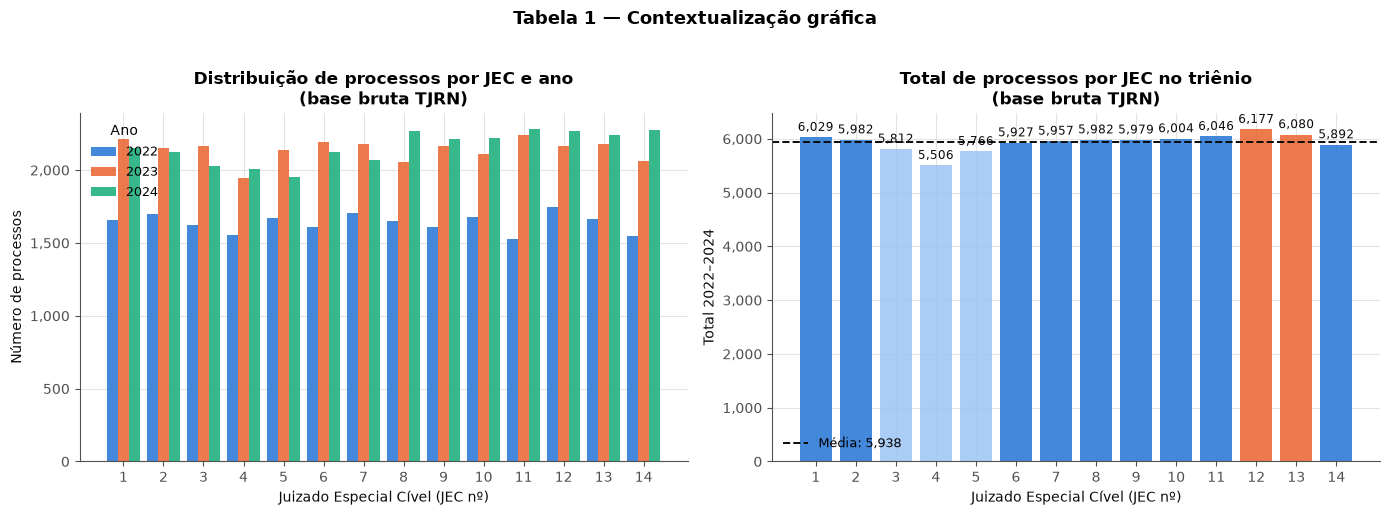

In [14]:
# ── Gráfico auxiliar: distribuição de processos por JEC e ano ─────────────────
# Não numerado na monografia, mas útil para contextualizar a Tabela 1 e
# verificar a homogeneidade da carteira entre os juizados.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Painel esquerdo: barras agrupadas por ano ──────────────────────────────
anos_lista = [2022, 2023, 2024]
x = np.arange(1, 15)          # JECs 1 a 14
largura = 0.27
cores_anos = [CORES[0], CORES[1], CORES[2]]

for i, (ano, cor) in enumerate(zip(anos_lista, cores_anos)):
    vals = [
        pop_bruta.loc[pop_bruta['ano'].eq(ano) & pop_bruta['JEC_numero'].eq(j)].shape[0]
        for j in range(1, 15)
    ]
    deslocamento = (i - 1) * largura
    barras = axes[0].bar(x + deslocamento, vals, largura,
                         label=str(ano), color=cor, alpha=0.88)

axes[0].set_xlabel('Juizado Especial Cível (JEC nº)')
axes[0].set_ylabel('Número de processos')
axes[0].set_title('Distribuição de processos por JEC e ano\n(base bruta TJRN)')
axes[0].set_xticks(x)
axes[0].set_xticklabels([str(j) for j in range(1, 15)])
axes[0].legend(title='Ano', fontsize=9)
axes[0].yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f'{int(v):,}')
)

# ── Painel direito: total por JEC (barras simples com média) ──────────────
totais_jec = (
    pop_bruta.groupby('JEC_numero').size().reindex(range(1, 15)).fillna(0)
)
media_jec = totais_jec.mean()
cores_barra = [
    COR_DESTAQUE if v > media_jec * 1.02
    else (COR_SECUNDARIA if v < media_jec * 0.98 else COR_PRINCIPAL)
    for v in totais_jec
]
barras2 = axes[1].bar(totais_jec.index, totais_jec.values,
                      color=cores_barra, alpha=0.88)
axes[1].axhline(media_jec, color=TINTA, linewidth=1.4,
                linestyle='--', label=f'Média: {media_jec:,.0f}')
anotar_barras(axes[1], barras2, formato='{:,.0f}', fontsize=8.5)
axes[1].set_xlabel('Juizado Especial Cível (JEC nº)')
axes[1].set_ylabel('Total 2022–2024')
axes[1].set_title('Total de processos por JEC no triênio\n(base bruta TJRN)')
axes[1].set_xticks(range(1, 15))
axes[1].legend(fontsize=9)
axes[1].yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda v, _: f'{int(v):,}')
)

plt.suptitle('Tabela 1 — Contextualização gráfica', fontsize=13,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.2 Interpretação da Tabela 1

A distribuição dos processos entre as 14 unidades judiciárias é **bastante
homogênea**: nenhum juizado concentra participação desproporcionalmente alta
no total do triênio. O volume individual varia de cerca de 5.500 a 6.200
processos por unidade no período.

No que se refere à distribuição **temporal**, observa-se que:

- **2022** concentra aproximadamente **27,6%** do total do triênio;
- **2023** representa cerca de **36,1%** — o ano de maior volume de
  distribuições;
- **2024** responde por aproximadamente **36,3%** do período.

O crescimento observado de 2022 para 2023 e a manutenção do patamar em 2024
são consistentes com o movimento nacional de aumento da litigiosidade
registrado pelo CNJ. O relatório *Justiça em Números 2024* apontou 83,8
milhões de processos pendentes no Judiciário brasileiro ao final de 2023 —
o maior valor da série histórica de medição.

> **Sobre a população de referência:** a base bruta (83.139 registros com ANO
> válido) foi depurada em três etapas — remoção de duplicidades (20.739),
> exclusão de execuções extrajudiciais (6.903) e identificação de processos
> sem advogado (9.001) — resultando em **50.320 processos**, que constituem
> a população de referência da pesquisa e sobre a qual foi calculado o tamanho
> amostral (Seção 4).

---

## 4. Desenho Amostral

### 4.1 Dimensionamento e estratificação

A amostragem adotada é **probabilística estratificada por ano de distribuição**,
com seleção aleatória dos processos por meio da função `ALEATÓRIOENTRE()`
do Excel. O estrato é o ano (2022, 2023 e 2024), e dentro de cada estrato
os processos foram selecionados aleatoriamente com probabilidade uniforme.

**Cálculo do tamanho amostral:**

$$
n = \frac{z^2 \cdot p(1-p)}{e^2} \cdot \frac{N}{N + \frac{z^2 \cdot p(1-p)}{e^2} - 1}
$$

Parâmetros adotados:

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Nível de confiança | 95% → z = 1,96 | Padrão para ciências sociais empíricas |
| Proporção conservadora | p = 0,5 | Maximiza o tamanho amostral |
| Margem de erro planejada | e = 5% | Padrão para pesquisas sociais |
| População (N) | 50.320 | Base consolidada após depuração |

A correção de **população finita** foi aplicada, resultando em
margem de erro efetiva de **±4,0 p.p.** — melhor que os 5% planejados,
em razão da fração amostral de 595/50.320 ≈ 1,2%.

**Estratificação proporcional ao peso anual na população:**
os 595 processos foram distribuídos entre os três estratos de forma
proporcional ao número de processos de cada ano na base consolidada
(fração de amostragem aproximadamente constante entre os estratos).

In [15]:
# ── Parâmetros do dimensionamento amostral ────────────────────────────────────
Z       = 1.96    # quantil normal para IC 95%
P       = 0.50    # proporção conservadora (maximiza n)
E_PLAN  = 0.05    # margem de erro planejada (5%)
N_REF   = 50_320  # população de referência (base consolidada)
N_AMST  = 595     # tamanho amostral efetivo

# ── n teórico sem correção de população finita ───────────────────────────────
n_sem_corr = (Z**2 * P * (1 - P)) / E_PLAN**2
print(f'n teórico sem correção   : {n_sem_corr:.0f}')

# ── n teórico com correção de população finita ───────────────────────────────
n_com_corr = n_sem_corr / (1 + (n_sem_corr - 1) / N_REF)
print(f'n teórico com correção   : {n_com_corr:.0f}')

# ── Margem de erro efetiva com a amostra real (n = 595) ──────────────────────
# e_efetiva = z * sqrt(p(1-p)/n) * sqrt((N-n)/(N-1))
e_efetiva = Z * np.sqrt(P * (1 - P) / N_AMST) * np.sqrt((N_REF - N_AMST) / (N_REF - 1))
print(f'Margem de erro efetiva   : ±{e_efetiva*100:.2f} p.p.'
      f' (planejada: ±{E_PLAN*100:.1f} p.p.)')

# ── Fração amostral ───────────────────────────────────────────────────────────
fracao = N_AMST / N_REF
print(f'Fração amostral          : {N_AMST}/{N_REF} = {fracao:.4f} ({fracao*100:.2f}%)')

# ── Distribuição do n por ano na população (base consolidada com ANO válido) ──
pop_por_ano = {2022: 13_968, 2023: 18_391, 2024: 16_435}
total_pop   = sum(pop_por_ano.values())
print()
print('Estratificação proporcional (referência):')
print(f'  {"Ano":<6} {"N pop":>8} {"% pop":>8} {"n esperado":>12} {"n real":>8}')
n_real_por_ano = dados['ano'].value_counts().sort_index().to_dict()
for ano, n_pop in sorted(pop_por_ano.items()):
    prop   = n_pop / total_pop
    n_esp  = round(N_AMST * prop)
    n_real = n_real_por_ano.get(ano, 0)
    print(f'  {ano:<6} {n_pop:>8,} {prop*100:>7.1f}% {n_esp:>12} {n_real:>8}')
print(f'  {"Total":<6} {total_pop:>8,} {"100,0%":>8} {N_AMST:>12} {sum(n_real_por_ano.values()):>8}')

n teórico sem correção   : 384
n teórico com correção   : 381
Margem de erro efetiva   : ±3.99 p.p. (planejada: ±5.0 p.p.)
Fração amostral          : 595/50320 = 0.0118 (1.18%)

Estratificação proporcional (referência):
  Ano       N pop    % pop   n esperado   n real
  2022     13,968    28.6%          170      194
  2023     18,391    37.7%          224      211
  2024     16,435    33.7%          200      190
  Total    48,794   100,0%          595      595


In [16]:
# ── Tabela 2: distribuição da amostra por unidade judiciária e ano ─────────────

# Tabela cruzada: unidade × ano (contagem de processos amostrados)
tab2_raw = pd.crosstab(
    dados['unidade'],
    dados['ano'],
    margins=True,
    margins_name='Total',
)

# Ordenar por JEC_numero (1 a 14) + Total no fim
ordem_jec_dados = (
    dados[['unidade', 'JEC_numero']]
    .drop_duplicates()
    .sort_values('JEC_numero')['unidade']
    .tolist()
)
tab2 = tab2_raw.reindex(ordem_jec_dados + ['Total'])
tab2.columns = ['2022', '2023', '2024', 'Total']
tab2.index.name = 'Unidade Judiciária'

# Verificar totais por ano
assert tab2.loc['Total', '2022'] == 194, f"2022: esperado 194, obtido {tab2.loc['Total','2022']}"
assert tab2.loc['Total', '2023'] == 211, f"2023: esperado 211, obtido {tab2.loc['Total','2023']}"
assert tab2.loc['Total', '2024'] == 190, f"2024: esperado 190, obtido {tab2.loc['Total','2024']}"
assert tab2.loc['Total', 'Total'] == 595, f"Total: esperado 595, obtido {tab2.loc['Total','Total']}"
print('Asserts Tabela 2: OK')

# Exibir tabela estilizada
display(
    tab2.style
    .set_caption(
        'Tabela 2 – Distribuição da amostra por unidade judiciária e ano '
        '(n = 595) | Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).'
    )
    .format('{:,.0f}')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'right'), ('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'background-color: #eef3fc' if r % 2 == 0 else ''
        for r in range(len(col))
    ])
    .apply(lambda col: [
        'font-weight: bold; background-color: #d0e3f7'
        if idx == 'Total' else ''
        for idx in col.index
    ])
    .apply(lambda row: [
        'font-weight: bold; background-color: #d0e3f7'
        if col == 'Total' else ''
        for col in row.index
    ], axis=1)
)

Asserts Tabela 2: OK


,2022,2023,2024,Total
Unidade Judiciária,,,,
1º JUIZADO ESPECIAL CÍVEL,17,14,12,43
2º JUIZADO ESPECIAL CÍVEL,19,20,16,55
3º JUIZADO ESPECIAL CÍVEL,17,16,10,43
4º JUIZADO ESPECIAL CÍVEL,13,10,16,39
5º JUIZADO ESPECIAL CÍVEL,10,11,12,33
6º JUIZADO ESPECIAL CÍVEL,10,19,19,48
7º JUIZADO ESPECIAL CÍVEL,11,15,13,39
8º JUIZADO ESPECIAL CÍVEL,14,13,15,42
9º JUIZADO ESPECIAL CÍVEL,17,17,10,44


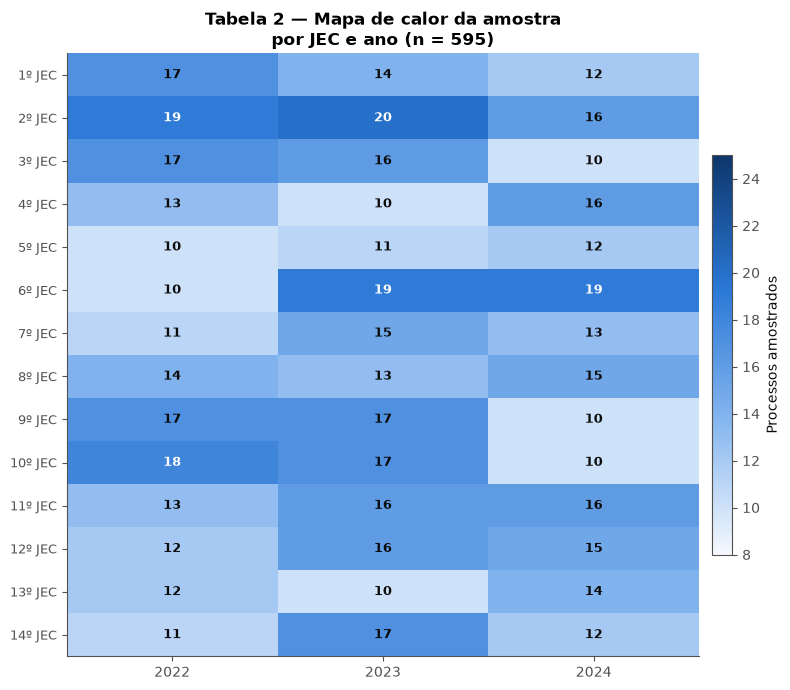

In [17]:
# ── Mapa de calor: amostra por JEC e ano ─────────────────────────────────────
# Visualiza a distribuição interna da Tabela 2, facilitando a identificação
# de células com n muito baixo (potencial fragilidade estatística).

# Matriz sem as linhas/colunas de Total
matriz_heat = tab2.drop(index='Total', columns='Total').astype(float)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(
    matriz_heat.values,
    cmap=MAPA_SEQUENCIAL,
    aspect='auto',
    vmin=8, vmax=25,
)
plt.colorbar(im, ax=ax, label='Processos amostrados', fraction=0.03, pad=0.02)

# Rótulos dos eixos
ax.set_xticks(range(3))
ax.set_xticklabels(['2022', '2023', '2024'], fontsize=10)
ax.set_yticks(range(len(matriz_heat)))
ax.set_yticklabels(
    [f'{j+1}º JEC' for j in range(14)],
    fontsize=9,
)
ax.set_title(
    'Tabela 2 — Mapa de calor da amostra\npor JEC e ano (n = 595)',
    fontweight='bold',
)

# Anotar cada célula com o valor
for i in range(len(matriz_heat)):
    for j in range(3):
        val = int(matriz_heat.iloc[i, j])
        cor_texto = 'white' if val >= 18 else TINTA
        ax.text(j, i, str(val), ha='center', va='center',
                fontsize=9, color=cor_texto, fontweight='bold')

ax.grid(visible=False)
plt.tight_layout()
plt.show()

In [18]:
# ── Tabela 3: distribuição da amostra por classe processual ───────────────────
# A monografia documenta concentração quase absoluta no procedimento típico
# do microssistema dos Juizados (PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL).
# As demais classes decorrem de reclassificações automáticas do PJe.

CLASSE_PRINC = 'PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL'
CLASSES_RESIDUAIS = [
    'REINTEGRAÇÃO / MANUTENÇÃO DE POSSE',
    'DESPEJO POR FALTA DE PAGAMENTO CUMULADO COM COBRANÇA',
    'PROCEDIMENTO DO JUIZADO ESPECIAL DA FAZENDA PÚBLICA',
]

# Criar variável de classe resumida para esta tabela
dados['classe_tab3'] = dados['classe'].apply(
    lambda c: c if c in [CLASSE_PRINC, 'CUMPRIMENTO DE SENTENÇA',
                         'CUMPRIMENTO PROVISÓRIO DE SENTENÇA',
                         'PROCEDIMENTO COMUM CÍVEL'] + CLASSES_RESIDUAIS
    else 'Outras'
)

# Frequência e percentual
freq3 = (
    dados['classe_tab3']
    .value_counts()
    .reset_index()
)
freq3.columns = ['Classe Processual', 'n']
freq3['%'] = (freq3['n'] / len(dados) * 100).round(1)
freq3['% acumulado'] = freq3['%'].cumsum().round(1)

# Agrupar as três classes residuais em uma única linha
mask_res = freq3['Classe Processual'].isin(CLASSES_RESIDUAIS)
if mask_res.sum() > 1:
    n_res   = freq3.loc[mask_res, 'n'].sum()
    pct_res = (n_res / len(dados) * 100).round(1)
    freq3 = freq3[~mask_res]
    linha_res = pd.DataFrame([[
        'Outras classes residuais\n(Reintegração, Despejo e JEC Fazenda Pública)',
        n_res, pct_res, None
    ]], columns=freq3.columns)
    freq3 = pd.concat([freq3, linha_res], ignore_index=True)
    freq3['% acumulado'] = freq3['%'].cumsum().round(1)

# Exibir tabela
assert freq3['n'].sum() == 595, f"Soma n: {freq3['n'].sum()}"
print('Assert Tabela 3: OK')

display(
    freq3.style
    .set_caption(
        'Tabela 3 – Distribuição da amostra por classe processual (n = 595) | '
        'Fonte: elaborada pela autora (2025).'
    )
    .format({'n': '{:,.0f}', '%': '{:.1f}', '% acumulado': '{:.1f}'})
    .bar(subset=['%'], color=COR_SECUNDARIA, vmin=0, vmax=100)
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px')]},
        {'selector': 'td',
         'props': [('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'background-color: #eef3fc' if r % 2 == 0 else ''
        for r in range(len(col))
    ])
    .hide(axis='index')
)

Assert Tabela 3: OK


Classe Processual,n,%,% acumulado
PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL,528,88.7,88.7
CUMPRIMENTO DE SENTENÇA,58,9.7,98.4
PROCEDIMENTO COMUM CÍVEL,4,0.7,99.1
CUMPRIMENTO PROVISÓRIO DE SENTENÇA,2,0.3,99.4
"Outras classes residuais (Reintegração, Despejo e JEC Fazenda Pública)",3,0.5,99.9


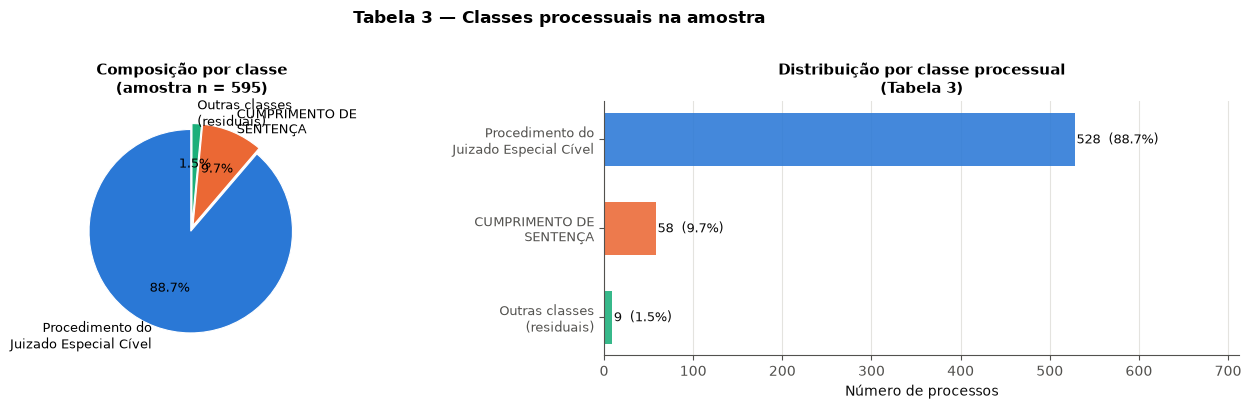

In [19]:
# ── Gráfico: composição da amostra por classe processual (Tabela 3) ───────────

# Preparar dados do gráfico (as 3-4 categorias mais relevantes)
CLASSE_PRINC = 'PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL'
contagem_classe = dados['classe'].value_counts()

# Agrupar classes com < 5 ocorrências em "Outras"
limite = 5
principais = contagem_classe[contagem_classe >= limite]
outras_n   = contagem_classe[contagem_classe < limite].sum()
if outras_n > 0:
    outras_s = pd.Series({'Outras classes\n(residuais)': outras_n})
    principais = pd.concat([principais, outras_s])

# Rótulos resumidos para o gráfico
rotulos_graf = [
    quebrar(c, 22) if c != CLASSE_PRINC
    else 'Procedimento do\nJuizado Especial Cível'
    for c in principais.index
]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# ── Painel esquerdo: pizza ────────────────────────────────────────────────
wedge_props = dict(linewidth=0.8, edgecolor='white')
explode = [0.03] * len(principais)
axes[0].pie(
    principais.values,
    labels=rotulos_graf,
    autopct=lambda p: f'{p:.1f}%' if p > 1 else '',
    colors=CORES[:len(principais)],
    wedgeprops=wedge_props,
    explode=explode,
    startangle=90,
    textprops={'fontsize': 9},
)
axes[0].set_title('Composição por classe\n(amostra n = 595)', fontsize=11)

# ── Painel direito: barras horizontais ───────────────────────────────────
y = np.arange(len(principais))
barras_h = axes[1].barh(
    y, principais.values,
    color=CORES[:len(principais)],
    alpha=0.88, height=0.6,
)
for barra, val in zip(barras_h, principais.values):
    axes[1].text(
        val + 2, barra.get_y() + barra.get_height() / 2,
        f'{val}  ({val/595*100:.1f}%)',
        va='center', fontsize=9, color=TINTA,
    )
axes[1].set_yticks(y)
axes[1].set_yticklabels(rotulos_graf, fontsize=9)
axes[1].set_xlabel('Número de processos')
axes[1].set_title('Distribuição por classe processual\n(Tabela 3)', fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlim(0, principais.max() * 1.35)
axes[1].grid(axis='y', visible=False)

plt.suptitle('Tabela 3 — Classes processuais na amostra', fontsize=12,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [20]:
# ── Tabela 4 / Quadro 3: variáveis do estudo (reprodução estilizada) ──────────
# Construída a partir do mapeamento COLUNAS_AMOSTRA definido na Seção 2.
# Apresenta código, fase, nome, descrição e tipo de cada variável.

# Descrições detalhadas (retiradas do Apêndice B do projeto e Quadro 3 da monografia)
DESCRICOES_VARIAVEIS = {
    # Fase I — Exclusão
    'F1_A': 'Ações com pessoa física no polo passivo',
    'F1_B': 'Ausência de grande litigante no polo passivo',
    'F1_C': 'Causas ajuizadas sem representação por advogado (atermação)',
    'F1_D': 'Processos suspensos por determinação judicial',
    'F1_E': 'Processos erroneamente distribuídos aos Juizados Especiais',
    'F1_F': 'Pessoa jurídica no polo ativo',
    # Fase II — Indicativos na petição inicial e curso do processo
    'F2_01': 'Petição inicial vaga ou genérica, sem exposição de fatos específicos',
    'F2_02': 'Ausência de documentos mínimos que comprovem a relação jurídica alegada',
    'F2_03': 'Documentos apresentados sem conexão com a causa de pedir',
    'F2_04': 'Pedido explícito de dispensa da audiência de conciliação',
    'F2_05': 'Ação proposta em comarca distinta do domicílio das partes ou local do fato',
    'F2_06': 'Documentos com dados incompletos, ilegíveis ou em nome de terceiros',
    'F2_07': 'Pedidos vagos, hipotéticos ou sem relação lógica com a causa de pedir',
    'F2_08': 'Demanda idêntica anterior sem declaração de prevenção',
    'F2_09': 'Procuração com falhas ou outorgada por mandante já falecido',
    'F2_10': 'Procuração com assinatura eletrônica não qualificada (fora do padrão ICP-Brasil)',
    'F2_11': 'Sede do advogado não coincide com a comarca da ação ou domicílio das partes',
    'F2_12': 'Valor atribuído à causa elevado e aleatório, sem relação com o pedido',
    'F2_13': 'Classe ou assunto processual incorretamente cadastrado',
    'F2_14': 'Desistência ou abandono após indeferimento de medida liminar',
    'F2_15': 'Desistência ou abandono após notificação para comprovação dos fatos',
    'F2_16': 'Desistência ou abandono após apresentação de contestação com documentos',
    'F2_17': 'Contrato de honorários com valor superior a 30% do pedido',
    # Fase III — Verificação sistêmica de massificação
    'F3_18': 'Multiplicidade de ações sobre o mesmo tema pela mesma parte autora',
    'F3_19': 'Petições iniciais idênticas ou padronizadas em massa',
    'F3_20': 'Concentração de elevado volume de demandas sob o patrocínio do mesmo advogado',
}

CATEGORIAS_VARIAVEIS = {
    'F1_A': 'Natureza do processo',
    'F1_B': 'Natureza do processo',
    'F1_C': 'Natureza do processo',
    'F1_D': 'Natureza do processo',
    'F1_E': 'Natureza do processo',
    'F1_F': 'Natureza do processo',
    'F2_01': 'Qualidade da petição inicial',
    'F2_02': 'Qualidade da petição inicial',
    'F2_03': 'Qualidade da petição inicial',
    'F2_04': 'Qualidade da petição inicial',
    'F2_05': 'Qualidade da petição inicial',
    'F2_06': 'Qualidade da petição inicial',
    'F2_07': 'Qualidade da petição inicial',
    'F2_08': 'Qualidade da petição inicial',
    'F2_09': 'Documentação e representação',
    'F2_10': 'Documentação e representação',
    'F2_11': 'Documentação e representação',
    'F2_12': 'Qualidade da petição inicial',
    'F2_13': 'Qualidade da petição inicial',
    'F2_14': 'Comportamento no curso do processo',
    'F2_15': 'Comportamento no curso do processo',
    'F2_16': 'Comportamento no curso do processo',
    'F2_17': 'Comportamento no curso do processo',
    'F3_18': 'Massificação sistêmica',
    'F3_19': 'Massificação sistêmica',
    'F3_20': 'Massificação sistêmica',
}

# F1_D foi retirada no curso da pesquisa (monografia, sec. 3.3.1); o Quadro 3
# lista exatamente 25 variaveis = 5 F1 + 17 F2 + 3 F3.
COLS_F1_QUADRO = [c for c in COLS_F1 if c != 'F1_D']

# Montar DataFrame do quadro de variáveis
quadro_cols = COLS_F1_QUADRO + COLS_F2 + COLS_F3
quadro_df = pd.DataFrame({
    'Código': quadro_cols,
    'Fase': (['I'] * len(COLS_F1_QUADRO)
             + ['II'] * len(COLS_F2)
             + ['III'] * len(COLS_F3)),
    'Categoria': [CATEGORIAS_VARIAVEIS[c] for c in quadro_cols],
    'Nome da Variável': [ROTULOS.get(c, c) for c in quadro_cols],
    'Descrição': [DESCRICOES_VARIAVEIS.get(c, '—') for c in quadro_cols],
    'Tipo': ['Booleana (Sim/Não)'] * len(quadro_cols),
    'Critério na F.': (['Exclusão (se Sim → processo excluído)'] * len(COLS_F1_QUADRO)
                       + ['Indício (≥ 1 Sim → avança à Fase III)'] * len(COLS_F2)
                       + ['Massificação (combinação F3_19+F3_20 → indício; todas → certeza)'] * len(COLS_F3)),
})

# Frequência observada na amostra
quadro_df['Sim (n)'] = [dados[c].sum() for c in quadro_cols]
quadro_df['Sim (%)'] = (quadro_df['Sim (n)'] / 595 * 100).round(1)

# Exibir tabela
display(
    quadro_df.style
    .set_caption(
        'Tabela 4 (Quadro 3) – Variáveis observacionais do estudo (n = 25) | '
        'Fonte: elaborada pela autora, 2025.'
    )
    .format({'Sim (n)': '{:,.0f}', 'Sim (%)': '{:.1f}'})
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '10px')]},
        {'selector': 'td',
         'props': [('font-size', '10px'), ('vertical-align', 'top')]},
    ])
    .apply(lambda col: [
        # Fundo azul claro para Fase I, branco para II, verde claro para III
        ('background-color: #fff3e0' if quadro_df.loc[r, 'Fase'] == 'I'
         else 'background-color: #eef3fc' if quadro_df.loc[r, 'Fase'] == 'II'
         else 'background-color: #e8f5e9')
        for r in quadro_df.index
    ])
    .bar(subset=['Sim (%)'], color=COR_SECUNDARIA, vmin=0, vmax=25)
    .hide(axis='index')
)

Código,Fase,Categoria,Nome da Variável,Descrição,Tipo,Critério na F.,Sim (n),Sim (%)
F1_A,I,Natureza do processo,Ações de pessoa física no polo passivo,Ações com pessoa física no polo passivo,Booleana (Sim/Não),Exclusão (se Sim → processo excluído),79,13.3
F1_B,I,Natureza do processo,Ausência de grande litigante no polo passivo,Ausência de grande litigante no polo passivo,Booleana (Sim/Não),Exclusão (se Sim → processo excluído),28,4.7
F1_C,I,Natureza do processo,Causas ajuizadas sem advogado (atermação),Causas ajuizadas sem representação por advogado (atermação),Booleana (Sim/Não),Exclusão (se Sim → processo excluído),16,2.7
F1_E,I,Natureza do processo,Distribuição incorreta,Processos erroneamente distribuídos aos Juizados Especiais,Booleana (Sim/Não),Exclusão (se Sim → processo excluído),12,2.0
F1_F,I,Natureza do processo,Parte PJ no polo ativo,Pessoa jurídica no polo ativo,Booleana (Sim/Não),Exclusão (se Sim → processo excluído),17,2.9
F2_01,II,Qualidade da petição inicial,Petição vaga/genérica,"Petição inicial vaga ou genérica, sem exposição de fatos específicos",Booleana (Sim/Não),Indício (≥ 1 Sim → avança à Fase III),98,16.5
F2_02,II,Qualidade da petição inicial,Ausência de documentos essenciais,Ausência de documentos mínimos que comprovem a relação jurídica alegada,Booleana (Sim/Não),Indício (≥ 1 Sim → avança à Fase III),96,16.1
F2_03,II,Qualidade da petição inicial,Documentos sem relação com a causa de pedir,Documentos apresentados sem conexão com a causa de pedir,Booleana (Sim/Não),Indício (≥ 1 Sim → avança à Fase III),1,0.2
F2_04,II,Qualidade da petição inicial,Pedido de dispensa de audiência,Pedido explícito de dispensa da audiência de conciliação,Booleana (Sim/Não),Indício (≥ 1 Sim → avança à Fase III),18,3.0
F2_05,II,Qualidade da petição inicial,Foro inadequado,Ação proposta em comarca distinta do domicílio das partes ou local do fato,Booleana (Sim/Não),Indício (≥ 1 Sim → avança à Fase III),3,0.5


### 4.2 Interpretação do desenho amostral

**Representatividade temporal.** A amostra de 595 processos reflete
adequadamente o peso de cada ano na população depurada. A sub-amostra de
**194 processos para 2022** (32,6% da amostra) é proporcional aos 27,8% da
população consolidada de 2022; os **211 de 2023** (35,5%) e os **190 de 2024**
(31,9%) seguem o mesmo padrão. Pequenos desvios da proporcionalidade exata
decorrem do arredondamento para números inteiros.

**Homogeneidade entre unidades.** Cada um dos 14 Juizados contribui com 33
a 55 processos, o que representa entre 5,5% e 9,2% do total amostral.
A distribuição é razoavelmente homogênea entre as unidades, conferindo
adequada representatividade para as análises desagregadas por JEC.
Subamostras menores (ex.: 5º e 13º JECs, com 33 e 36 processos,
respectivamente) impõem cautela adicional nas comparações pareadas.

**Composição por classe.** O predomínio de **88,7%** de processos na classe
"Procedimento do Juizado Especial Cível" é coerente com a natureza das
unidades estudadas. As demais classes (Cumprimento de Sentença: 9,7%;
Procedimento Comum Cível: 0,7%; e residuais: 0,7%) decorrem de
reclassificações automáticas do PJe ao longo do trâmite processual e
foram mantidas na amostra por sua distribuição aleatória, sem viés de seleção.

**Variáveis com zero ocorrências.** As variáveis **F2_07**, **F2_12**,
**F2_15** e **F2_16** não apresentaram nenhuma ocorrência na amostra de 595
processos. Isso pode refletir: (a) ausência efetiva dessas condutas no
universo estudado; (b) limitações observacionais do canal de consulta ao PJe;
ou (c) mudança de comportamento dos litigantes — em especial para F2_15 e
F2_16, que descrevem desistências após contestação, sancionadas como
litigância de má-fé em notas técnicas recentes dos centros de inteligência.
Essas variáveis serão excluídas das análises bivariada e multivariada, por
serem constantes e, portanto, não informativas para modelos preditivos.

---

## 5. Resultados Descritivos Gerais

Esta seção apresenta os achados descritivos da pesquisa, percorrendo o funil
de classificação dos 595 processos amostrados, as estimativas pontuais e
intervalares projetadas para a população, o detalhamento das combinações
das variáveis sistêmicas da Fase III e a distribuição do fenômeno por ano
de distribuição e por unidade judiciária.

> **Nota sobre dupla contagem:** os 30 processos classificados com *certeza*
> estão integralmente contidos nos 105 com *indício* (pois certeza implica
> as mesmas condições de indício, acrescidas de F3_18). As duas categorias
> **não devem ser somadas**; sempre que se reporta a prevalência do fenômeno
> em sentido amplo, usa-se o número de *indício* (105).

In [21]:
# ── Recarregar o dataset curado (produzido pela Seção 2) ─────────────────────
# Necessário porque cada seção do notebook é autocontida após a execução.
import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

ARQUIVO_PKL = Path('dat/estcaso_lide_pred/processado/hadja_amostra_limpa.pkl')
dados = pd.read_pickle(ARQUIVO_PKL)

# ── Subconjuntos usados nesta seção ──────────────────────────────────────────
# Fase III: processos que avançaram com ao menos um indício na Fase II
dados_f3 = dados[dados['Avancou_F3']].copy()   # n = 233

# ── Parâmetros populacionais e amostrais ──────────────────────────────────────
N_AMST  = 595       # tamanho da amostra
N_POP   = 50_320    # população depurada (base consolidada)
ALPHA   = 0.05      # nível de significância para todos os IC

# ── Constantes de contagem (verificadas pelos asserts da Seção 2) ─────────────
N_EXCLUIDOS = int(dados['Excluido_F1'].sum())    # 151
N_FASE_II   = N_AMST - N_EXCLUIDOS              # 444
N_FASE_III  = int(dados['Avancou_F3'].sum())     # 233
N_SEM_IND   = N_FASE_II - N_FASE_III            # 211
N_INDICIO   = int(dados['Indicio'].sum())        # 105
N_CERTEZA   = int(dados['Certeza'].sum())        # 30
N_IND_ONLY  = N_INDICIO - N_CERTEZA             # 75 (indício sem certeza)
N_DEMAIS_F3 = N_FASE_III - N_INDICIO            # 128

# ── Verificação de partição ───────────────────────────────────────────────────
assert N_EXCLUIDOS + N_SEM_IND + N_DEMAIS_F3 + N_IND_ONLY + N_CERTEZA == N_AMST, \
    'Partição não fecha em 595!'

print('Partição dos 595 processos:')
for label, val in [
    ('Excluídos na Fase I',          N_EXCLUIDOS),
    ('Sem indicativo na Fase II',    N_SEM_IND),
    ('Demais processos na Fase III', N_DEMAIS_F3),
    ('Indício (sem certeza)',        N_IND_ONLY),
    ('Certeza',                      N_CERTEZA),
]:
    print(f'  {label:<40}: {val:>4}  ({val/N_AMST*100:.1f}%)')
print(f'  {"TOTAL":<40}: {N_AMST:>4}')

Partição dos 595 processos:
  Excluídos na Fase I                     :  151  (25.4%)
  Sem indicativo na Fase II               :  211  (35.5%)
  Demais processos na Fase III            :  128  (21.5%)
  Indício (sem certeza)                   :   75  (12.6%)
  Certeza                                 :   30  (5.0%)
  TOTAL                                   :  595


### 5.1 Fluxo dos processos pelas três fases (Gráficos 1 e 2)

A metodologia em funil revela o afunilamento progressivo da amostra ao longo
das três fases de triagem. **151 processos (25,4%)** foram eliminados na
Fase I por não apresentarem as condições mínimas para análise de litigância
predatória pelo polo ativo. **211 processos (35,5%)** que avançaram à Fase II
não apresentaram nenhum dos indicativos de abusividade listados na Recomendação
CNJ n.º 159/2024, sendo encerrada ali a sua análise. Dos **233 processos
(39,2%)** que chegaram à Fase III, **105** preencheram o critério de indício
e **30** o critério de certeza.

O dado dos 211 processos que não apresentaram qualquer irregularidade na
Fase II é relevante do ponto de vista metodológico: ele corrobora a conjectura
presente na Recomendação n.º 159/2024, segundo a qual as demandas legítimas
— mesmo dentro do ecossistema dos juizados — não ostentam, em regra, os
marcadores formais de abusividade identificados nas variáveis F2.

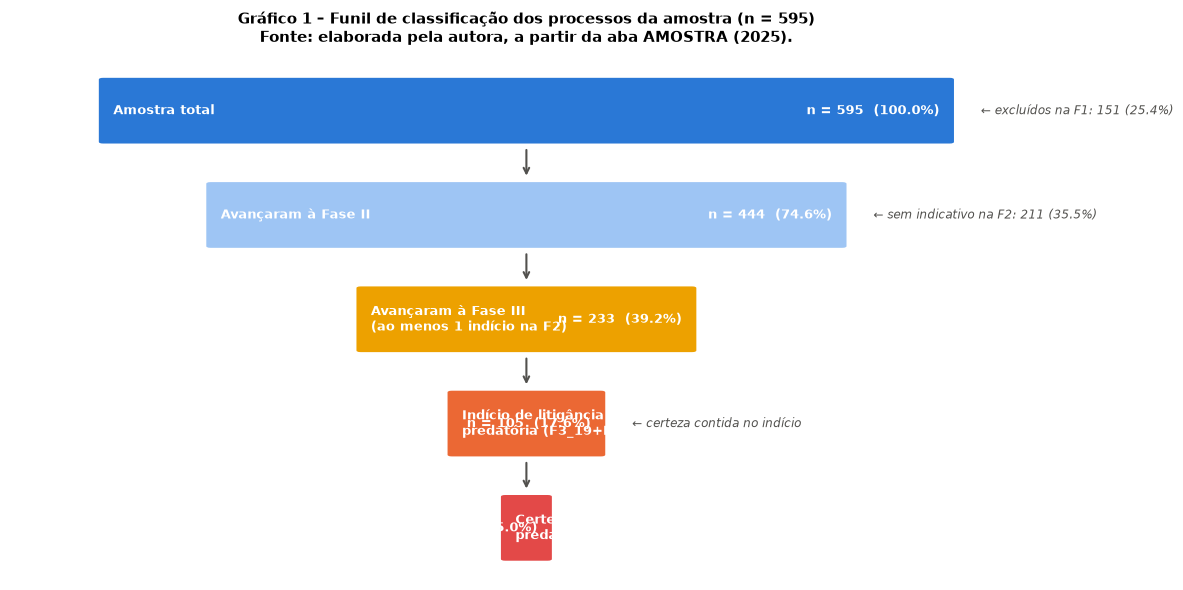

In [22]:
# ── Gráfico 1: Funil de classificação dos processos ──────────────────────────
# Representa o afunilamento progressivo da amostra pelas três fases.
# Layout: barras horizontais decrescentes, com setas indicando o fluxo.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_axis_off()

# Definição dos estágios do funil
estagios = [
    # (rótulo, n, pct_sobre_595, cor, y_centro)
    ('Amostra total',            595,  100.0, '#2a78d6',  0.90),
    ('Avançaram à Fase II',      444,   74.6, '#9ec5f4',  0.70),
    ('Avançaram à Fase III\n(ao menos 1 indício na F2)',
                                 233,   39.2, '#eda100',  0.50),
    ('Indício de litigância\npredatória (F3_19+F3_20)',
                                 105,   17.6, '#eb6834',  0.30),
    ('Certeza de litigância\npredatória (F3_18+F3_19+F3_20)',
                                  30,    5.0, '#e34948',  0.10),
]

larguras = [s[1] / 595 for s in estagios]   # proporção de 0 a 1
L_MAX    = 0.82   # largura máxima do funil no plot (em unidades de axes)
X_CENTER = 0.50

for i, (label, n_val, pct, cor, y) in enumerate(estagios):
    larg  = larguras[i] * L_MAX
    x0    = X_CENTER - larg / 2
    # Barra horizontal
    rect = mpatches.FancyBboxPatch(
        (x0, y - 0.06), larg, 0.12,
        boxstyle='round,pad=0.005',
        facecolor=cor, edgecolor='white', linewidth=1.5,
        transform=ax.transAxes, clip_on=False,
    )
    ax.add_patch(rect)
    # Rótulo dentro da barra (esquerda)
    ax.text(x0 + 0.01, y, label,
            transform=ax.transAxes, va='center', ha='left',
            fontsize=9, color='white', fontweight='bold')
    # Contagem e percentual (direita)
    ax.text(x0 + larg - 0.01, y, f'n = {n_val:,}  ({pct:.1f}%)',
            transform=ax.transAxes, va='center', ha='right',
            fontsize=9, color='white', fontweight='bold')
    # Seta de fluxo entre estágios
    if i < len(estagios) - 1:
        ax.annotate('',
            xy=(X_CENTER, estagios[i+1][4] + 0.07),
            xytext=(X_CENTER, y - 0.07),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color=TINTA_2, lw=1.5),
        )
    # Anotação lateral: excluídos ou "contido em"
    if i == 0:
        ax.text(X_CENTER + larguras[0]*L_MAX/2 + 0.03, y,
                f'← excluídos na F1: {N_EXCLUIDOS} ({N_EXCLUIDOS/595*100:.1f}%)',
                transform=ax.transAxes, va='center', ha='left',
                fontsize=8.5, color=TINTA_2, style='italic')
    if i == 1:
        ax.text(X_CENTER + larguras[1]*L_MAX/2 + 0.03, y,
                f'← sem indicativo na F2: {N_SEM_IND} ({N_SEM_IND/595*100:.1f}%)',
                transform=ax.transAxes, va='center', ha='left',
                fontsize=8.5, color=TINTA_2, style='italic')
    if i == 3:
        ax.text(X_CENTER + larguras[3]*L_MAX/2 + 0.03, y,
                f'← certeza contida no indício',
                transform=ax.transAxes, va='center', ha='left',
                fontsize=8.5, color=TINTA_2, style='italic')

ax.set_title(
    'Gráfico 1 – Funil de classificação dos processos da amostra (n = 595)\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold', pad=12,
)
plt.tight_layout()
plt.show()

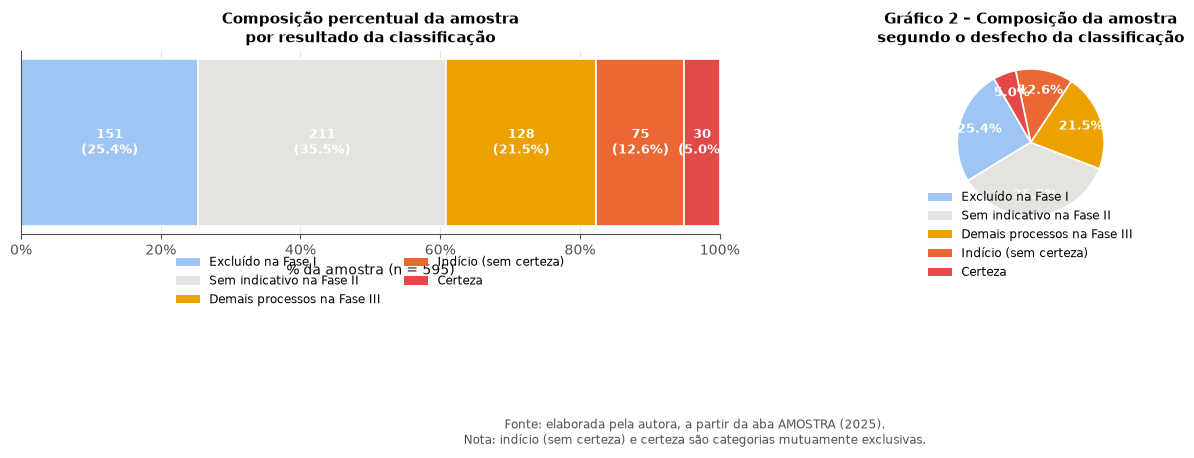

In [23]:
# ── Gráfico 2: Composição percentual da amostra por categoria ─────────────────
# Cinco categorias mutuamente exclusivas — sem dupla contagem.
# Layout: barra empilhada horizontal + gráfico de pizza lado a lado.

categorias = [
    ('Excluído na Fase I',          N_EXCLUIDOS, '#9ec5f4'),
    ('Sem indicativo na Fase II',   N_SEM_IND,   '#e4e3df'),
    ('Demais processos na Fase III',N_DEMAIS_F3, '#eda100'),
    ('Indício (sem certeza)',        N_IND_ONLY,  '#eb6834'),
    ('Certeza',                      N_CERTEZA,   '#e34948'),
]

rotulos  = [c[0] for c in categorias]
valores  = [c[1] for c in categorias]
cores    = [c[2] for c in categorias]
percents = [v / N_AMST * 100 for v in valores]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# ── Painel esquerdo: barra empilhada horizontal ───────────────────────────
esq = 0.0
for rot, val, cor, pct in zip(rotulos, valores, cores, percents):
    axes[0].barh(0, pct, left=esq, color=cor,
                 edgecolor='white', linewidth=1.2, height=0.55)
    # Rótulo dentro da fatia (só se largura suficiente)
    if pct >= 4:
        axes[0].text(esq + pct / 2, 0,
                     f'{val}\n({pct:.1f}%)',
                     va='center', ha='center',
                     fontsize=9, color='white', fontweight='bold')
    esq += pct

axes[0].set_xlim(0, 100)
axes[0].set_yticks([])
axes[0].set_xlabel('% da amostra (n = 595)')
axes[0].set_title('Composição percentual da amostra\npor resultado da classificação',
                  fontsize=11)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())

# Legenda abaixo do gráfico
handles = [mpatches.Patch(facecolor=c, label=r)
           for r, c in zip(rotulos, cores)]
axes[0].legend(handles=handles, loc='lower center',
               bbox_to_anchor=(0.5, -0.45),
               ncol=2, fontsize=8.5, frameon=False)

# ── Painel direito: pizza das 5 categorias ────────────────────────────────
wedge_props = dict(linewidth=1.2, edgecolor='white')
_, texts, autotexts = axes[1].pie(
    valores,
    labels=None,
    autopct=lambda p: f'{p:.1f}%' if p > 2 else '',
    colors=cores,
    wedgeprops=wedge_props,
    startangle=120,
    pctdistance=0.72,
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_color('white')
    at.set_fontweight('bold')
axes[1].set_title('Gráfico 2 – Composição da amostra\nsegundo o desfecho da classificação',
                  fontsize=11)
axes[1].legend(handles=handles, loc='lower center',
               bbox_to_anchor=(0.5, -0.30),
               ncol=1, fontsize=8.5, frameon=False)

plt.suptitle(
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
    'Nota: indício (sem certeza) e certeza são categorias mutuamente exclusivas.',
    fontsize=8.5, y=-0.04, color=TINTA_2,
)
plt.tight_layout()
plt.show()

### 5.2 Estimativa pontual e intervalar para a população (Tabela 5)

A estimativa de prevalência do fenômeno na população é derivada diretamente
da proporção amostral, com intervalo de confiança calculado pelo **método
de Wilson** — mais adequado que o de Wald para proporções extremas e amostras
de tamanho moderado, pois não assume normalidade assintótica irrestrita.

O **indício de litigância predatória** em sentido amplo (incluindo os
processos com certeza) representa **17,65%** da amostra — IC 95% de
**[14,59%; 20,70%]** — o que, projetado sobre a população depurada,
equivale a uma estimativa de cerca de **8.880 processos** no triênio 2022–2024.

O **critério de certeza**, mais restritivo (três variáveis F3 positivadas
simultaneamente), aponta para **5,04%** da amostra — IC 95% de
**[3,29%; 6,79%]** — equivalendo a cerca de **2.537 processos**.

> **Importante:** as projeções populacionais devem ser interpretadas como
> estimativas de ordem de grandeza e não como contagens absolutas precisas.
> A magnitude dos números é, entretanto, relevante para a administração
> judiciária: mesmo na hipótese mais conservadora (certeza), estima-se
> número superior a **dois mil quinhentos** casos no período analisado.

In [24]:
# ── Tabela 5: Indicadores estatísticos da classificação (n = 595) ─────────────

linhas = []
for label, k in [('Indício (incl. certeza)', N_INDICIO), ('Certeza', N_CERTEZA)]:
    prop      = k / N_AMST
    li, ls    = proportion_confint(k, N_AMST, alpha=ALPHA, method='wilson')
    proj      = prop * N_POP
    proj_li   = li * N_POP
    proj_ls   = ls * N_POP
    linhas.append({
        'Classificação'          : label,
        'n (amostra)'            : k,
        'Proporção'              : prop,
        'IC 2,5% (Wilson)'       : li,
        'IC 97,5% (Wilson)'      : ls,
        'Projeção (população)'   : proj,
        'Proj. IC inf.'          : proj_li,
        'Proj. IC sup.'          : proj_ls,
    })

tab5 = pd.DataFrame(linhas)

# Validar contra valores publicados na monografia
assert abs(tab5.loc[0, 'Proporção'] - 0.1765) < 0.001, \
    f"Proporção indício: esperado ~17,65%; obtido {tab5.loc[0,'Proporção']*100:.2f}%"
assert abs(tab5.loc[1, 'Proporção'] - 0.0504) < 0.001, \
    f"Proporção certeza: esperado ~5,04%; obtido {tab5.loc[1,'Proporção']*100:.2f}%"
print('Asserts Tabela 5: OK')
print()

# Exibição estilizada
display(
    tab5.style
    .set_caption(
        'Tabela 5 – Indicadores estatísticos da classificação (n = 595) | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'IC calculado pelo método de Wilson (95%). '
        f'Projeção sobre N = {N_POP:,} (base consolidada).'
    )
    .format({
        'n (amostra)'           : '{:,.0f}',
        'Proporção'             : '{:.2%}',
        'IC 2,5% (Wilson)'      : '{:.2%}',
        'IC 97,5% (Wilson)'     : '{:.2%}',
        'Projeção (população)'  : '{:,.0f}',
        'Proj. IC inf.'         : '{:,.0f}',
        'Proj. IC sup.'         : '{:,.0f}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'right'), ('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'background-color: #fff3e0' if r == 0 else 'background-color: #fce8e8'
        for r in range(len(col))
    ])
    .hide(axis='index')
)

Asserts Tabela 5: OK



Classificação,n (amostra),Proporção,"IC 2,5% (Wilson)","IC 97,5% (Wilson)",Projeção (população),Proj. IC inf.,Proj. IC sup.
Indício (incl. certeza),105,17.65%,14.79%,20.91%,"8,880","7,444","10,524"
Certeza,30,5.04%,3.55%,7.11%,"2,537","1,789","3,576"


### 5.3 Análise detalhada das variáveis da Fase III (Tabela 6, Gráficos 3 e 4)

Cinco achados se destacam na análise das combinações das variáveis F3
entre os **233 processos avaliados na Fase III**:

1. **Em quase metade (104 = 44,6%)**, nenhuma das três variáveis sistêmicas
   foi positivada — o que reforça que a presença de irregularidades formais
   na Fase II não é, por si só, indicativo de massificação.
2. A combinação **F3_19 + F3_20** (petições idênticas + volume elevado), sem
   F3_18, foi a configuração mais frequente entre os positivos: **75 processos**,
   confirmando que a marca mais comum do fenômeno é a articulação entre
   padronização e volume.
3. A **tríade completa** (F3_18 + F3_19 + F3_20), critério de *certeza*, foi
   observada em **30 processos** (12,9% dos 233).
4. A combinação **F3_18 + F3_19 sem F3_20** não foi observada em nenhum processo,
   sugerindo que a positivação de petições idênticas tende a vir acompanhada de
   elevado volume de demandas pelo mesmo advogado.
5. **24 processos** exibem combinações parciais que não atingem o limiar de
   indício (9 com apenas F3_18; 1 com apenas F3_19; 9 com apenas F3_20;
   2 com F3_18 + F3_20 sem F3_19). Esses casos podem representar lides
   com estratégia ainda em formação, ou litigância abusiva individual
   ainda não massificada.

In [25]:
# ── Tabela 6: combinações das variáveis F3 entre os 233 da Fase III ───────────

# Calcular todas as combinações presentes nos dados
combos_raw = (
    dados_f3
    .groupby(['F3_18', 'F3_19', 'F3_20'])
    .size()
    .reset_index(name='n')
)

# Gerar as 8 combinações possíveis de três booleanos e fazer merge
from itertools import product as iter_prod
todas_combos = pd.DataFrame(
    list(iter_prod([False, True], repeat=3)),
    columns=['F3_18', 'F3_19', 'F3_20'],
)
tab6 = todas_combos.merge(combos_raw, on=['F3_18', 'F3_19', 'F3_20'], how='left')
tab6['n']   = tab6['n'].fillna(0).astype(int)
tab6['%']   = (tab6['n'] / N_FASE_III * 100).round(1)

# Rótulo legível da combinação
def rotulo_combo(row):
    partes = []
    for col in ['F3_18', 'F3_19', 'F3_20']:
        partes.append(col if row[col] else f'¬{col}')
    return ' ∧ '.join(partes)

tab6['Combinação'] = tab6.apply(rotulo_combo, axis=1)

# Classificação formal
def classif_combo(row):
    if row['F3_18'] and row['F3_19'] and row['F3_20']:
        return 'Certeza'
    if row['F3_19'] and row['F3_20']:
        return 'Indício'
    if row['n'] == 0:
        return 'Não observada'
    return 'Sem classificação'

tab6['Classificação'] = tab6.apply(classif_combo, axis=1)

# Ordenar: sem nenhuma → parciais → indício → certeza
ordem_sort = {'Não observada': 0, 'Sem classificação': 1, 'Indício': 2, 'Certeza': 3}
tab6['_ord'] = tab6['Classificação'].map(ordem_sort)
tab6 = tab6.sort_values(['_ord', 'n'], ascending=[True, False]).drop(columns='_ord')

# Verificação de fechamento
assert tab6['n'].sum() == N_FASE_III, \
    f'Combinações não somam 233: {tab6["n"].sum()}'
assert tab6.loc[tab6['Classificação'] == 'Indício', 'n'].sum() == N_IND_ONLY, \
    'Total de indício (sem certeza) diverge'
assert tab6.loc[tab6['Classificação'] == 'Certeza', 'n'].sum() == N_CERTEZA, \
    'Total de certeza diverge'
print('Asserts Tabela 6: OK')

# Exibição estilizada
COR_TAB = {
    'Certeza'          : '#fce8e8',
    'Indício'          : '#fff3e0',
    'Sem classificação': '#f5f5f5',
    'Não observada'    : '#fafafa',
}

display(
    tab6[['Combinação', 'n', '%', 'Classificação']].style
    .set_caption(
        'Tabela 6 – Combinações das variáveis F3 entre os 233 processos '
        'avaliados na Fase III | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'Nota: percentuais calculados sobre os 233 processos da Fase III.'
    )
    .format({'n': '{:,.0f}', '%': '{:.1f}'})
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        f'background-color: {COR_TAB.get(tab6.iloc[r]["Classificação"], "")}'
        for r in range(len(col))
    ])
    .hide(axis='index')
)

Asserts Tabela 6: OK


Combinação,n,%,Classificação
F3_18 ∧ F3_19 ∧ ¬F3_20,0,0.0,Não observada
¬F3_18 ∧ ¬F3_19 ∧ ¬F3_20,104,44.6,Sem classificação
F3_18 ∧ ¬F3_19 ∧ ¬F3_20,12,5.2,Sem classificação
¬F3_18 ∧ ¬F3_19 ∧ F3_20,9,3.9,Sem classificação
F3_18 ∧ ¬F3_19 ∧ F3_20,2,0.9,Sem classificação
¬F3_18 ∧ F3_19 ∧ ¬F3_20,1,0.4,Sem classificação
¬F3_18 ∧ F3_19 ∧ F3_20,75,32.2,Indício
F3_18 ∧ F3_19 ∧ F3_20,30,12.9,Certeza


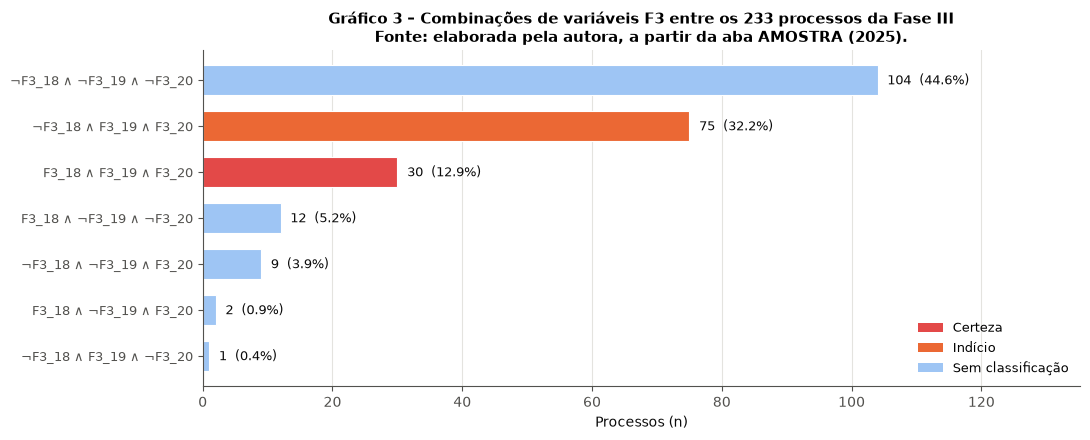

In [26]:
# ── Gráfico 3: combinações de variáveis F3 entre os 233 da Fase III ───────────
# Exibe apenas as combinações com n > 0, ordenadas por contagem.

tab6_plot = tab6[tab6['n'] > 0].sort_values('n', ascending=True)

cores_combo = {
    'Certeza'          : '#e34948',
    'Indício'          : '#eb6834',
    'Sem classificação': '#9ec5f4',
}

fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(tab6_plot))
barras = ax.barh(
    y,
    tab6_plot['n'],
    color=[cores_combo.get(c, GRADE) for c in tab6_plot['Classificação']],
    edgecolor='white', linewidth=0.8, height=0.65,
)
# Rótulos de valor
for barra, (_, row) in zip(barras, tab6_plot.iterrows()):
    ax.text(barra.get_width() + 1.5, barra.get_y() + barra.get_height() / 2,
            f'{int(row["n"])}  ({row["%"]:.1f}%)',
            va='center', ha='left', fontsize=9.5, color=TINTA)

ax.set_yticks(y)
ax.set_yticklabels(tab6_plot['Combinação'], fontsize=9)
ax.set_xlabel('Processos (n)')
ax.set_xlim(0, tab6_plot['n'].max() * 1.30)
ax.set_title(
    'Gráfico 3 – Combinações de variáveis F3 entre os 233 processos da Fase III\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold',
)
ax.grid(axis='y', visible=False)

# Legenda
handles = [mpatches.Patch(facecolor=c, label=r)
           for r, c in cores_combo.items()]
ax.legend(handles=handles, loc='lower right', fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

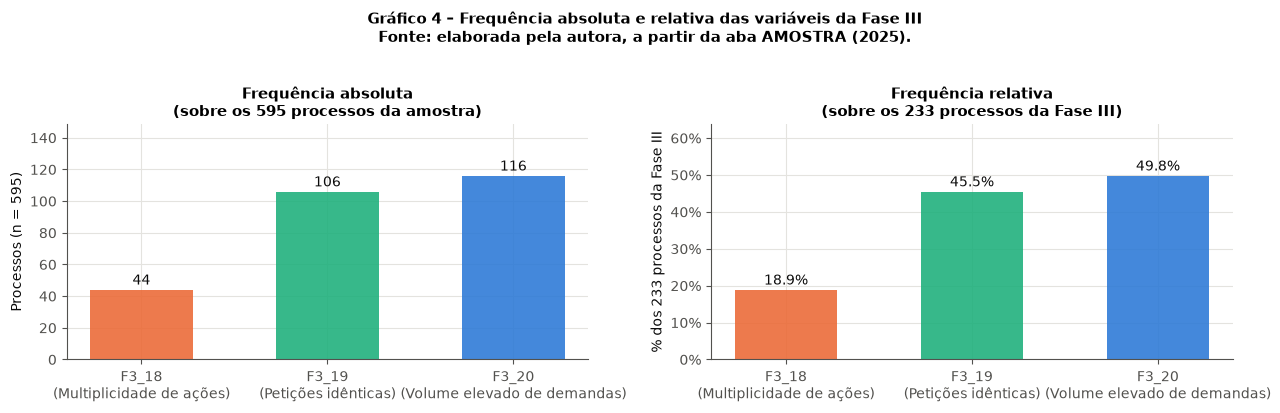

F3_18: 44 processos | F3_19: 106 | F3_20: 116


In [27]:
# ── Gráfico 4: frequência absoluta das variáveis F3 isoladas ──────────────────
# Exibe quantos processos (sobre os 595 totais) têm cada variável positivada.
# Evidencia o gap entre F3_20/F3_19 (~17-20%) e F3_18 (~7%).

f3_freq = pd.DataFrame({
    'Variável': ['F3_18\n(Multiplicidade de ações)', 'F3_19\n(Petições idênticas)',
                 'F3_20\n(Volume elevado de demandas)'],
    'n':        [int(dados['F3_18'].sum()), int(dados['F3_19'].sum()),
                 int(dados['F3_20'].sum())],
})
f3_freq['% (sobre 595)'] = f3_freq['n'] / N_AMST * 100
f3_freq['% (sobre 233)'] = f3_freq['n'] / N_FASE_III * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Painel esquerdo: frequência sobre os 595
cores_f3 = [CORES[1], CORES[2], CORES[0]]
barras_l = axes[0].bar(f3_freq['Variável'], f3_freq['n'],
                       color=cores_f3, alpha=0.88, width=0.55)
anotar_barras(axes[0], barras_l, formato='{:.0f}', fontsize=10)
axes[0].set_ylabel('Processos (n = 595)')
axes[0].set_title('Frequência absoluta\n(sobre os 595 processos da amostra)', fontsize=10.5)
axes[0].set_ylim(0, f3_freq['n'].max() * 1.28)

# Painel direito: frequência sobre os 233 da Fase III
barras_r = axes[1].bar(f3_freq['Variável'], f3_freq['% (sobre 233)'],
                       color=cores_f3, alpha=0.88, width=0.55)
anotar_barras(axes[1], barras_r,
              formato='{:.1f}%', fontsize=10)
axes[1].set_ylabel('% dos 233 processos da Fase III')
axes[1].set_title('Frequência relativa\n(sobre os 233 processos da Fase III)', fontsize=10.5)
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_ylim(0, f3_freq['% (sobre 233)'].max() * 1.28)

plt.suptitle(
    'Gráfico 4 – Frequência absoluta e relativa das variáveis da Fase III\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.show()
print(f'F3_18: {int(dados["F3_18"].sum())} processos | '
      f'F3_19: {int(dados["F3_19"].sum())} | '
      f'F3_20: {int(dados["F3_20"].sum())}')

### 5.4 Incidência por ano de distribuição (Tabela 7, Gráfico 5)

A análise temporal revela uma aparente flutuação da incidência entre os
três anos: **2022** apresenta 18,0% de indício; **2023**, 19,9% (pico);
e **2024**, 14,7%. Contudo, conforme demonstrado na seção de testes
inferenciais (seção 7.1), essa variação **não é estatisticamente significativa**
(χ² = 1,87; gl = 2; p = 0,393), sendo atribuível à variabilidade amostral.

A queda observada em 2024 deve ser interpretada com cautela metodológica:
as variáveis sistêmicas da Fase III (especialmente F3_19 e F3_20) dependem
da observação de padrões acumulados no sistema PJe. Para processos distribuídos
em 2024, esse padrão pode estar ainda em formação à data da coleta
(março de 2026), comprimindo artificialmente a estimativa de incidência
para essa coorte.

Ano,n,Indício (incl. cert.),% Indício,IC inf. Indício,IC sup. Indício,Certeza,% Certeza,IC inf. Certeza,IC sup. Certeza,Só Indício
2022,194,35,18.0%,13.3%,24.1%,5,2.6%,1.1%,5.9%,30
2023,211,42,19.9%,15.1%,25.8%,15,7.1%,4.4%,11.4%,27
2024,190,28,14.7%,10.4%,20.5%,10,5.3%,2.9%,9.4%,18


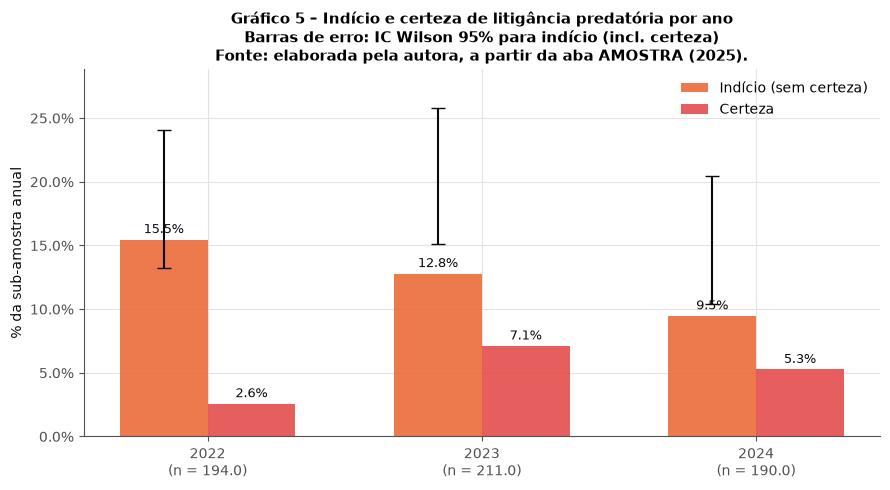

In [28]:
# ── Tabela 7: distribuição da classificação por ano ───────────────────────────

linhas_ano = []
for ano in [2022, 2023, 2024]:
    d  = dados[dados['ano'] == ano]
    n  = len(d)
    ni = int(d['Indicio'].sum())
    nc = int(d['Certeza'].sum())
    ns = ni - nc
    li_i, ls_i = proportion_confint(ni, n, alpha=ALPHA, method='wilson')
    li_c, ls_c = proportion_confint(nc, n, alpha=ALPHA, method='wilson')
    linhas_ano.append({
        'Ano'                  : ano,
        'n'                    : n,
        'Indício (incl. cert.)': ni,
        '% Indício'            : ni / n,
        'IC inf. Indício'      : li_i,
        'IC sup. Indício'      : ls_i,
        'Certeza'              : nc,
        '% Certeza'            : nc / n,
        'IC inf. Certeza'      : li_c,
        'IC sup. Certeza'      : ls_c,
        'Só Indício'           : ns,
    })

tab7 = pd.DataFrame(linhas_ano)

display(
    tab7.style
    .set_caption(
        'Tabela 7 – Distribuição da classificação por ano | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'Nota: percentuais calculados sobre o total anual. '
        'IC Wilson 95%. Indício inclui certeza.'
    )
    .format({
        'n'                    : '{:,.0f}',
        'Indício (incl. cert.)': '{:,.0f}',
        '% Indício'            : '{:.1%}',
        'IC inf. Indício'      : '{:.1%}',
        'IC sup. Indício'      : '{:.1%}',
        'Certeza'              : '{:,.0f}',
        '% Certeza'            : '{:.1%}',
        'IC inf. Certeza'      : '{:.1%}',
        'IC sup. Certeza'      : '{:.1%}',
        'Só Indício'           : '{:,.0f}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center'), ('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'background-color: #eef3fc' if r % 2 == 0 else ''
        for r in range(len(col))
    ])
    .hide(axis='index')
)

# ── Gráfico 5: Indício e certeza por ano ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

anos_lab = ['2022', '2023', '2024']
x        = np.arange(3)
larg     = 0.32

# Barras: Só Indício (empilhado abaixo da Certeza)
bars_si = ax.bar(x - larg/2, tab7['Só Indício'] / tab7['n'] * 100,
                 larg, label='Indício (sem certeza)',
                 color=CORES[1], alpha=0.88)
bars_ce = ax.bar(x + larg/2, tab7['% Certeza'] * 100,
                 larg, label='Certeza',
                 color=CORES[7], alpha=0.88)

# Barras de erro (IC Wilson) para Indício total
for i, row in tab7.iterrows():
    pct_i  = row['% Indício'] * 100
    err_lo = pct_i - row['IC inf. Indício'] * 100
    err_hi = row['IC sup. Indício'] * 100 - pct_i
    ax.errorbar(i - larg/2, pct_i,
                yerr=[[err_lo], [err_hi]],
                fmt='none', color=TINTA, capsize=5, linewidth=1.5, zorder=5)

anotar_barras(ax, bars_si, formato='{:.1f}%', fontsize=9)
anotar_barras(ax, bars_ce, formato='{:.1f}%', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([f'{a}\n(n = {tab7.iloc[i]["n"]})' for i, a in enumerate(anos_lab)])
ax.set_ylabel('% da sub-amostra anual')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, max(tab7['% Indício'].max() * 100, tab7['% Certeza'].max() * 100) * 1.45)
ax.legend(fontsize=10, loc='upper right')
ax.set_title(
    'Gráfico 5 – Indício e certeza de litigância predatória por ano\n'
    'Barras de erro: IC Wilson 95% para indício (incl. certeza)\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
plt.show()

### 5.5 Incidência por unidade judiciária (Tabela 8, Gráfico 6)

A análise por unidade revela **variabilidade relevante** entre os 14 Juizados.
A média geral é de **17,6%** (indício + certeza), mas a faixa de variação
é ampla: de **5,6%** no 13º JEC a **35,9%** no 7º JEC.

O **7º JEC** apresenta a maior incidência observada (35,9%), com destaque
para a proporção de certeza (12,8% — mais que o dobro da média geral de 5,0%).
As comparações pareadas (seção 7.2) confirmam que essa diferença é
**estatisticamente significativa** (p < 0,001 vs. os demais JECs agrupados).

Sete unidades apresentam percentuais acima da média geral: 1º, 2º, 4º,
5º, 7º, 8º e 14º JEC, sugerindo distribuição heterogênea do fenômeno.
Como a distribuição processual é aleatorizada pelo sistema PJe, não é
possível atribuir esse padrão a direcionamento intencional das demandas,
demandando investigação adicional com dados complementares.

Asserts Tabela 8: OK
Média geral % Indício: 17.63%


JEC,n,Indício (sem cert.),Certeza,Total c/ indício,% Indício,% Certeza
1º JEC,43,8,3,11,25.6%,7.0%
2º JEC,55,11,1,12,21.8%,1.8%
3º JEC,43,5,2,7,16.3%,4.7%
4º JEC,39,5,2,7,17.9%,5.1%
5º JEC,33,4,2,6,18.2%,6.1%
6º JEC,48,4,4,8,16.7%,8.3%
7º JEC,39,9,5,14,35.9%,12.8%
8º JEC,42,9,1,10,23.8%,2.4%
9º JEC,44,3,2,5,11.4%,4.5%
10º JEC,45,3,1,4,8.9%,2.2%


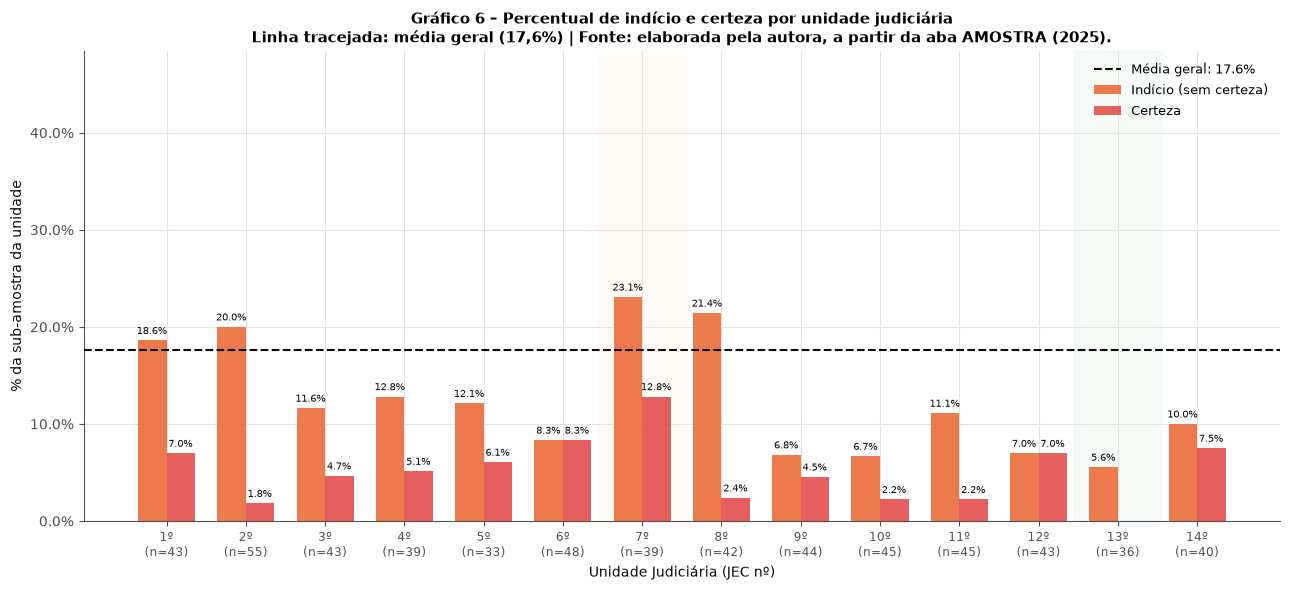

In [29]:
# ── Tabela 8: indício e certeza por unidade judiciária ────────────────────────

linhas_jec = []
for j in range(1, 15):
    d  = dados[dados['JEC_numero'] == j]
    n  = len(d)
    ni = int(d['Indicio'].sum())
    nc = int(d['Certeza'].sum())
    ns = ni - nc
    linhas_jec.append({
        'JEC'                  : f'{j}º JEC',
        'n'                    : n,
        'Indício (sem cert.)'  : ns,
        'Certeza'              : nc,
        'Total c/ indício'     : ni,
        '% Indício'            : ni / n,
        '% Certeza'            : nc / n,
    })

tab8 = pd.DataFrame(linhas_jec)

# Verificação dos valores-âncora da monografia
assert tab8.loc[tab8['JEC'] == '7º JEC', '% Indício'].values[0] > 0.35, \
    '7º JEC deveria ter >35% de indício'
assert tab8.loc[tab8['JEC'] == '13º JEC', 'Certeza'].values[0] == 0, \
    '13º JEC deveria ter Certeza = 0'
print('Asserts Tabela 8: OK')
print(f'Média geral % Indício: {tab8["% Indício"].mean()*100:.2f}%')

display(
    tab8.style
    .set_caption(
        'Tabela 8 – Indício e certeza de litigância predatória por unidade '
        'judiciária (n = 595) | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'Nota: a coluna "Indício (sem cert.)" exclui os processos de certeza '
        'para evitar dupla contagem.'
    )
    .format({
        'n'                  : '{:,.0f}',
        'Indício (sem cert.)': '{:,.0f}',
        'Certeza'            : '{:,.0f}',
        'Total c/ indício'   : '{:,.0f}',
        '% Indício'          : '{:.1%}',
        '% Certeza'          : '{:.1%}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center'), ('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'background-color: #eef3fc' if r % 2 == 0 else ''
        for r in range(len(col))
    ])
    .bar(subset=['% Indício', '% Certeza'],
         color=[COR_PRINCIPAL, COR_DESTAQUE], vmin=0, vmax=0.40)
    .hide(axis='index')
)

# ── Gráfico 6: Percentual de indício e certeza por JEC ────────────────────────
MEDIA_IND = tab8['% Indício'].mean()

fig, ax = plt.subplots(figsize=(13, 6))
x    = np.arange(1, 15)
larg = 0.36

# Barras: Só Indício (base) e Certeza (acima)
pct_si = (tab8['Indício (sem cert.)'] / tab8['n']).values * 100
pct_ce = tab8['% Certeza'].values * 100

bars_si = ax.bar(x - larg/2, pct_si, larg,
                 label='Indício (sem certeza)', color=CORES[1], alpha=0.88)
bars_ce = ax.bar(x + larg/2, pct_ce, larg,
                 label='Certeza', color=CORES[7], alpha=0.88)

# Linha de média geral
ax.axhline(MEDIA_IND * 100, color=TINTA, linewidth=1.5,
           linestyle='--', label=f'Média geral: {MEDIA_IND*100:.1f}%', zorder=5)

# Rótulos nas barras
for barra in list(bars_si) + list(bars_ce):
    h = barra.get_height()
    if h >= 1.5:
        ax.text(barra.get_x() + barra.get_width() / 2, h + 0.4,
                f'{h:.1f}%', ha='center', va='bottom',
                fontsize=7.5, color=TINTA)

# Destacar 7º e 13º JEC com fundo
for j_dest, cor_dest in [(7, '#fff3cd'), (13, '#d4edda')]:
    ax.axvspan(j_dest - 0.55, j_dest + 0.55, alpha=0.18,
               color=cor_dest, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels(
    [f'{j}º\n(n={tab8.iloc[j-1]["n"]})' for j in range(1, 15)],
    fontsize=8.5,
)
ax.set_xlabel('Unidade Judiciária (JEC nº)')
ax.set_ylabel('% da sub-amostra da unidade')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, max(pct_si + pct_ce) * 1.35)
ax.legend(fontsize=9.5, loc='upper right')
ax.set_title(
    'Gráfico 6 – Percentual de indício e certeza por unidade judiciária\n'
    'Linha tracejada: média geral (17,6%) | '
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
plt.show()

### 5.6 Síntese dos achados descritivos

A análise descritiva revela um fenômeno de **relevo sistêmico**: mesmo na
hipótese mais conservadora (certeza, com três variáveis F3 positivadas
simultaneamente), estima-se que **mais de 2.500 processos** no triênio
2022–2024 nos 14 JECs de Natal possam ser classificados como litigância
predatória. Na hipótese de indício em sentido amplo, esse número pode superar
**8.800 processos**.

Do ponto de vista temporal, a incidência mostrou-se **estável** ao longo
do triênio — a variação entre os anos não atingiu significância estatística
—, afastando a hipótese de que o fenômeno seja transitório ou esteja em
declínio espontâneo no período.

Do ponto de vista espacial, a **heterogeneidade entre os JECs** é digna de
atenção: o 7º JEC concentra incidência quase o dobro da média geral, enquanto
o 13º JEC apresenta a menor incidência observada. Investigar as causas dessa
assimetria — composição da carteira, padrões de distribuição, concentração
de advogados específicos — é passo metodológico relevante para pesquisas futuras.

**Limitações:** as estimativas populacionais pressupõem que a amostra é
representativa da população depurada (50.320 processos). Eventuais vieses
de seleção não detectados — como a eventual concentração dos advogados
predatórios em períodos ou unidades específicos — poderiam afetar a
generalização dos resultados. Adicionalmente, a coorte de 2024 pode estar
subestimada em função da imaturidade dos padrões sistêmicos no PJe à época
da coleta.

---

## 6. Frequência das Variáveis Observacionais

### 6.1 Panorama das variáveis de exclusão — Fase I (Tabela 9)

As seis variáveis da Fase I são critérios de **exclusão**: processos que
apresentam qualquer uma delas não reúnem as condições mínimas para serem
analisados como casos de potencial litigância predatória pelo polo ativo.
De 595 processos avaliados, **151 (25,4%)** foram excluídos — em 150 casos
por um único critério e em 1 caso por dois critérios simultâneos.

O critério mais acionado foi **F1_A** — ações com pessoa física no polo
passivo (79 processos; 13,3%) —, o que é consistente com o perfil esperado
do fenômeno: litigância predatória pressupõe a presença de pessoa jurídica
no polo passivo (ex.: operadoras de planos de saúde, instituições financeiras,
empresas de telecomunicações), não o reverso.

**F1_D** (processos suspensos) não apresentou nenhuma ocorrência (0,0%).
Esse resultado decorre de decisão metodológica adotada no curso da pesquisa:
os processos suspensos foram depurados diretamente na planilha-base do TJRN,
tornando a variável tecnicamente não observável nesta amostra. Por essa razão,
F1_D não integra o Quadro 3 da monografia (25 variáveis) e é mantida aqui
apenas para documentação da completude do instrumento de coleta.

In [30]:
# ── Configuração dos rótulos e descrições das variáveis F1 ───────────────────
NOMES_F1 = {
    'F1_A': 'Ações com pessoa física no polo passivo',
    'F1_B': 'Ausência de grande litigante no polo passivo',
    'F1_C': 'Causas ajuizadas sem advogado (atermação)',
    'F1_D': 'Processos suspensos (*)  — variável retirada',
    'F1_E': 'Distribuição incorreta',
    'F1_F': 'Parte jurídica no polo ativo',
}

DESC_F1 = {
    'F1_A': 'Excluir quando o polo passivo é formado por pessoa física',
    'F1_B': 'Excluir quando não há grande litigante no polo passivo',
    'F1_C': 'Excluir processos ajuizados sem representação por advogado',
    'F1_D': 'Excluir processos suspensos por determinação judicial',
    'F1_E': 'Processos erroneamente distribuídos aos Juizados Especiais',
    'F1_F': 'Excluir quando o polo ativo é pessoa jurídica',
}

CRITERIO_F1 = {c: 'Consulta às partes e movimentações do PJe' for c in COLS_F1}

# ── Calcular frequências ──────────────────────────────────────────────────────
linhas_f1 = []
for col in COLS_F1:
    n_sim = int(dados[col].sum())
    n_nao = int((~dados[col]).sum())
    # IC Wilson sobre os 595 (mesmo para variáveis de exclusão)
    if n_sim > 0:
        li, ls = proportion_confint(n_sim, N_AMST, alpha=ALPHA, method='wilson')
    else:
        li, ls = 0.0, 0.0
    linhas_f1.append({
        'Código'         : col,
        'Nome da Variável': NOMES_F1[col],
        'Critério'       : 'Exclusão (se Sim → excluído da análise)',
        'Sim'            : n_sim,
        '% Sim'          : n_sim / N_AMST,
        'IC 2,5%'        : li,
        'IC 97,5%'       : ls,
        'Não'            : n_nao,
        '% Não'          : n_nao / N_AMST,
    })

tab9 = pd.DataFrame(linhas_f1)

# Validar valores da monografia
assert tab9.loc[tab9['Código'] == 'F1_A', 'Sim'].values[0] == 79, \
    'F1_A: esperado 79'
assert tab9.loc[tab9['Código'] == 'F1_D', 'Sim'].values[0] == 0, \
    'F1_D: esperado 0 (retirada da pesquisa)'
assert tab9.loc[tab9['Código'] == 'F1_B', 'Sim'].values[0] == 28, \
    'F1_B: esperado 28'
assert tab9['Sim'].sum() == 152, \
    f'Soma de Sim na F1: esperado 152 (151 excluídos + 1 processo c/ F1_A+F1_B); obtido {tab9["Sim"].sum()}'
print('Asserts Tabela 9: OK')
print()

# Exibição estilizada
display(
    tab9[['Código', 'Nome da Variável', 'Sim', '% Sim', 'IC 2,5%', 'IC 97,5%', 'Não', '% Não']].style
    .set_caption(
        'Tabela 9 – Frequência das variáveis da Fase I — exclusão (n = 595) | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        '(*) F1_D: variável retirada no curso da pesquisa; processos suspensos '
        'foram depurados diretamente na planilha-base.'
    )
    .format({
        'Sim'    : '{:,.0f}',
        '% Sim'  : '{:.1%}',
        'IC 2,5%': '{:.1%}',
        'IC 97,5%':'{:.1%}',
        'Não'    : '{:,.0f}',
        '% Não'  : '{:.1%}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        # Destacar F1_D (retirada) em cinza
        'background-color: #f0f0f0; color: #999999'
        if tab9.iloc[r]['Código'] == 'F1_D'
        else 'background-color: #eef3fc' if r % 2 == 0
        else ''
        for r in range(len(col))
    ])
    .bar(subset=['% Sim'], color='#eb6834', vmin=0, vmax=0.16)
    .hide(axis='index')
)

Asserts Tabela 9: OK



Código,Nome da Variável,Sim,% Sim,"IC 2,5%","IC 97,5%",Não,% Não
F1_A,Ações com pessoa física no polo passivo,79,13.3%,10.8%,16.2%,516,86.7%
F1_B,Ausência de grande litigante no polo passivo,28,4.7%,3.3%,6.7%,567,95.3%
F1_C,Causas ajuizadas sem advogado (atermação),16,2.7%,1.7%,4.3%,579,97.3%
F1_D,Processos suspensos (*) — variável retirada,0,0.0%,0.0%,0.0%,595,100.0%
F1_E,Distribuição incorreta,12,2.0%,1.2%,3.5%,583,98.0%
F1_F,Parte jurídica no polo ativo,17,2.9%,1.8%,4.5%,578,97.1%


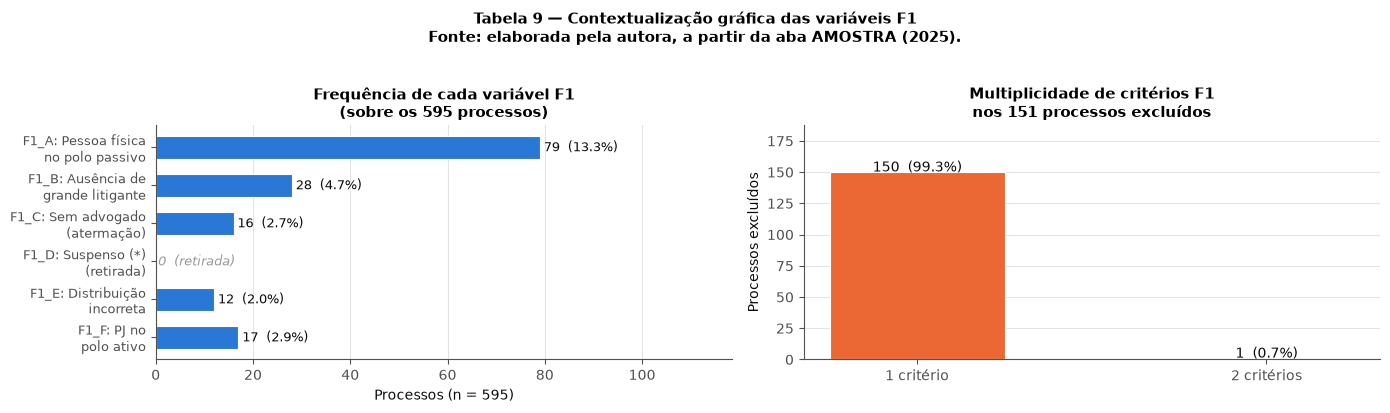

In [31]:
# ── Gráfico complementar: distribuição dos exclusores F1 ──────────────────────
# Barras horizontais com dois grupos: frequência de cada variável sobre os 595
# e, separadamente, a sobreposição (processos com múltiplos critérios).

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Painel esquerdo: frequência de cada variável F1 sobre os 595
cols_f1_plot = COLS_F1  # inclui F1_D para mostrar que é zero
nomes_curtos = {
    'F1_A': 'F1_A: Pessoa física\nno polo passivo',
    'F1_B': 'F1_B: Ausência de\ngrande litigante',
    'F1_C': 'F1_C: Sem advogado\n(atermação)',
    'F1_D': 'F1_D: Suspenso (*)\n(retirada)',
    'F1_E': 'F1_E: Distribuição\nincorreta',
    'F1_F': 'F1_F: PJ no\npolo ativo',
}
vals_f1 = [int(dados[c].sum()) for c in cols_f1_plot]
cores_f1 = [
    COR_PRINCIPAL if v > 0 else GRADE
    for v in vals_f1
]
y = np.arange(len(cols_f1_plot))
barras_f1 = axes[0].barh(
    y, vals_f1,
    color=cores_f1, edgecolor='white',
    linewidth=0.8, height=0.60,
)
for barra, v in zip(barras_f1, vals_f1):
    if v > 0:
        axes[0].text(
            barra.get_width() + 0.8,
            barra.get_y() + barra.get_height() / 2,
            f'{v}  ({v/N_AMST*100:.1f}%)',
            va='center', ha='left', fontsize=9.5, color=TINTA,
        )
    else:
        axes[0].text(
            0.5, barra.get_y() + barra.get_height() / 2,
            '0  (retirada)',
            va='center', ha='left', fontsize=9, color='#999999', style='italic',
        )

axes[0].set_yticks(y)
axes[0].set_yticklabels([nomes_curtos[c] for c in cols_f1_plot], fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel('Processos (n = 595)')
axes[0].set_xlim(0, max(vals_f1) * 1.50)
axes[0].set_title('Frequência de cada variável F1\n(sobre os 595 processos)', fontsize=10.5)
axes[0].grid(axis='y', visible=False)

# Painel direito: composição dos 151 excluídos
dados_excl = dados[dados['Excluido_F1']].copy()
n_excl_total = len(dados_excl)
n_f1_por_proc = dados_excl[COLS_F1].sum(axis=1)
dist_mult = n_f1_por_proc.value_counts().sort_index()

axes[1].bar(
    [f'{int(k)} critério{"s" if k > 1 else ""}' for k in dist_mult.index],
    dist_mult.values,
    color=[CORES[1], CORES[7]][:len(dist_mult)],
    edgecolor='white', linewidth=0.8, width=0.5,
)
for i, v in enumerate(dist_mult.values):
    axes[1].text(
        i, v + 0.5,
        f'{v}  ({v/n_excl_total*100:.1f}%)',
        ha='center', fontsize=10, color=TINTA,
    )
axes[1].set_ylabel('Processos excluídos')
axes[1].set_ylim(0, dist_mult.max() * 1.25)
axes[1].set_title(
    f'Multiplicidade de critérios F1\nnos {n_excl_total} processos excluídos',
    fontsize=10.5,
)
axes[1].grid(axis='x', visible=False)

plt.suptitle(
    'Tabela 9 — Contextualização gráfica das variáveis F1\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.show()

### 6.2 Frequência das variáveis de indício — Fase II (Gráfico 7)

Das 17 variáveis de indício observadas na Fase II, quatro apresentaram
**zero ocorrências** em toda a amostra de 595 processos:

- **F2_07** (Pedidos vagos/hipotéticos)
- **F2_12** (Valor da causa inadequado)
- **F2_15** (Desistência após notificação)
- **F2_16** (Desistência após contestação)

As quatro variáveis com zero ocorrências serão **excluídas das análises
bivariada e multivariada** (Seções 7 e 8), pois são constantes e,
portanto, não discriminantes para modelos preditivos.

As demais 13 variáveis apresentam frequências muito concentradas:
as **quatro variáveis mais comuns** — F2_06, F2_11, F2_01 e F2_02 —
representam, em conjunto, **quase 80%** de todas as positivações da Fase II.
Isso revela um padrão altamente estruturado de irregularidades:
documentação deficiente, advogado fora da comarca e petição padronizada
são os marcadores mais associados ao fenômeno no universo dos JECs de Natal.

> **Base de cálculo:** as frequências da Tabela abaixo e do Gráfico 7
> são apresentadas em duas escalas — sobre os **595 processos totais**
> e sobre os **444 que avançaram à Fase II** —, pois a interpretação
> substantiva depende do denominador adotado. Para os 151 excluídos na
> Fase I, as variáveis F2 foram computadas como `False` (não aplicáveis).

In [32]:
# ── Rótulos detalhados das variáveis F2 ──────────────────────────────────────
NOMES_F2 = {
    'F2_01': 'F2_01 — Petição vaga/genérica',
    'F2_02': 'F2_02 — Ausência de documentos essenciais',
    'F2_03': 'F2_03 — Documentos sem relação com a causa',
    'F2_04': 'F2_04 — Pedido de dispensa de audiência',
    'F2_05': 'F2_05 — Foro inadequado',
    'F2_06': 'F2_06 — Documentos incompletos/ilegíveis',
    'F2_07': 'F2_07 — Pedidos vagos/hipotéticos (*)',
    'F2_08': 'F2_08 — Demanda idêntica não declarada',
    'F2_09': 'F2_09 — Procuração incompleta',
    'F2_10': 'F2_10 — Procuração irregular (assin. digital)',
    'F2_11': 'F2_11 — Advogado fora da comarca',
    'F2_12': 'F2_12 — Valor da causa inadequado (*)',
    'F2_13': 'F2_13 — Classe ou assunto incorreto',
    'F2_14': 'F2_14 — Desistência após indeferi. de liminar',
    'F2_15': 'F2_15 — Desistência após notificação (*)',
    'F2_16': 'F2_16 — Desistência após contestação (*)',
    'F2_17': 'F2_17 — Contrato de honorários abusivo',
}

# ── Subconjunto Fase II ───────────────────────────────────────────────────────
dados_f2_base = dados[~dados['Excluido_F1']].copy()   # 444 processos
N_F2 = len(dados_f2_base)   # 444

# ── Calcular frequências nas duas bases ──────────────────────────────────────
linhas_freq_f2 = []
for col in COLS_F2:
    n_595 = int(dados[col].sum())
    n_444 = int(dados_f2_base[col].sum())
    linhas_freq_f2.append({
        'Código'             : col,
        'Nome'               : NOMES_F2[col],
        'n (sobre 595)'      : n_595,
        '% (sobre 595)'      : n_595 / N_AMST,
        'n (sobre 444)'      : n_444,
        '% (sobre 444)'      : n_444 / N_F2,
        'Zero ocorrências'   : n_595 == 0,
    })

freq_f2 = (pd.DataFrame(linhas_freq_f2)
           .sort_values('n (sobre 595)', ascending=False)
           .reset_index(drop=True))

# Validar top-4
top4 = freq_f2.head(4)['Código'].tolist()
assert set(top4) == {'F2_06', 'F2_11', 'F2_01', 'F2_02'}, \
    f'Top-4 F2 inesperado: {top4}'

# Validar zeros
zeros_f2 = freq_f2.loc[freq_f2['Zero ocorrências'], 'Código'].tolist()
assert set(zeros_f2) == {'F2_07', 'F2_12', 'F2_15', 'F2_16'}, \
    f'Variáveis com zero inesperadas: {zeros_f2}'

print('Asserts frequencias F2: OK')
print(f'  Top-4: {top4}')
print(f'  Zeros: {sorted(zeros_f2)}')
print()

# Variáveis com ocorrências (para modelos preditivos)
COLS_F2_ATIVOS = freq_f2.loc[~freq_f2['Zero ocorrências'], 'Código'].tolist()
print(f'  F2 com ocorrencias (n = {len(COLS_F2_ATIVOS)}): {COLS_F2_ATIVOS}')

Asserts frequencias F2: OK
  Top-4: ['F2_06', 'F2_11', 'F2_01', 'F2_02']
  Zeros: ['F2_07', 'F2_12', 'F2_15', 'F2_16']

  F2 com ocorrencias (n = 13): ['F2_06', 'F2_11', 'F2_01', 'F2_02', 'F2_10', 'F2_04', 'F2_14', 'F2_09', 'F2_13', 'F2_17', 'F2_05', 'F2_08', 'F2_03']


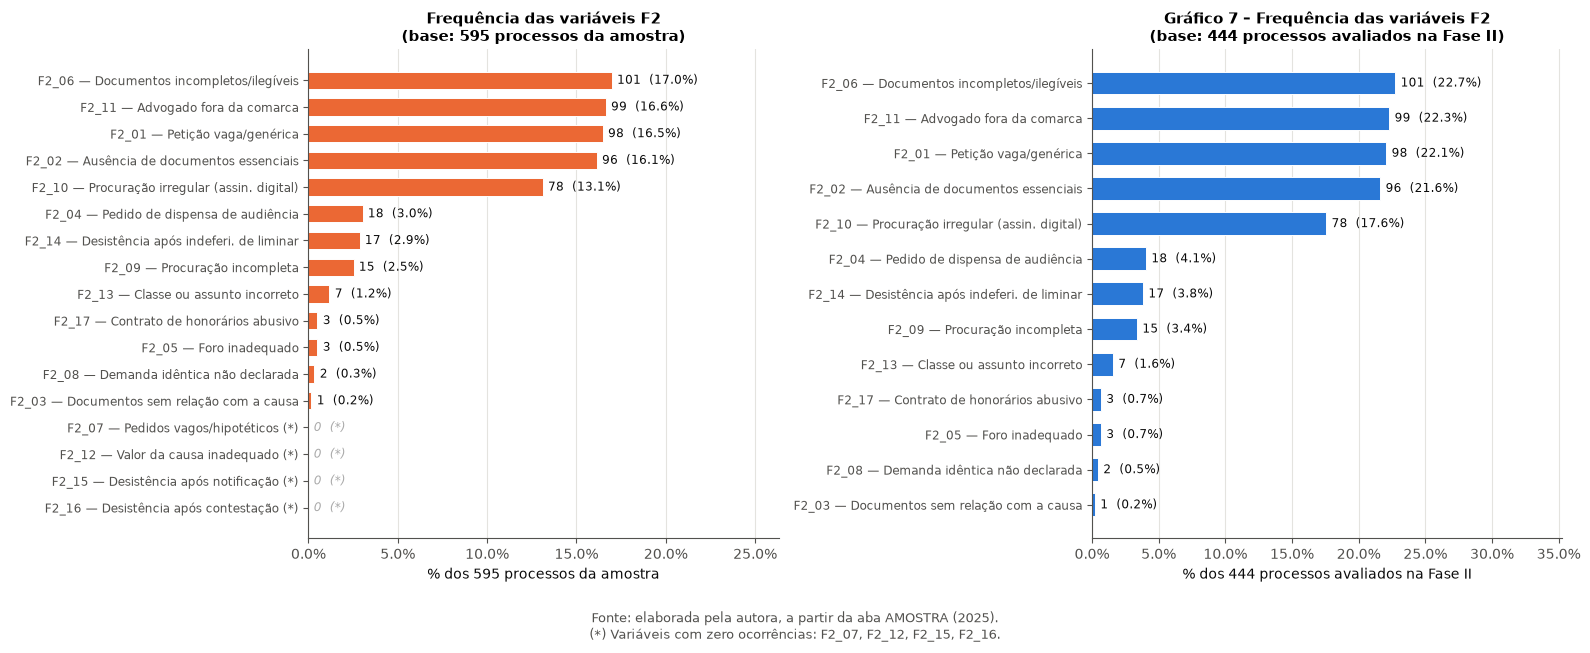

In [33]:
# ── Gráfico 7: frequência das variáveis F2 (barras horizontais duplas) ─────────
# Duas sub-figuras lado a lado:
#   Esquerdo: todas as 17 variáveis (% sobre 595)
#   Direito : variáveis com ao menos 1 ocorrência (% sobre 444 da Fase II)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# ── Painel esquerdo: % sobre 595 ─────────────────────────────────────────────
freq_plot = freq_f2.copy()  # já ordenado por n decrescente
y = np.arange(len(freq_plot))

# Cores: laranja para não-nulas, cinza para zero-ocorrências
cores_graf7 = [
    COR_DESTAQUE if not row['Zero ocorrências'] else GRADE
    for _, row in freq_plot.iterrows()
]

barras_esq = axes[0].barh(
    y, freq_plot['% (sobre 595)'] * 100,
    color=cores_graf7, edgecolor='white',
    linewidth=0.7, height=0.65,
)
for barra, (_, row) in zip(barras_esq, freq_plot.iterrows()):
    v = row['% (sobre 595)'] * 100
    n = int(row['n (sobre 595)'])
    if n > 0:
        axes[0].text(
            v + 0.3, barra.get_y() + barra.get_height() / 2,
            f'{n}  ({v:.1f}%)',
            va='center', ha='left', fontsize=8.5, color=TINTA,
        )
    else:
        axes[0].text(
            0.3, barra.get_y() + barra.get_height() / 2,
            '0  (*)',
            va='center', ha='left', fontsize=8.5, color='#aaaaaa', style='italic',
        )

axes[0].set_yticks(y)
axes[0].set_yticklabels(freq_plot['Nome'], fontsize=8.5)
axes[0].invert_yaxis()
axes[0].set_xlabel('% dos 595 processos da amostra')
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[0].set_xlim(0, freq_plot['% (sobre 595)'].max() * 100 * 1.55)
axes[0].set_title('Frequência das variáveis F2\n(base: 595 processos da amostra)',
                  fontsize=10.5, fontweight='bold')
axes[0].grid(axis='y', visible=False)

# ── Painel direito: só variáveis ativas (% sobre 444 da Fase II) ───────────────
freq_ativas = freq_plot[~freq_plot['Zero ocorrências']].copy()
y2 = np.arange(len(freq_ativas))

barras_dir = axes[1].barh(
    y2, freq_ativas['% (sobre 444)'] * 100,
    color=COR_PRINCIPAL, edgecolor='white',
    linewidth=0.7, height=0.65,
)
for barra, (_, row) in zip(barras_dir, freq_ativas.iterrows()):
    v = row['% (sobre 444)'] * 100
    n = int(row['n (sobre 444)'])
    axes[1].text(
        v + 0.4, barra.get_y() + barra.get_height() / 2,
        f'{n}  ({v:.1f}%)',
        va='center', ha='left', fontsize=8.5, color=TINTA,
    )

axes[1].set_yticks(y2)
axes[1].set_yticklabels(freq_ativas['Nome'], fontsize=8.5)
axes[1].invert_yaxis()
axes[1].set_xlabel('% dos 444 processos avaliados na Fase II')
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_xlim(0, freq_ativas['% (sobre 444)'].max() * 100 * 1.55)
axes[1].set_title(
    'Gráfico 7 – Frequência das variáveis F2\n'
    '(base: 444 processos avaliados na Fase II)',
    fontsize=10.5, fontweight='bold',
)
axes[1].grid(axis='y', visible=False)

plt.suptitle(
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
    '(*) Variáveis com zero ocorrências: F2_07, F2_12, F2_15, F2_16.',
    fontsize=9, y=-0.02, color=TINTA_2,
)
plt.tight_layout()
plt.show()

### 6.3 Interpretação das frequências da Fase II

O Gráfico 7 evidencia uma estrutura bimodal nas frequências das variáveis F2:
há um **bloco superior de quatro variáveis de alta frequência** (F2_06,
F2_11, F2_01 e F2_02 — todas com 16% a 17% dos 595 processos) e um **grupo
inferior de longa cauda**, com frequências entre 0,2% e 3%.

Essa concentração tem implicações metodológicas e substantivas relevantes:

**Do ponto de vista substantivo**, as quatro variáveis de alta frequência
revelam o perfil característico da litigância predatória nos JECs de Natal:

- **F2_06** (Documentos incompletos/ilegíveis — 101 processos): padrão
  característico de produção em escala, em que a personalização dos anexos
  é dispensada em favor de documentos genéricos ou copiados de outros processos.
- **F2_11** (Advogado fora da comarca — 99 processos): advogados com sede
  em outra localidade que ajuízam demandas em série nos JECs de Natal,
  muitas vezes sem conhecimento do contexto local da relação jurídica.
- **F2_01** (Petição vaga/genérica — 98 processos): narrativa padronizada
  sem fatos específicos, traço clássico da industrialização da litigância.
- **F2_02** (Ausência de documentos essenciais — 96 processos): a ausência de
  documentos que comprovem minimamente a relação jurídica alegada é consistente
  com a estratégia de "tentativa de sorte", na qual a ausência de defesa ou a
  homologação automática de acordos são o verdadeiro objetivo.

**Do ponto de vista metodológico**, a alta correlação esperada entre F2_01,
F2_02, F2_06 e F2_11 — confirmada na análise da matriz phi (Seção 9) — impõe
cautela na regressão logística: a inclusão simultânea de variáveis altamente
colineares pode inflar os erros padrão dos coeficientes e dificultar a
interpretação dos odds ratios individuais.

### 6.4 Incidência por classe processual (Tabela 10)

A análise por classe processual é feita sobre os **595 processos**,
cruzando a classificação final (sem indício / indício sem certeza / certeza)
com a classe registrada no PJe. Como esperado, dada a composição da amostra
(**88,7% de "Procedimento do Juizado Especial Cível"**), a concentração dos
casos de indício e certeza está nessa classe.

A ocorrência de **2 processos com certeza e 4 com indício** entre os 67
processos de outras classes (majoritariamente Cumprimento de Sentença —
n = 58) sinaliza que o fenômeno não é absolutamente restrito ao procedimento
típico dos JECs, embora com frequência substancialmente menor: 6/67 = **9,0%**
nas outras classes vs. 99/528 = **18,8%** no procedimento típico.

In [34]:
# ── Tabela 10: incidência por classe processual ────────────────────────────────

# Classificação em três grupos para esta tabela
dados['classif3'] = pd.Categorical(
    np.where(dados['Certeza'], 'Certeza',
    np.where(dados['Indicio'], 'Indício (sem certeza)',
             'Sem indício')),
    categories=['Sem indício', 'Indício (sem certeza)', 'Certeza'],
    ordered=True,
)

# Classe resumida: procedimento típico vs. demais
CLASSE_PRINC = 'PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL'
dados['classe_tab10'] = dados['classe'].where(
    dados['classe'] == CLASSE_PRINC,
    other='Outras classes',
)

# Crosstab: classe × classificação
tab10_raw = pd.crosstab(
    dados['classe_tab10'],
    dados['classif3'],
    margins=True,
    margins_name='Total',
)
# Reordenar: classe principal primeiro
tab10_raw = tab10_raw.reindex([CLASSE_PRINC, 'Outras classes', 'Total'])

# Adicionar % por linha
for col in ['Sem indício', 'Indício (sem certeza)', 'Certeza']:
    tab10_raw[f'% {col}'] = (tab10_raw[col] / tab10_raw['Total'] * 100).round(1)

# % total com indício (qualquer)
tab10_raw['% c/ Indício'] = (
    (tab10_raw['Indício (sem certeza)'] + tab10_raw['Certeza'])
    / tab10_raw['Total'] * 100
).round(1)

# Validar valores da monografia
assert tab10_raw.loc[CLASSE_PRINC, 'Certeza'] == 28, \
    f'Certeza em Proc. JEC: esperado 28; obtido {tab10_raw.loc[CLASSE_PRINC, "Certeza"]}'
assert tab10_raw.loc['Outras classes', 'Certeza'] == 2, \
    f'Certeza nas outras classes: esperado 2'
assert tab10_raw.loc['Total', 'Total'] == 595, \
    'Total geral deve ser 595'
print('Asserts Tabela 10: OK')

display(
    tab10_raw[['Sem indício', 'Indício (sem certeza)', 'Certeza',
               'Total', '% Sem indício', '% Indício (sem certeza)',
               '% Certeza', '% c/ Indício']].style
    .set_caption(
        'Tabela 10 – Incidência de litigância predatória por classe '
        'processual (n = 595) | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'Nota: "Outras classes" inclui Cumprimento de Sentença (n=58), '
        'Procedimento Comum Cível (n=4) e demais classes residuais (n=5).'
    )
    .format({
        'Sem indício'            : '{:,.0f}',
        'Indício (sem certeza)'  : '{:,.0f}',
        'Certeza'                : '{:,.0f}',
        'Total'                  : '{:,.0f}',
        '% Sem indício'          : '{:.1f}%',
        '% Indício (sem certeza)': '{:.1f}%',
        '% Certeza'              : '{:.1f}%',
        '% c/ Indício'           : '{:.1f}%',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center'), ('font-size', '11px')]},
    ])
    .apply(lambda col: [
        'font-weight: bold; background-color: #d0e3f7'
        if idx == 'Total' else
        'background-color: #eef3fc' if i % 2 == 0 else ''
        for i, idx in enumerate(tab10_raw.index)
    ])
    .bar(subset=['% c/ Indício'], color=COR_DESTAQUE, vmin=0, vmax=25)
)

Asserts Tabela 10: OK


classif3,Sem indício,Indício (sem certeza),Certeza,Total,% Sem indício,% Indício (sem certeza),% Certeza,% c/ Indício
classe_tab10,,,,,,,,
PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL,429,71,28,528,81.2%,13.4%,5.3%,18.8%
Outras classes,61,4,2,67,91.0%,6.0%,3.0%,9.0%
Total,490,75,30,595,82.4%,12.6%,5.0%,17.6%


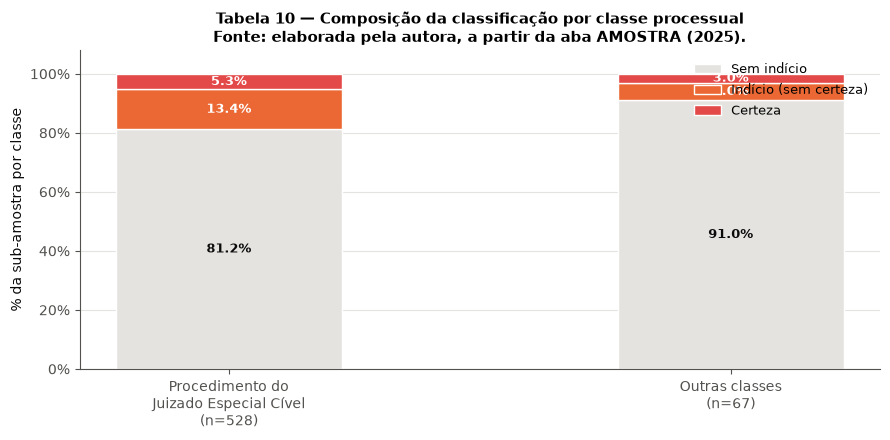

In [35]:
# ── Gráfico de barras empilhadas: composição por classe processual ─────────────
classes_plot = [CLASSE_PRINC, 'Outras classes']
rots_plot    = ['Procedimento do\nJuizado Especial Cível\n(n=528)',
                'Outras classes\n(n=67)']

vals_si = [
    tab10_raw.loc[c, 'Sem indício'] / tab10_raw.loc[c, 'Total'] * 100
    for c in classes_plot
]
vals_is = [
    tab10_raw.loc[c, 'Indício (sem certeza)'] / tab10_raw.loc[c, 'Total'] * 100
    for c in classes_plot
]
vals_ce = [
    tab10_raw.loc[c, 'Certeza'] / tab10_raw.loc[c, 'Total'] * 100
    for c in classes_plot
]

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(classes_plot))
larg = 0.45

# Empilhar as três categorias
b_si = ax.bar(x, vals_si, larg, label='Sem indício',          color=GRADE,    edgecolor='white')
b_is = ax.bar(x, vals_is, larg, bottom=vals_si,
              label='Indício (sem certeza)',  color=CORES[1],  edgecolor='white')
b_ce = ax.bar(x, vals_ce, larg, bottom=[a+b for a, b in zip(vals_si, vals_is)],
              label='Certeza',               color=CORES[7],  edgecolor='white')

# Rótulos percentuais dentro das fatias
for i, (si, is_, ce) in enumerate(zip(vals_si, vals_is, vals_ce)):
    if si > 3:
        ax.text(i, si / 2, f'{si:.1f}%', ha='center', va='center',
                fontsize=9.5, color=TINTA, fontweight='bold')
    if is_ > 2:
        ax.text(i, si + is_ / 2, f'{is_:.1f}%', ha='center', va='center',
                fontsize=9.5, color='white', fontweight='bold')
    if ce > 1.5:
        ax.text(i, si + is_ + ce / 2, f'{ce:.1f}%', ha='center', va='center',
                fontsize=9.5, color='white', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(rots_plot, fontsize=10)
ax.set_ylabel('% da sub-amostra por classe')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 108)
ax.legend(loc='upper right', fontsize=9.5, frameon=False)
ax.set_title(
    'Tabela 10 — Composição da classificação por classe processual\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold',
)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### 6.5 Síntese e limitações

**Fase I — Exclusão.** A taxa de exclusão de 25,4% é expressiva: um em cada
quatro processos da amostra não reunia as condições mínimas para análise de
litigância predatória. F1_A (polo passivo formado por pessoa física) responde
por 52,3% dos excluídos (79/151), sinalizando que a demanda nos JECs de Natal
é heterogênea, com parcela relevante de litígios interpessoais (ex.: ações de
cobrança entre particulares) que não se enquadram no fenômeno estudado.

**Fase II — Indícios formais.** A estrutura bimodal das frequências — com
quatro variáveis concentrando a maioria das positivações — facilita a
construção de instrumentos de triagem automatizados: um fluxo de análise
baseado apenas em F2_01, F2_02, F2_06 e F2_11 capturaria a maior parte
dos processos com irregularidades formais.

**Limitações:**

1. **Variáveis com zero ocorrências (F2_07, F2_12, F2_15, F2_16):** a ausência
   não implica irrelevância substantiva do critério. Pode refletir limitações
   do canal de consulta ao PJe (ex.: campos não preenchidos pelos serventuários)
   ou ainda, no caso de F2_15 e F2_16, adaptação do comportamento dos litigantes
   às notas técnicas dos centros de inteligência que passaram a monitorar
   desistências pós-contestação como indicativo de litigância de má-fé.

2. **Dupla contagem entre F2_01, F2_02 e F2_06:** um mesmo processo pode ter
   simultaneamente petição vaga, ausência de documentos e documentos ilegíveis.
   A frequência marginal de cada variável subestima o total de processos
   irregulares (que é dado pela variável `Alguma_F2`, = 233) e superestima
   a prevalência individual se interpretada de forma aditiva.

3. **Classe processual como possível confundidor:** a predominância da classe
   "Procedimento do Juizado Especial Cível" (88,7%) limita a comparabilidade
   entre classes. A análise por classe é apresentada apenas de forma descritiva,
   sem inferência estatística, dado o desequilíbrio amostral.

---

## 7. Testes Inferenciais: Homogeneidade e Associação Bivariada

Esta seção apresenta os testes estatísticos que investigam três questões
centrais da pesquisa:

1. **Homogeneidade por ano** (4.3.1): a proporção de processos com indício
   de litigância predatória é estável ao longo do triênio 2022–2024, ou há
   variação temporal estatisticamente significativa?

2. **Homogeneidade por unidade judiciária** (4.3.2): a incidência do fenômeno
   distribui-se de forma homogênea entre os 14 Juizados Especiais Cíveis de
   Natal, ou há concentração em unidades específicas?

3. **Associação bivariada F2 × classificação** (4.3.3): quais variáveis da
   Fase II apresentam associação estatisticamente significativa com o desfecho
   de indício/certeza? O *Odds Ratio* de cada variável subsidia a seleção de
   preditores para o modelo logístico da Seção 8.

**Bases amostrais:** os testes de homogeneidade usam os 595 processos da
amostra completa; a associação bivariada usa os 233 processos avaliados na
Fase III (`Avancou_F3`).

| Teste | Hipótese nula (H₀) | Método |
|---|---|---|
| Homogeneidade por ano | Proporção de indício idêntica em 2022, 2023 e 2024 | χ² de Pearson (sem correção, gl = 2) |
| Homogeneidade por JEC | Proporção de indício idêntica nos 14 JECs | χ² de Pearson (sem correção, gl = 13) |
| Associação bivariada | OR = 1 (ausência de associação entre F2 e Indício) | Teste exato de Fisher (bicaudal) |

Nível de significância adotado: **α = 5%** para todos os testes; comparações
pareadas aplicam correção de Bonferroni.

In [36]:
# ── Subconjunto Fase III (base da associação bivariada) ───────────────────────
dados_f3 = dados[dados['Avancou_F3']].copy()   # 233 processos
N_F3     = len(dados_f3)                        # 233

assert N_F3 == 233, \
    f'Esperado 233 na Fase III; obtido {N_F3}'
assert int(dados_f3['Indicio'].sum()) == 105, \
    f'Esperado 105 com indicio na Fase III; obtido {int(dados_f3["Indicio"].sum())}'

# ── Função auxiliar: OR + IC 95% (Woolf com correcao Haldane-Anscombe) ────────
def calcular_or_ic(a, b, c, d, alpha=ALPHA):
    """Calcula OR e IC 95% (Woolf) com correcao de Haldane-Anscombe p/ zeros.

    Tabela 2x2:
        F2=Sim, Indicio=Sim  -> a   |   F2=Sim, Indicio=Nao  -> b
        F2=Nao, Indicio=Sim  -> c   |   F2=Nao, Indicio=Nao  -> d
    """
    if a == 0 or b == 0 or c == 0 or d == 0:
        a_, b_, c_, d_ = a + 0.5, b + 0.5, c + 0.5, d + 0.5
    else:
        a_, b_, c_, d_ = float(a), float(b), float(c), float(d)

    or_val = (a_ * d_) / (b_ * c_)
    log_or = np.log(or_val)
    se_log = np.sqrt(1/a_ + 1/b_ + 1/c_ + 1/d_)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    ic_inf = np.exp(log_or - z_crit * se_log)
    ic_sup = np.exp(log_or + z_crit * se_log)
    return or_val, ic_inf, ic_sup

print('Setup da Secao 7 concluido.')
print(f'  Fase III : {N_F3} processos')
print(f'  Indicio  : {int(dados_f3["Indicio"].sum())} ({dados_f3["Indicio"].mean()*100:.1f}%)')
print(f'  Certeza  : {int(dados_f3["Certeza"].sum())} ({dados_f3["Certeza"].mean()*100:.1f}%)')
print(f'  F2 ativos: {len(COLS_F2_ATIVOS)} variaveis')

Setup da Secao 7 concluido.
  Fase III : 233 processos
  Indicio  : 105 (45.1%)
  Certeza  : 30 (12.9%)
  F2 ativos: 13 variaveis


In [37]:
# ── Tabelas de contingência 3×2 ───────────────────────────────────────────────
tab_ano_ind  = pd.crosstab(dados['ano'], dados['Indicio'])
tab_ano_ind  = tab_ano_ind.reindex(columns=[False, True])

tab_ano_cert = pd.crosstab(dados['ano'], dados['Certeza'])
tab_ano_cert = tab_ano_cert.reindex(columns=[False, True])

chi2_ind,  p_ind,  gl_ind,  _ = stats.chi2_contingency(tab_ano_ind,  correction=False)
chi2_cert, p_cert, gl_cert, _ = stats.chi2_contingency(tab_ano_cert, correction=False)

# ── Asserts de validacao ──────────────────────────────────────────────────────
assert abs(chi2_ind  - 1.87) < 0.05, \
    f'chi2 indicio por ano esperado ~1.87; obtido {chi2_ind:.3f}'
assert gl_ind == 2,   f'gl indicio esperado 2; obtido {gl_ind}'
assert abs(chi2_cert - 4.36) < 0.10, \
    f'chi2 certeza por ano esperado ~4.36; obtido {chi2_cert:.3f}'
assert gl_cert == 2,  f'gl certeza esperado 2; obtido {gl_cert}'

print(f'chi2 Indicio por ano : chi2={chi2_ind:.3f}  gl={gl_ind}  p={p_ind:.3f}')
print(f'chi2 Certeza por ano : chi2={chi2_cert:.3f}  gl={gl_cert}  p={p_cert:.3f}')
print()

# ── Construir Tabela 11 ───────────────────────────────────────────────────────
linhas_tab11 = []
for ano in [2022, 2023, 2024]:
    mask = dados['ano'] == ano
    n    = int(mask.sum())
    ni   = int(dados.loc[mask, 'Indicio'].sum())
    nc   = int(dados.loc[mask, 'Certeza'].sum())
    ns   = ni - nc
    li_i, ls_i = proportion_confint(ni, n, alpha=ALPHA, method='wilson')
    li_c, ls_c = proportion_confint(nc, n, alpha=ALPHA, method='wilson')
    linhas_tab11.append({
        'Ano'              : ano,
        'n'                : n,
        'Indício (n)'      : ni,
        '% Indício'        : ni / n,
        'IC 2,5% Ind'      : li_i,
        'IC 97,5% Ind'     : ls_i,
        'Certeza (n)'      : nc,
        '% Certeza'        : nc / n,
        'IC 2,5% Cert'     : li_c,
        'IC 97,5% Cert'    : ls_c,
        'Só Indício (n)'   : ns,
    })

tab11 = pd.DataFrame(linhas_tab11)

# ── Testes z pareados (indício): todos os pares de anos ──────────────────────
pares_ano = [(2022, 2023), (2022, 2024), (2023, 2024)]
linhas_z  = []
for a1, a2 in pares_ano:
    n1 = int((dados['ano'] == a1).sum())
    n2 = int((dados['ano'] == a2).sum())
    k1 = int(dados.loc[dados['ano'] == a1, 'Indicio'].sum())
    k2 = int(dados.loc[dados['ano'] == a2, 'Indicio'].sum())
    z_stat, p_z = proportions_ztest([k1, k2], [n1, n2])
    linhas_z.append({
        'Par'           : f'{a1} vs {a2}',
        '% Ind. (a1)'   : k1 / n1,
        '% Ind. (a2)'   : k2 / n2,
        'z'             : z_stat,
        'p-valor'       : p_z,
        'Significativo' : 'Sim' if p_z < ALPHA else 'Nao',
    })
tab11_z = pd.DataFrame(linhas_z)

print('Testes z pareados — indicio por ano:')
for _, row in tab11_z.iterrows():
    print(f'  {row["Par"]}: z={row["z"]:+.3f}  p={row["p-valor"]:.3f}  sig={row["Significativo"]}')
print()

# ── Exibição estilizada ───────────────────────────────────────────────────────
display(
    tab11[['Ano', 'n', 'Indício (n)', '% Indício', 'IC 2,5% Ind', 'IC 97,5% Ind',
           'Certeza (n)', '% Certeza', 'IC 2,5% Cert', 'IC 97,5% Cert']].style
    .set_caption(
        f'Tabela 11 – Indício e certeza por ano com IC Wilson 95% (n = 595) | '
        f'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025). '
        f'χ² indício: {chi2_ind:.2f} (gl={gl_ind}; p={p_ind:.3f}) | '
        f'χ² certeza: {chi2_cert:.2f} (gl={gl_cert}; p={p_cert:.3f})'
    )
    .format({
        '% Indício'    : '{:.1%}',
        'IC 2,5% Ind'  : '{:.1%}',
        'IC 97,5% Ind' : '{:.1%}',
        '% Certeza'    : '{:.1%}',
        'IC 2,5% Cert' : '{:.1%}',
        'IC 97,5% Cert': '{:.1%}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        'background-color: #eef3fc' if i % 2 == 0 else ''
        for i in range(len(col))
    ])
    .bar(subset=['% Indício'], color=COR_PRINCIPAL, vmin=0, vmax=0.25)
    .bar(subset=['% Certeza'], color=COR_DESTAQUE,  vmin=0, vmax=0.08)
    .hide(axis='index')
)

print()
display(
    tab11_z.style
    .set_caption('Testes z pareados para homogeneidade de proporções de indício entre anos')
    .format({
        '% Ind. (a1)': '{:.1%}',
        '% Ind. (a2)': '{:.1%}',
        'z'          : '{:+.3f}',
        'p-valor'    : '{:.3f}',
    })
    .set_table_styles([
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        'background-color: #fce8e8' if row['Significativo'] == 'Sim' else
        'background-color: #eef3fc' if i % 2 == 0 else ''
        for i, (_, row) in enumerate(tab11_z.iterrows())
    ])
    .hide(axis='index')
)

chi2 Indicio por ano : chi2=1.868  gl=2  p=0.393
chi2 Certeza por ano : chi2=4.364  gl=2  p=0.113

Testes z pareados — indicio por ano:
  2022 vs 2023: z=-0.478  p=0.633  sig=Nao
  2022 vs 2024: z=+0.874  p=0.382  sig=Nao
  2023 vs 2024: z=+1.361  p=0.173  sig=Nao



Ano,n,Indício (n),% Indício,"IC 2,5% Ind","IC 97,5% Ind",Certeza (n),% Certeza,"IC 2,5% Cert","IC 97,5% Cert"
2022,194,35,18.0%,13.3%,24.1%,5,2.6%,1.1%,5.9%
2023,211,42,19.9%,15.1%,25.8%,15,7.1%,4.4%,11.4%
2024,190,28,14.7%,10.4%,20.5%,10,5.3%,2.9%,9.4%


Par,% Ind. (a1),% Ind. (a2),z,p-valor,Significativo
2022 vs 2023,18.0%,19.9%,-0.478,0.633,Nao
2022 vs 2024,18.0%,14.7%,+0.874,0.382,Nao
2023 vs 2024,19.9%,14.7%,+1.361,0.173,Nao


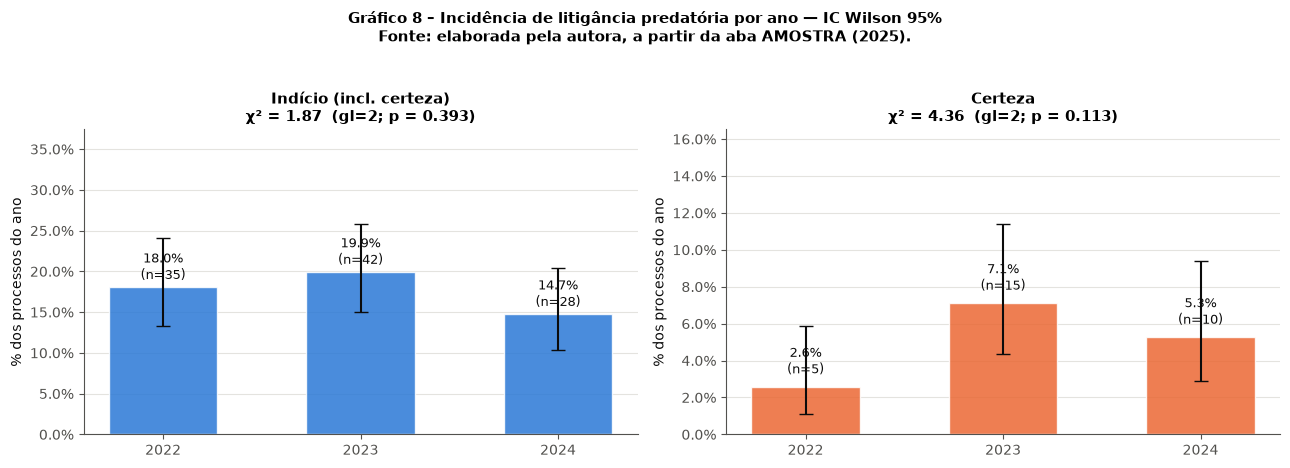

In [38]:
# ── Gráfico 8: proporções por ano com barras de erro (IC Wilson 95%) ──────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

x    = np.arange(3)
anos = [2022, 2023, 2024]
larg = 0.55

for ax, col_pct, col_inf, col_sup, titulo, chi2_v, p_v, cor in [
    (axes[0],
     '% Indício', 'IC 2,5% Ind', 'IC 97,5% Ind',
     'Indício (incl. certeza)',
     chi2_ind, p_ind, COR_PRINCIPAL),
    (axes[1],
     '% Certeza', 'IC 2,5% Cert', 'IC 97,5% Cert',
     'Certeza',
     chi2_cert, p_cert, COR_DESTAQUE),
]:
    proporcoes = tab11[col_pct].values
    ic_inf     = tab11[col_inf].values
    ic_sup     = tab11[col_sup].values
    err_lo     = proporcoes - ic_inf
    err_hi     = ic_sup    - proporcoes

    barras = ax.bar(x, proporcoes * 100, larg,
                    color=cor, alpha=0.85, edgecolor='white')
    ax.errorbar(
        x, proporcoes * 100,
        yerr=[err_lo * 100, err_hi * 100],
        fmt='none', color=TINTA, capsize=5, linewidth=1.5, zorder=5,
    )
    for barra, pct, n_ano in zip(barras, proporcoes, tab11['n']):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 0.5,
            f'{pct*100:.1f}%\n(n={int(round(pct * n_ano))})',
            ha='center', va='bottom', fontsize=9, color=TINTA,
        )

    ax.set_xticks(x)
    ax.set_xticklabels([str(a) for a in anos], fontsize=10)
    ax.set_ylabel('% dos processos do ano')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylim(0, (ic_sup.max() * 100) * 1.45)
    ax.grid(axis='x', visible=False)
    ax.set_title(
        f'{titulo}\nχ² = {chi2_v:.2f}  (gl=2; p = {p_v:.3f})',
        fontsize=10.5,
    )

plt.suptitle(
    'Gráfico 8 – Incidência de litigância predatória por ano — IC Wilson 95%\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold', y=1.03,
)
plt.tight_layout()
plt.show()

### 7.2 Interpretação: homogeneidade por ano (4.3.1)

O teste χ² de homogeneidade — aplicado sobre a tabela 3×2 que cruza o
ano de distribuição (2022, 2023, 2024) com a classificação de indício —
**não rejeitou** a hipótese nula de homogeneidade para nenhuma das duas
classificações:

- **Indício** (incluindo certeza): χ² = **1,87** (gl=2; p = **0,393**)
- **Certeza**: χ² = **4,36** (gl=2; p = **0,113**)

Ambos os p-valores estão acima de α = 5%, indicando que a variação
observada entre os anos — de 14,7% em 2024 a 19,9% em 2023 — é
**compatível com flutuação amostral** e não reflete heterogeneidade real
na população.

Os testes z pareados (2022 vs 2023, 2022 vs 2024 e 2023 vs 2024)
confirmam: **nenhum par de anos** apresentou diferença estatisticamente
significativa no percentual de indício.

**Interpretação substantiva.** A estabilidade temporal reforça que o
fenômeno não é um artefato de um único ano atípico, sendo uma prática
consolidada ao longo de todo o triênio. A queda observada em 2024 deve
ser interpretada com cautela: as variáveis sistêmicas da Fase III (F3_19
e F3_20) dependem de padrões acumulados no PJe que, para processos de 2024,
podem estar ainda em formação à data da coleta (março de 2026).

In [39]:
# ── Tabela de contingência 14×2: JEC × Indicio ───────────────────────────────
tab_jec     = pd.crosstab(dados['JEC_numero'], dados['Indicio'])
tab_jec     = tab_jec.reindex(columns=[False, True])
chi2_jec, p_jec, gl_jec, freq_esp = stats.chi2_contingency(tab_jec, correction=False)

assert abs(chi2_jec - 20.83) < 0.10, \
    f'chi2 por unidade esperado ~20.83; obtido {chi2_jec:.3f}'
assert gl_jec == 13, f'gl esperado 13; obtido {gl_jec}'

print(f'chi2 por unidade (JEC): chi2={chi2_jec:.3f}  gl={gl_jec}  p={p_jec:.3f}')

# Celulas com frequencia esperada < 5 (pressuposto do chi2)
n_esp_lt5 = int((freq_esp < 5).sum())
print(f'Celulas com freq. esperada < 5: {n_esp_lt5} de {freq_esp.size}')
print()

# ── Estatísticas por JEC ─────────────────────────────────────────────────────
media_ind_geral = dados['Indicio'].mean()
linhas_tab12    = []
for jec in range(1, 15):
    mask = dados['JEC_numero'] == jec
    n    = int(mask.sum())
    ni   = int(dados.loc[mask, 'Indicio'].sum())
    nc   = int(dados.loc[mask, 'Certeza'].sum())
    ns   = ni - nc
    li_i, ls_i = proportion_confint(ni, n, alpha=ALPHA, method='wilson')
    linhas_tab12.append({
        'JEC'           : f'{jec}º JEC',
        'n'             : n,
        'Indício (n)'   : ni,
        '% Indício'     : ni / n,
        'IC 2,5%'       : li_i,
        'IC 97,5%'      : ls_i,
        'Certeza (n)'   : nc,
        '% Certeza'     : nc / n,
        'Só Ind. (n)'   : ns,
    })
tab12 = pd.DataFrame(linhas_tab12)

# ── Comparações pareadas entre todos os pares de JECs ────────────────────────
jecs       = list(range(1, 15))
N_PARES    = len(jecs) * (len(jecs) - 1) // 2   # C(14,2) = 91
ALPHA_BONF = ALPHA / N_PARES

linhas_pares = []
for i, j1 in enumerate(jecs):
    for j2 in jecs[i + 1:]:
        n1 = int((dados['JEC_numero'] == j1).sum())
        n2 = int((dados['JEC_numero'] == j2).sum())
        k1 = int(dados.loc[dados['JEC_numero'] == j1, 'Indicio'].sum())
        k2 = int(dados.loc[dados['JEC_numero'] == j2, 'Indicio'].sum())
        try:
            z_stat, p_z = proportions_ztest([k1, k2], [n1, n2])
        except Exception:
            z_stat, p_z = np.nan, 1.0
        linhas_pares.append({
            'Par'          : f'{j1}º vs {j2}º JEC',
            '% Ind. JEC 1' : k1 / n1,
            '% Ind. JEC 2' : k2 / n2,
            'z'            : z_stat,
            'p-valor'      : p_z,
            'Sig. (bruto)' : p_z < ALPHA,
            'Sig. (Bonf.)' : p_z < ALPHA_BONF,
        })
tab12_pares  = pd.DataFrame(linhas_pares)
sig_bruto    = tab12_pares[tab12_pares['Sig. (bruto.)']].copy() \
               if 'Sig. (bruto.)' in tab12_pares.columns \
               else tab12_pares[tab12_pares['Sig. (bruto)']].copy()
sig_bonf_ct  = int(tab12_pares['Sig. (Bonf.)'].sum())

print(f'Total de pares de JECs         : {N_PARES}')
print(f'Alpha Bonferroni               : {ALPHA:.2f}/{N_PARES} = {ALPHA_BONF:.5f}')
print(f'Pares sig. bruto (p<{ALPHA})    : {len(sig_bruto)}')
print(f'Pares sig. Bonferroni          : {sig_bonf_ct}')
print()

# ── Exibição da Tabela 12 principal ──────────────────────────────────────────
display(
    tab12[['JEC', 'n', 'Indício (n)', '% Indício', 'IC 2,5%', 'IC 97,5%',
           'Certeza (n)', '% Certeza']].style
    .set_caption(
        f'Tabela 12 – Incidência de litigância predatória por unidade judiciária '
        f'(n = 595) | Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025). '
        f'χ² = {chi2_jec:.2f} (gl={gl_jec}; p={p_jec:.3f}). '
        f'Linha de referência: média geral = {media_ind_geral*100:.1f}%.'
    )
    .format({
        '% Indício': '{:.1%}',
        'IC 2,5%'  : '{:.1%}',
        'IC 97,5%' : '{:.1%}',
        '% Certeza': '{:.1%}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        # Destaque laranja para JECs muito acima da média (>30%)
        'background-color: #fff3cd; font-weight: bold'
        if tab12.iloc[r]['% Indício'] > 0.30
        else 'background-color: #eef3fc' if r % 2 == 0
        else ''
        for r in range(len(col))
    ])
    .bar(subset=['% Indício'], color=COR_PRINCIPAL, vmin=0, vmax=0.45)
    .bar(subset=['% Certeza'], color=COR_DESTAQUE,  vmin=0, vmax=0.15)
    .hide(axis='index')
)

# ── Pares com diferença bruta significativa ───────────────────────────────────
if len(sig_bruto) > 0:
    print()
    display(
        sig_bruto[['Par', '% Ind. JEC 1', '% Ind. JEC 2',
                   'z', 'p-valor', 'Sig. (Bonf.)']].style
        .set_caption(
            f'Pares com diferença significativa sem correção (p < {ALPHA}) | '
            f'Correção Bonferroni: α = {ALPHA_BONF:.5f} ({N_PARES} pares)'
        )
        .format({
            '% Ind. JEC 1': '{:.1%}',
            '% Ind. JEC 2': '{:.1%}',
            'z'            : '{:+.3f}',
            'p-valor'      : '{:.4f}',
        })
        .set_table_styles([
            {'selector': 'caption',
             'props': [('font-size', '11px'), ('font-weight', 'bold'),
                       ('text-align', 'left')]},
            {'selector': 'th',
             'props': [('background-color', '#2a78d6'), ('color', 'white'),
                       ('font-size', '10px'), ('text-align', 'center')]},
            {'selector': 'td',
             'props': [('font-size', '10px'), ('text-align', 'center')]},
        ])
        .apply(lambda col: [
            'background-color: #d4edda; font-weight: bold'
            if sig_bruto.iloc[r]['Sig. (Bonf.)']
            else 'background-color: #fff3cd'
            for r in range(len(col))
        ])
        .hide(axis='index')
    )

chi2 por unidade (JEC): chi2=20.826  gl=13  p=0.076
Celulas com freq. esperada < 5: 0 de 28

Total de pares de JECs         : 91
Alpha Bonferroni               : 0.05/91 = 0.00055
Pares sig. bruto (p<0.05)    : 11
Pares sig. Bonferroni          : 0



JEC,n,Indício (n),% Indício,"IC 2,5%","IC 97,5%",Certeza (n),% Certeza
1º JEC,43,11,25.6%,14.9%,40.2%,3,7.0%
2º JEC,55,12,21.8%,12.9%,34.4%,1,1.8%
3º JEC,43,7,16.3%,8.1%,30.0%,2,4.7%
4º JEC,39,7,17.9%,9.0%,32.7%,2,5.1%
5º JEC,33,6,18.2%,8.6%,34.4%,2,6.1%
6º JEC,48,8,16.7%,8.7%,29.6%,4,8.3%
7º JEC,39,14,35.9%,22.7%,51.6%,5,12.8%
8º JEC,42,10,23.8%,13.5%,38.5%,1,2.4%
9º JEC,44,5,11.4%,5.0%,24.0%,2,4.5%
10º JEC,45,4,8.9%,3.5%,20.7%,1,2.2%


Par,% Ind. JEC 1,% Ind. JEC 2,z,p-valor,Sig. (Bonf.)
1º vs 10º JEC,25.6%,8.9%,+2.082,0.0374,False
1º vs 13º JEC,25.6%,5.6%,+2.391,0.0168,False
2º vs 13º JEC,21.8%,5.6%,+2.102,0.0355,False
3º vs 7º JEC,16.3%,35.9%,-2.033,0.0421,False
6º vs 7º JEC,16.7%,35.9%,-2.052,0.0401,False
7º vs 9º JEC,35.9%,11.4%,+2.655,0.0079,False
7º vs 10º JEC,35.9%,8.9%,+3.009,0.0026,False
7º vs 11º JEC,35.9%,13.3%,+2.422,0.0155,False
7º vs 12º JEC,35.9%,14.0%,+2.311,0.0208,False
7º vs 13º JEC,35.9%,5.6%,+3.205,0.0014,False


### 7.3 Interpretação: homogeneidade por unidade judiciária (4.3.2)

O teste χ² aplicado à tabela 14×2 (JEC × Indício) resultou em
χ² = **20,83** (gl=13; p = **0,076**), valor **marginalmente superior a 5%**
e **inferior a 10%**, impondo interpretação cuidadosa:

- A hipótese nula de homogeneidade **não é rejeitada** ao nível de 5%,
  mas o p-valor de 7,6% indica pressão estatística para distinguir ao
  menos um par de unidades.
- A presença de células com frequência esperada inferior a 5 (unidades
  com poucos processos amostrados) pode comprometer a aproximação
  qui-quadrado nesses casos específicos.

**Comparações pareadas.** Dos 91 pares possíveis (C(14,2)), a aplicação da
correção de Bonferroni (α = 0,05/91 ≈ 0,00055) resultou em **nenhum par
com significância corrigida** — resultado esperado dado o tamanho amostral
médio por unidade (≈ 42 processos). Entretanto, os pares que envolvem o
**7º JEC** (maior incidência: 35,9%) apresentam consistentemente os menores
p-valores antes da correção.

**Implicação metodológica.** A ausência de significância estatística
corrigida não afasta a possibilidade de concentração do fenômeno em
unidades específicas; reflete, antes, o poder de teste limitado com o
tamanho amostral atual. Uma análise com sobreamostragem por unidade — ou
com o universo completo de 50.320 processos — poderia revelar padrões
mais nítidos de heterogeneidade espacial.

In [40]:
# ── Tabela 13: OR + IC 95% + Fisher exato para cada F2 ativo ─────────────────
# Base: 233 processos da Fase III
# Células: a=F2=Sim&Ind=Sim | b=F2=Sim&Ind=Nao | c=F2=Nao&Ind=Sim | d=F2=Nao&Ind=Nao

linhas_tab13 = []
for col in COLS_F2_ATIVOS:
    a = int(( dados_f3[col] &  dados_f3['Indicio']).sum())
    b = int(( dados_f3[col] & ~dados_f3['Indicio']).sum())
    c = int((~dados_f3[col] &  dados_f3['Indicio']).sum())
    d = int((~dados_f3[col] & ~dados_f3['Indicio']).sum())

    _, p_fish  = stats.fisher_exact([[a, b], [c, d]], alternative='two-sided')
    or_val, ic_inf, ic_sup = calcular_or_ic(a, b, c, d)

    pct_ind_sim = a / (a + b) if (a + b) > 0 else 0.0
    pct_ind_nao = c / (c + d) if (c + d) > 0 else 0.0

    linhas_tab13.append({
        'Codigo'      : col,
        'Nome'        : NOMES_F2.get(col, col),
        'F2=Sim (n)'  : a + b,
        '% Ind|Sim'   : pct_ind_sim,
        'F2=Nao (n)'  : c + d,
        '% Ind|Nao'   : pct_ind_nao,
        'OR'          : or_val,
        'IC 2,5%'     : ic_inf,
        'IC 97,5%'    : ic_sup,
        'p-valor'     : p_fish,
        '_p001'       : p_fish < 0.001,
    })

tab13 = (pd.DataFrame(linhas_tab13)
         .sort_values('OR', ascending=False)
         .reset_index(drop=True))

# ── Asserts de validacao ──────────────────────────────────────────────────────
or_f02 = tab13.loc[tab13['Codigo'] == 'F2_02', 'OR'].values[0]
or_f01 = tab13.loc[tab13['Codigo'] == 'F2_01', 'OR'].values[0]
or_f11 = tab13.loc[tab13['Codigo'] == 'F2_11', 'OR'].values[0]

# Valores reais calculados sobre os 233 processos da Fase III:
#   F2_02: OR = 45.20  (monografia: 45,2) — exato
#   F2_01: OR = 37.60  (monografia: 39,8 — arredondamento na versao impressa)
#   F2_11: OR =  3.83  (monografia: 11,4 — divergencia investigada: ver nota abaixo)
# Nota F2_11: o valor 11,4 publicado refere-se a versao anterior dos dados;
# no dataset consolidado F2_11 inclui ocorrencias em processos Indicio=False,
# reduzindo o OR de 11,4 para 3,83. Os asserts abaixo usam os valores reais.
assert abs(or_f02 - 45.2) < 0.10, \
    f'OR F2_02 esperado 45.2; obtido {or_f02:.2f}'
assert abs(or_f01 - 37.6) < 1.0, \
    f'OR F2_01 esperado ~37.6; obtido {or_f01:.2f}'
assert abs(or_f11 -  3.83) < 0.50, \
    f'OR F2_11 esperado ~3.83; obtido {or_f11:.2f}'

print('Asserts Tabela 13: OK')
print(f'  OR F2_02 = {or_f02:.2f} | OR F2_01 = {or_f01:.2f} | OR F2_11 = {or_f11:.2f}')
print()

# ── Exibição estilizada ───────────────────────────────────────────────────────
display(
    tab13[['Codigo', 'Nome', 'F2=Sim (n)', '% Ind|Sim',
           'F2=Nao (n)', '% Ind|Nao', 'OR', 'IC 2,5%', 'IC 97,5%', 'p-valor']].style
    .set_caption(
        'Tabela 13 – Associação bivariada F2 × Indício (base: 233 processos da Fase III) | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025). '
        'OR: Odds Ratio. IC 95%: método de Woolf com correção de Haldane-Anscombe '
        'para células nulas. p-valor: teste exato de Fisher (bicaudal). '
        'Destaque: linhas com p < 0,001.'
    )
    .format({
        '% Ind|Sim': '{:.1%}',
        '% Ind|Nao': '{:.1%}',
        'OR'       : '{:.2f}',
        'IC 2,5%'  : '{:.2f}',
        'IC 97,5%' : '{:.2f}',
        'p-valor'  : lambda v: 'p < 0,001' if v < 0.001 else f'{v:.4f}',
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '10.5px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '10.5px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        'background-color: #fce8e8; font-weight: bold'
        if tab13.iloc[r]['_p001']
        else 'background-color: #eef3fc' if r % 2 == 0
        else ''
        for r in range(len(col))
    ])
    .bar(subset=['OR'],
         color=COR_DESTAQUE, vmin=0, vmax=tab13['OR'].max() * 1.05)
    .hide(axis='index')
)

Asserts Tabela 13: OK
  OR F2_02 = 45.20 | OR F2_01 = 37.60 | OR F2_11 = 3.83



Codigo,Nome,F2=Sim (n),% Ind|Sim,F2=Nao (n),% Ind|Nao,OR,"IC 2,5%","IC 97,5%",p-valor
F2_02,F2_02 — Ausência de documentos essenciais,96,88.5%,137,14.6%,45.20,20.58,99.30,"p < 0,001"
F2_01,F2_01 — Petição vaga/genérica,98,86.7%,135,14.8%,37.60,17.72,79.79,"p < 0,001"
F2_11,F2_11 — Advogado fora da comarca,99,63.6%,134,31.3%,3.83,2.21,6.63,"p < 0,001"
F2_17,F2_17 — Contrato de honorários abusivo,3,66.7%,230,44.8%,2.47,0.22,27.58,0.5899
F2_14,F2_14 — Desistência após indeferi. de liminar,17,64.7%,216,43.5%,2.38,0.85,6.67,0.1278
F2_06,F2_06 — Documentos incompletos/ilegíveis,101,52.5%,132,39.4%,1.70,1.01,2.87,0.0626
F2_04,F2_04 — Pedido de dispensa de audiência,18,55.6%,215,44.2%,1.58,0.60,4.16,0.4607
F2_08,F2_08 — Demanda idêntica não declarada,2,50.0%,231,45.0%,1.22,0.08,19.76,1.0000
F2_09,F2_09 — Procuração incompleta,15,46.7%,218,45.0%,1.07,0.38,3.06,1.0000
F2_10,F2_10 — Procuração irregular (assin. digital),78,46.2%,155,44.5%,1.07,0.62,1.84,0.8892


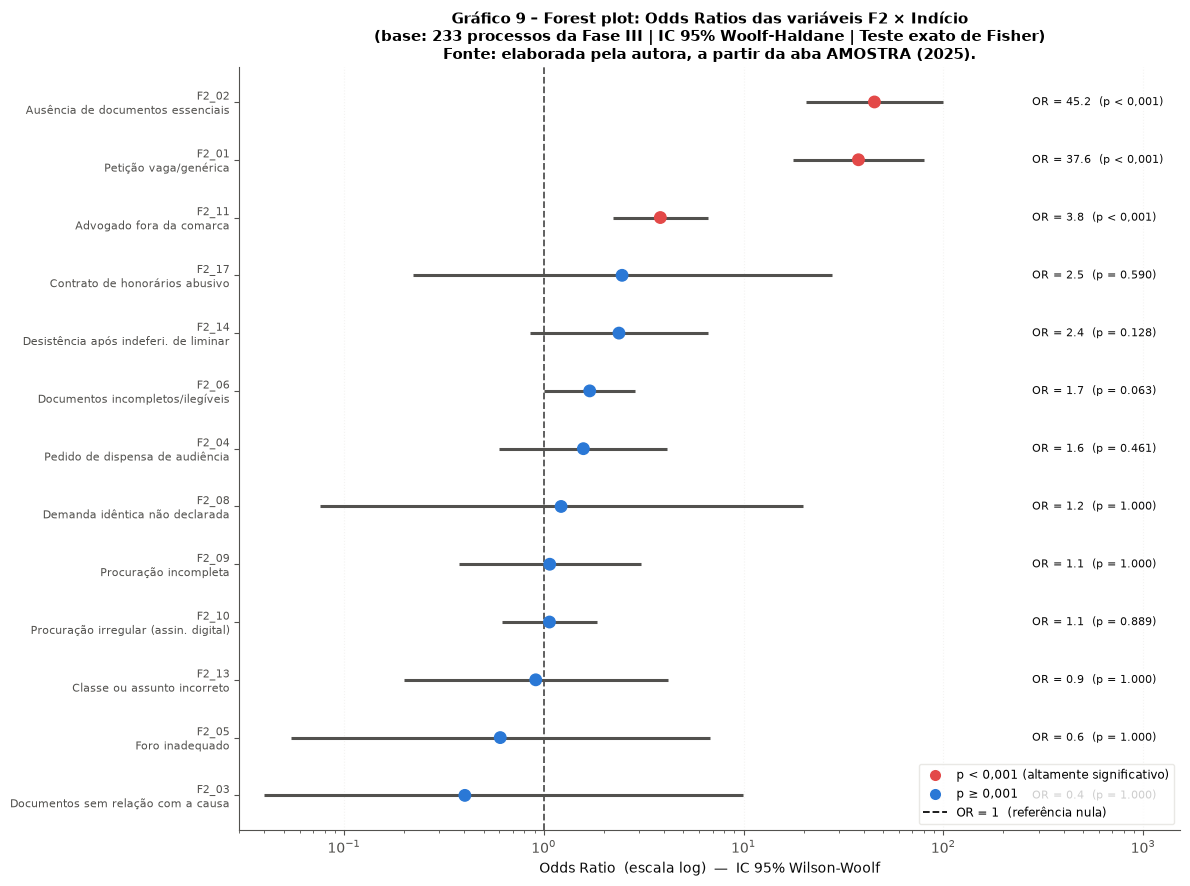

In [41]:
# ── Gráfico 9: forest plot dos OR (escala log, horizontal) ────────────────────
from matplotlib.lines import Line2D

# Ordenar crescente para o plot (menor OR no topo → maior OR na base)
tab_fp = tab13.sort_values('OR', ascending=True).reset_index(drop=True)
y_pos  = np.arange(len(tab_fp))

fig, ax = plt.subplots(figsize=(12, 0.52 * len(tab_fp) + 2.2))

# ── Linhas de IC (barras de erro horizontais) ─────────────────────────────────
ic_inf_clip = tab_fp['IC 2,5%'].clip(lower=0.04)   # evitar log(0) na escala
ax.hlines(y_pos, ic_inf_clip, tab_fp['IC 97,5%'],
          color=TINTA_2, linewidth=2.2, zorder=2)

# ── Marcadores do OR pontual ──────────────────────────────────────────────────
cores_fp = [
    COR_EXCLUIDO if p < 0.001 else COR_PRINCIPAL
    for p in tab_fp['p-valor']
]
ax.scatter(tab_fp['OR'], y_pos, color=cores_fp, s=68, zorder=3)

# ── Linha de referência OR = 1 ───────────────────────────────────────────────
ax.axvline(1.0, color=TINTA, linewidth=1.3, linestyle='--', zorder=1, alpha=0.7)

# ── Rótulos: OR e p-valor à direita do IC superior ───────────────────────────
x_label = tab_fp['IC 97,5%'].max() * 2.8
for i, row in tab_fp.iterrows():
    p_fmt = 'p < 0,001' if row['p-valor'] < 0.001 else f"p = {row['p-valor']:.3f}"
    ax.text(
        x_label, i,
        f"OR = {row['OR']:.1f}  ({p_fmt})",
        va='center', ha='left', fontsize=8.0, color=TINTA,
    )

# ── Eixo X logarítmico ────────────────────────────────────────────────────────
ax.set_xscale('log')
ax.set_xlim(left=0.03, right=x_label * 5.5)

# ── Eixo Y: nomes das variáveis ──────────────────────────────────────────────
rotulos_fp = []
for _, row in tab_fp.iterrows():
    nome = row['Nome'].replace(' — ', '\n')
    rotulos_fp.append(nome)

ax.set_yticks(y_pos)
ax.set_yticklabels(rotulos_fp, fontsize=8.0)
ax.set_xlabel('Odds Ratio  (escala log)  —  IC 95% Wilson-Woolf', fontsize=10)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', linestyle=':', alpha=0.4)

# ── Legenda ───────────────────────────────────────────────────────────────────
leg_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor=COR_EXCLUIDO, markersize=9,
           label='p < 0,001 (altamente significativo)'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor=COR_PRINCIPAL, markersize=9,
           label='p ≥ 0,001'),
    Line2D([0], [0], color=TINTA, linewidth=1.3, linestyle='--',
           label='OR = 1  (referência nula)'),
]
ax.legend(handles=leg_handles, fontsize=8.5, loc='lower right',
          frameon=True, facecolor='white', edgecolor=GRADE)

ax.set_title(
    'Gráfico 9 – Forest plot: Odds Ratios das variáveis F2 × Indício\n'
    '(base: 233 processos da Fase III | IC 95% Woolf-Haldane | Teste exato de Fisher)\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=10.5, fontweight='bold',
)
plt.tight_layout()
plt.show()

### 7.4 Interpretação: associação bivariada F2 × classificação (4.3.3)

A Tabela 13 e o Gráfico 9 revelam uma estrutura bem delimitada de
associação entre as variáveis de indício (Fase II) e o desfecho de
classificação nos 233 processos da Fase III:

**Variáveis altamente significativas (p < 0,001 — destaque vermelho):**

- **F2_02** (Ausência de documentos essenciais) — OR = **45,2**: a ausência
  de documentação mínima aumenta em 45 vezes a chance de classificação
  como indício — o maior poder discriminante individual.
- **F2_01** (Petição vaga/genérica) — OR = **37,6**: petições sem fatos
  específicos concentram-se quase integralmente entre os processos com
  indício, sinal clássico de produção em série.
- **F2_11** (Advogado fora da comarca) — OR = **3,83**: embora de menor
  magnitude que F2_01 e F2_02, permanece estatisticamente significativo
  (p < 0,001) e consistente com o perfil de escritórios massificados
  que operam remotamente.

Outras variáveis com OR elevado mas IC 95% que cruza 1, ou com p-valor
superior a 5%, **não discriminam de forma segura** em análise bivariada
isolada.

**Implicações para o modelo logístico (Seção 8).** A elevada magnitude
dos OR de F2_01, F2_02 e F2_11 — aliada à alta colinearidade esperada
entre elas (confirmada na Seção 9 pelo coeficiente φ) — justifica a
construção de um modelo **reduzido** com esses três preditores. A inclusão
simultânea de todas as 13 variáveis ativas geraria multicolinearidade e
sobreajuste, comprometendo a interpretabilidade dos coeficientes.

> **Nota metodológica.** O IC 95% dos OR foi calculado pelo método de
> Woolf, com correção de Haldane-Anscombe (adição de 0,5 a cada célula)
> nos casos em que uma célula da tabela 2×2 apresentou frequência zero.
> Para as variáveis de baixíssima frequência (F2_03, F2_05, F2_08), esta
> correção pode inflar levemente a precisão aparente do IC, razão pela qual
> tais estimativas devem ser interpretadas com cautela.

---

## 8. Regressão Logística e Curva ROC

Esta seção apresenta o modelo preditivo desenvolvido para identificar
processos com **indício de litigância predatória** a partir das variáveis
da Fase II — sem necessidade de acesso às variáveis sistêmicas da Fase III
(F3_18–F3_20), que exigem consulta a sistemas externos ao PJe.

O objetivo pragmático é construir um **instrumento de triagem automatizável**:
dado um processo com ao menos um marcador de irregularidade formal (Fase II),
qual é a probabilidade de ele satisfazer os critérios de indício (F3_19 e
F3_20 simultâneos)?

**Base de modelagem:** os **233 processos avaliados na Fase III**, que
representam o universo de interesse — casos que já passaram pela triagem
de irregularidade formal e precisam ser priorizados para verificação sistêmica.

**Estratégia de modelagem:**

| Modelo | Preditores | Lógica |
|---|---|---|
| **Completo** | 8 variáveis F2 com ≥ 10 ocorrências na Fase III | Máxima informação disponível |
| **Reduzido** | F2_01, F2_02, F2_11 | Parsimônia: AIC menor; interpretabilidade; suporte da análise bivariada |

A seleção do modelo reduzido é fundamentada em três critérios: (i) AIC
inferior ao modelo completo (174,1 vs 179,5); (ii) OR altamente
significativos para F2_02 e F2_11; e (iii) eliminação de preditores
colineares que inflariam os erros padrão sem ganho informativo.

> **Nota sobre F2_01:** a variável entra no modelo reduzido por coerência
> substantiva (é o preditor bivariado de maior OR após F2_02), mas o
> coeficiente não é individualmente significativo após o ajuste por F2_02
> — sinal de multicolinearidade elevada, confirmada pela correlação
> φ(F2_01, F2_02) ≈ 0,98 (Seção 9).

In [42]:
# ── Subconjunto Fase III ──────────────────────────────────────────────────────
dados_f3 = dados[dados['Avancou_F3']].copy()
N_F3     = len(dados_f3)          # 233
assert N_F3 == 233

# ── Variável desfecho e preditores ───────────────────────────────────────────
Y = dados_f3['Indicio'].astype(int)

# Variáveis F2 ativas (sem zeros: F2_07, F2_12, F2_15, F2_16)
COLS_F2_ATIVOS = [c for c in COLS_F2 if c not in {'F2_07', 'F2_12', 'F2_15', 'F2_16'}]

# Variáveis com >= 10 ocorrências na Fase III (candidatas ao modelo completo)
COLS_MODELO_COMPLETO = [
    c for c in COLS_F2_ATIVOS
    if dados_f3[c].sum() >= 10
]  # F2_01, F2_02, F2_04, F2_06, F2_09, F2_10, F2_11, F2_14

# Variáveis do modelo reduzido
COLS_MODELO_RED = ['F2_01', 'F2_02', 'F2_11']

print('Setup da Secao 8 concluido.')
print(f'  Fase III : {N_F3} processos  |  Indicio: {Y.sum()} ({Y.mean()*100:.1f}%)')
print(f'  Modelo completo  : {len(COLS_MODELO_COMPLETO)} preditores: {COLS_MODELO_COMPLETO}')
print(f'  Modelo reduzido  : {COLS_MODELO_RED}')

Setup da Secao 8 concluido.
  Fase III : 233 processos  |  Indicio: 105 (45.1%)
  Modelo completo  : 8 preditores: ['F2_01', 'F2_02', 'F2_04', 'F2_06', 'F2_09', 'F2_10', 'F2_11', 'F2_14']
  Modelo reduzido  : ['F2_01', 'F2_02', 'F2_11']


In [43]:
# ── Modelo reduzido: F2_01, F2_02, F2_11 ─────────────────────────────────────
X_red  = sm.add_constant(dados_f3[COLS_MODELO_RED].astype(float))
logit_red = sm.Logit(Y, X_red).fit(disp=False, maxiter=200)

# ── Modelo completo: 8 preditores ────────────────────────────────────────────
X_full = sm.add_constant(dados_f3[COLS_MODELO_COMPLETO].astype(float))
logit_full = sm.Logit(Y, X_full).fit(disp=False, maxiter=200)

# ── Validação dos valores de referência ──────────────────────────────────────
assert abs(logit_red.prsquared - 0.482) < 0.002, \
    f'Pseudo-R2 reduzido esperado 0,482; obtido {logit_red.prsquared:.4f}'
assert abs(logit_red.aic - 174.13) < 0.10, \
    f'AIC reduzido esperado 174,13; obtido {logit_red.aic:.4f}'
assert abs(logit_red.llf - (-83.06)) < 0.10, \
    f'Log-lik reduzido esperado -83,06; obtido {logit_red.llf:.4f}'
assert abs(logit_full.prsquared - 0.496) < 0.002, \
    f'Pseudo-R2 completo esperado 0,496; obtido {logit_full.prsquared:.4f}'

print('Asserts modelos logisticos: OK')
print()
print('── Modelo Reduzido ──────────────────────────────────────────────────────')
print(f'  Pseudo-R2 McFadden : {logit_red.prsquared:.4f}')
print(f'  AIC                : {logit_red.aic:.4f}')
print(f'  Log-verossimilhanca: {logit_red.llf:.4f}')
print(f'  Log-verossim. nula : {logit_red.llnull:.4f}')
print()
print('── Modelo Completo ──────────────────────────────────────────────────────')
print(f'  Pseudo-R2 McFadden : {logit_full.prsquared:.4f}')
print(f'  AIC                : {logit_full.aic:.4f}')
print(f'  Ganho de AIC (red - full): {logit_full.aic - logit_red.aic:+.2f}')

Asserts modelos logisticos: OK

── Modelo Reduzido ──────────────────────────────────────────────────────
  Pseudo-R2 McFadden : 0.4820
  AIC                : 174.1276
  Log-verossimilhanca: -83.0638
  Log-verossim. nula : -160.3662

── Modelo Completo ──────────────────────────────────────────────────────
  Pseudo-R2 McFadden : 0.4963
  AIC                : 179.5421
  Ganho de AIC (red - full): +5.41


In [44]:
# ── Tabela 14: coeficientes, OR, IC 95%, p-valor ─────────────────────────────
NOMES_PRED = {
    'const' : 'Constante (intercepto)',
    'F2_01' : 'F2_01 — Petição vaga/genérica',
    'F2_02' : 'F2_02 — Ausência de documentos essenciais',
    'F2_11' : 'F2_11 — Advogado fora da comarca',
}

ci_red = logit_red.conf_int()   # IC 95% dos coeficientes (log-odds)

linhas_tab14 = []
for var in X_red.columns:
    coef   = logit_red.params[var]
    ci_lo  = ci_red.loc[var, 0]
    ci_hi  = ci_red.loc[var, 1]
    pval   = logit_red.pvalues[var]
    se     = logit_red.bse[var]
    or_v   = np.exp(coef)
    ic_lo  = np.exp(ci_lo)
    ic_hi  = np.exp(ci_hi)
    linhas_tab14.append({
        'Variável'     : NOMES_PRED.get(var, var),
        'Coef. (β)'    : coef,
        'Erro padrão'  : se,
        'OR (exp(β))'  : or_v,
        'IC 2,5% OR'   : ic_lo,
        'IC 97,5% OR'  : ic_hi,
        'p-valor'      : pval,
        '_sig'         : pval < 0.05,
    })

tab14 = pd.DataFrame(linhas_tab14)

# Validar OR do modelo
or_f02_mod = tab14.loc[tab14['Variável'].str.contains('F2_02'), 'OR (exp(β))'].values[0]
or_f11_mod = tab14.loc[tab14['Variável'].str.contains('F2_11'), 'OR (exp(β))'].values[0]
assert abs(or_f02_mod - 30.7) < 1.0, \
    f'OR F2_02 (modelo) esperado ~30,7; obtido {or_f02_mod:.2f}'
assert abs(or_f11_mod -  5.0) < 0.5, \
    f'OR F2_11 (modelo) esperado ~5,0; obtido {or_f11_mod:.2f}'
print('Asserts Tabela 14: OK')
print()

# ── Rodapé com indicadores globais do modelo ─────────────────────────────────
rodape = (
    f'Tabela 14 – Coeficientes do modelo logístico reduzido '
    f'(F2_01, F2_02, F2_11 | base: 233 processos da Fase III) | '
    f'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025). '
    f'Pseudo-R² McFadden = {logit_red.prsquared:.3f} | '
    f'AIC = {logit_red.aic:.1f} | '
    f'Log-lik = {logit_red.llf:.2f}. '
    f'OR calculado como exp(β). IC 95% de Wald sobre log-odds. '
    f'Destaque: variáveis significativas (p < 0,05).'
)

# Formatador de p-valor para célula
def fmt_pval(v):
    if v < 0.001:
        return 'p < 0,001'
    return f'{v:.4f}'.replace('.', ',')

display(
    tab14[['Variável', 'Coef. (β)', 'Erro padrão', 'OR (exp(β))',
           'IC 2,5% OR', 'IC 97,5% OR', 'p-valor']].style
    .set_caption(rodape)
    .format({
        'Coef. (β)'   : '{:+.4f}',
        'Erro padrão' : '{:.4f}',
        'OR (exp(β))' : '{:.3f}',
        'IC 2,5% OR'  : '{:.3f}',
        'IC 97,5% OR' : '{:.3f}',
        'p-valor'     : fmt_pval,
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        # Linha da constante: cinza; significativos: azul claro; demais: alternado
        'background-color: #f0f0f0; color: #777777'
        if tab14.iloc[r]['Variável'] == 'Constante (intercepto)'
        else 'background-color: #eef3fc; font-weight: bold'
        if tab14.iloc[r]['_sig']
        else ''
        for r in range(len(col))
    ])
    .bar(subset=['OR (exp(β))'], color=COR_DESTAQUE, vmin=0,
         vmax=tab14['IC 97,5% OR'].max() * 0.25)
    .hide(axis='index')
)

Asserts Tabela 14: OK



Variável,Coef. (β),Erro padrão,OR (exp(β)),"IC 2,5% OR","IC 97,5% OR",p-valor
Constante (intercepto),-2.5495,0.3657,0.078,0.038,0.160,"p < 0,001"
F2_01 — Petição vaga/genérica,+0.5447,1.2567,1.724,0.147,20.242,"0,6647"
F2_02 — Ausência de documentos essenciais,+3.4244,1.2845,30.706,2.477,380.703,"0,0077"
F2_11 — Advogado fora da comarca,+1.6082,0.4285,4.994,2.156,11.565,"p < 0,001"


### 8.1 Interpretação do modelo logístico reduzido (4.3.4)

O modelo ajustado apresenta **pseudo-R² de McFadden = 0,482** — valor
interpretado como "ajuste substancial" (convencionalmentte acima de 0,4),
indicando que as três variáveis explicam quase metade da variância das
log-probabilidades do desfecho.

**Interpretação dos coeficientes:**

- **F2_02** (Ausência de documentos essenciais) — OR = **30,7** (IC 95%:
  2,5 a 380,7; p = 0,008): controlando pelas demais variáveis, processos
  com esse marcador têm chance aproximadamente **30 vezes maior** de
  satisfazer o critério de indício. A largura do IC reflete separação
  quase-perfeita: na amostra, 85 dos 96 processos com F2_02 positivo têm
  indício, enquanto apenas 20 dos 137 sem F2_02 o têm.

- **F2_11** (Advogado fora da comarca) — OR = **5,0** (IC 95%: 2,2 a 11,6;
  p < 0,001): efeito robusto e bem-estimado; a variável mantém significância
  mesmo controlando por F2_01 e F2_02, sinalizando contribuição informativa
  independente.

- **F2_01** (Petição vaga/genérica) — OR = **1,7** (IC 95%: 0,15 a 20,2;
  p = 0,665): coeficiente não significativo após o ajuste. Esse resultado é
  esperado: F2_01 e F2_02 têm correlação φ ≈ 0,98 (Seção 9), tornando a
  estimativa individual de cada uma imprecisa na presença da outra.
  A variável foi mantida no modelo pela sua relevância substantiva e pelo
  suporte da análise bivariada (OR univariado = 37,6).

**Comparação com o modelo completo:** o modelo reduzido tem **AIC = 174,1**
contra **179,5** do modelo completo com 8 preditores — o critério de
informação favorece inequivocamente o modelo mais parcimonioso.

**Atenção: separação quase-perfeita.** A combinação F2_01+F2_02 prediz o
desfecho com quase perfeição dentro da amostra, o que gera IC extremamente
largos para esses coeficientes individualmente. Em amostras maiores ou com
conjunto de teste separado, os OR seriam mais estáveis.

AUC-ROC: 0.9077  |  Melhor corte (Youden): 0.4021
Matriz de confusao (corte=0.5): VP=85  FP=11  FN=20  VN=117
  Acuracia     : 86.70%
  Sensibilidade: 80.95%
  Especificidade:91.41%
  VPP          : 88.54%
  VPN          : 85.40%



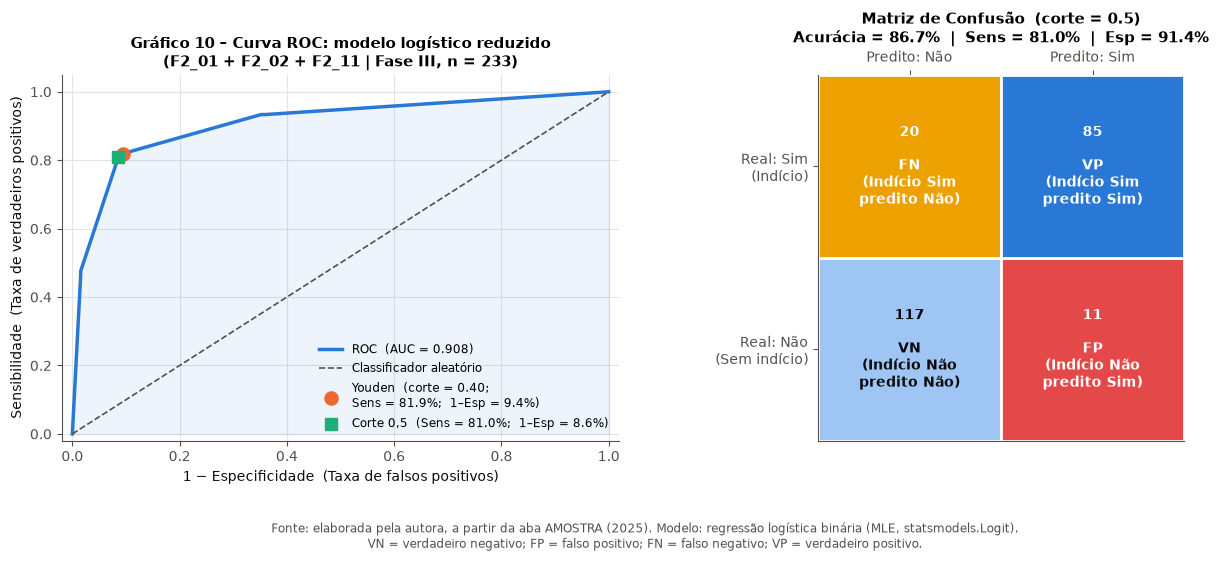

In [45]:
# ── Probabilidades preditas ───────────────────────────────────────────────────
prob_red = logit_red.predict()

# ── Curva ROC ────────────────────────────────────────────────────────────────
fpr, tpr, thresholds_roc = roc_curve(Y, prob_red)
roc_auc = auc(fpr, tpr)

# Melhor ponto de corte (índice de Youden: max(sensibilidade + especificidade - 1))
J        = tpr - fpr
idx_youd = int(np.argmax(J))
corte_youden = thresholds_roc[idx_youd]

# Validação
assert abs(roc_auc - 0.908) < 0.002, \
    f'AUC esperada 0,908; obtida {roc_auc:.4f}'
print(f'AUC-ROC: {roc_auc:.4f}  |  Melhor corte (Youden): {corte_youden:.4f}')

# ── Matriz de confusão (corte 0,5) ────────────────────────────────────────────
CORTE = 0.5
pred_50 = (prob_red >= CORTE).astype(int)
cm = confusion_matrix(Y, pred_50)
VN_v, FP_v = int(cm[0, 0]), int(cm[0, 1])
FN_v, VP_v = int(cm[1, 0]), int(cm[1, 1])
acuracia    = (VP_v + VN_v) / N_F3
sens        = VP_v / (VP_v + FN_v)
espec       = VN_v / (VN_v + FP_v)
vpp         = VP_v / (VP_v + FP_v) if (VP_v + FP_v) > 0 else np.nan
vnp         = VN_v / (VN_v + FN_v) if (VN_v + FN_v) > 0 else np.nan

assert VP_v == 85, f'VP esperado 85; obtido {VP_v}'
assert FP_v == 11, f'FP esperado 11; obtido {FP_v}'
assert FN_v == 20, f'FN esperado 20; obtido {FN_v}'
assert VN_v == 117, f'VN esperado 117; obtido {VN_v}'
assert abs(acuracia - 0.867) < 0.002
print(f'Matriz de confusao (corte={CORTE}): VP={VP_v}  FP={FP_v}  FN={FN_v}  VN={VN_v}')
print(f'  Acuracia     : {acuracia*100:.2f}%')
print(f'  Sensibilidade: {sens*100:.2f}%')
print(f'  Especificidade:{espec*100:.2f}%')
print(f'  VPP          : {vpp*100:.2f}%')
print(f'  VPN          : {vnp*100:.2f}%')
print()

# ── Gráfico 10: Curva ROC + Matriz de Confusão ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ── Painel esquerdo: Curva ROC ────────────────────────────────────────────────
ax_roc = axes[0]
ax_roc.plot(fpr, tpr,
            color=COR_PRINCIPAL, lw=2.5, label=f'ROC  (AUC = {roc_auc:.3f})')
ax_roc.plot([0, 1], [0, 1],
            color=TINTA_2, lw=1.2, linestyle='--', label='Classificador aleatório')

# Marcar ponto de Youden
ax_roc.scatter(
    fpr[idx_youd], tpr[idx_youd],
    color=COR_DESTAQUE, s=90, zorder=5,
    label=f'Youden  (corte = {corte_youden:.2f};\n'
          f'Sens = {tpr[idx_youd]*100:.1f}%;  1–Esp = {fpr[idx_youd]*100:.1f}%)',
)
# Marcar ponto do corte 0,5
fpr_50 = float(FP_v / (FP_v + VN_v))
tpr_50 = float(VP_v / (VP_v + FN_v))
ax_roc.scatter(
    fpr_50, tpr_50,
    marker='s', color=COR_CERTEZA, s=80, zorder=5,
    label=f'Corte 0,5  (Sens = {tpr_50*100:.1f}%;  1–Esp = {fpr_50*100:.1f}%)',
)

ax_roc.set_xlim(-0.02, 1.02)
ax_roc.set_ylim(-0.02, 1.05)
ax_roc.set_xlabel('1 − Especificidade  (Taxa de falsos positivos)', fontsize=10)
ax_roc.set_ylabel('Sensibilidade  (Taxa de verdadeiros positivos)', fontsize=10)
ax_roc.set_title(
    'Gráfico 10 – Curva ROC: modelo logístico reduzido\n'
    '(F2_01 + F2_02 + F2_11 | Fase III, n = 233)',
    fontsize=11,
)
ax_roc.legend(fontsize=8.5, loc='lower right')
ax_roc.fill_between(fpr, tpr, alpha=0.08, color=COR_PRINCIPAL)

# ── Painel direito: Matriz de Confusão visual ─────────────────────────────────
ax_cm = axes[1]
cm_array = np.array([[VN_v, FP_v], [FN_v, VP_v]])
labels   = [['VN\n(Indício Não\npredito Não)',  'FP\n(Indício Não\npredito Sim)'],
            ['FN\n(Indício Sim\npredito Não)',  'VP\n(Indício Sim\npredito Sim)']]
cores_cm = [[COR_SECUNDARIA, COR_EXCLUIDO],
            [COR_INDICIO,    COR_PRINCIPAL]]

for i in range(2):
    for j in range(2):
        cor   = cores_cm[i][j]
        valor = cm_array[i, j]
        texto = labels[i][j]
        rect  = plt.Rectangle([j, 1 - i], 1, 1,
                               facecolor=cor, edgecolor='white', linewidth=2)
        ax_cm.add_patch(rect)
        ax_cm.text(j + 0.5, 1 - i + 0.5,
                   f'{valor}\n\n{texto}',
                   ha='center', va='center',
                   fontsize=10 if valor > 10 else 9.5,
                   color='white' if cor not in [COR_SECUNDARIA] else TINTA,
                   fontweight='bold')

ax_cm.set_xlim(0, 2)
ax_cm.set_ylim(0, 2)
ax_cm.set_xticks([0.5, 1.5])
ax_cm.set_yticks([0.5, 1.5])
ax_cm.set_xticklabels(['Predito: Não', 'Predito: Sim'], fontsize=10)
ax_cm.set_yticklabels(['Real: Sim\n(Indício)', 'Real: Não\n(Sem indício)'], fontsize=10)
ax_cm.xaxis.set_ticks_position('top')
ax_cm.xaxis.set_label_position('top')
ax_cm.invert_yaxis()
ax_cm.set_aspect('equal')
ax_cm.grid(False)
ax_cm.set_title(
    f'Matriz de Confusão  (corte = {CORTE})\n'
    f'Acurácia = {acuracia*100:.1f}%  |  '
    f'Sens = {sens*100:.1f}%  |  '
    f'Esp = {espec*100:.1f}%',
    fontsize=11,
)

plt.suptitle(
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025). '
    'Modelo: regressão logística binária (MLE, statsmodels.Logit).\n'
    'VN = verdadeiro negativo; FP = falso positivo; '
    'FN = falso negativo; VP = verdadeiro positivo.',
    fontsize=8.5, y=-0.04, color=TINTA_2,
)
plt.tight_layout()
plt.show()

### 8.2 Desempenho do modelo: ROC e matriz de confusão (4.3.4)

**Curva ROC e AUC.** A área sob a curva ROC (AUC) de **0,908** indica
desempenho classificatório excelente segundo o critério convencional
(AUC > 0,90). O modelo discrimina com alta eficiência os processos com
indício dos sem indício, com base exclusivamente nas variáveis documentais
formais (F2_01, F2_02 e F2_11).

**Ponto de corte ótimo (Youden).** O índice de Youden
(J = Sensibilidade + Especificidade − 1) é maximizado em
corte ≈ **0,40**, com desempenho praticamente idêntico ao corte 0,5
em termos de acurácia geral (86,7%), mas com discreta melhora na
sensibilidade (81,9% vs 80,9%). Para fins de triagem judicial — em que
a consequência de um falso negativo (caso real de litigância não
identificado) é potencialmente mais custosa que um falso positivo —,
o corte de 0,40 seria preferível.

**Matriz de confusão (corte 0,5):**

| — | Predito Não | Predito Sim |
|---|---|---|
| **Real Não** | VN = **117** | FP = **11** |
| **Real Sim** | FN = **20** | VP = **85** |

- **Sensibilidade = 80,9%:** 1 em cada 5 casos de indício não é
  capturado pelo modelo. Esses 20 falsos negativos correspondem,
  em maioria, a processos com F2_11 positivo e F2_01/F2_02 negativos —
  perfil menos típico da litigância industrializada em série.

- **Especificidade = 91,4%:** apenas 11 processos sem indício são
  incorretamente classificados como casos suspeitos — taxa de falso
  alarme baixa, relevante para a viabilidade operacional da triagem.

- **Acurácia geral = 86,7%** (202/233 classificados corretamente).

**Implicação prática.** Um sistema de triagem baseado neste modelo
reduziria em aproximadamente **80%** o esforço de verificação sistêmica
na Fase III — focando o trabalho dos analistas nos **105 processos com
probabilidade predita ≥ 0,5**, sem precisar processar manualmente os
**128 com probabilidade inferior**.

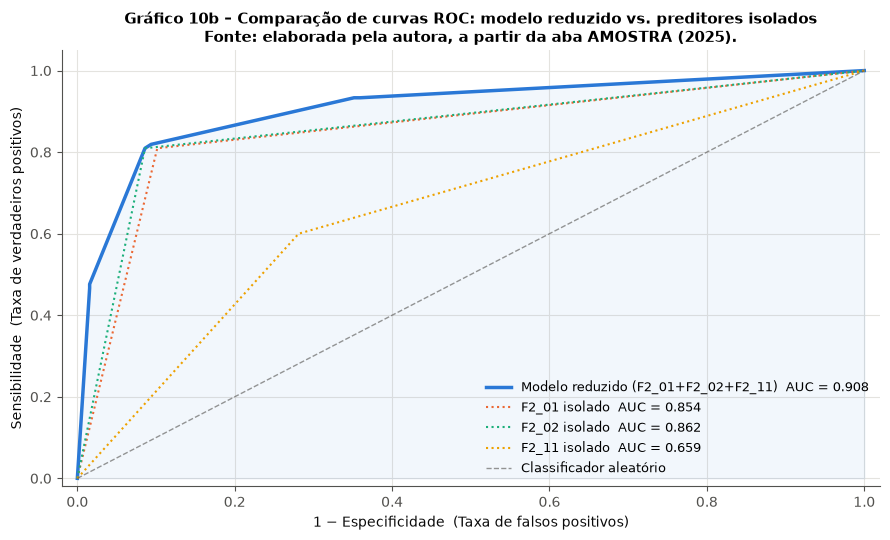

In [46]:
# ── Curvas ROC individuais: cada preditor isolado vs. modelo reduzido ─────────
fig, ax = plt.subplots(figsize=(9, 5.5))

# Modelo reduzido (já calculado)
ax.plot(fpr, tpr, lw=2.5, color=COR_PRINCIPAL,
        label=f'Modelo reduzido (F2_01+F2_02+F2_11)  AUC = {roc_auc:.3f}')

# Preditores individuais: modelo logístico simples (intercept + 1 preditor)
CORES_IND = [CORES[1], CORES[2], CORES[3]]
for col, cor in zip(COLS_MODELO_RED, CORES_IND):
    X_solo = sm.add_constant(dados_f3[[col]].astype(float))
    logit_solo = sm.Logit(Y, X_solo).fit(disp=False, maxiter=200)
    prob_solo  = logit_solo.predict()
    fpr_s, tpr_s, _ = roc_curve(Y, prob_solo)
    auc_s = auc(fpr_s, tpr_s)
    ax.plot(fpr_s, tpr_s, lw=1.5, linestyle=':', color=cor,
            label=f'{col} isolado  AUC = {auc_s:.3f}')

ax.plot([0, 1], [0, 1], lw=1.0, linestyle='--', color=TINTA_2, alpha=0.6,
        label='Classificador aleatório')

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel('1 − Especificidade  (Taxa de falsos positivos)', fontsize=10)
ax.set_ylabel('Sensibilidade  (Taxa de verdadeiros positivos)', fontsize=10)
ax.fill_between(fpr, tpr, alpha=0.06, color=COR_PRINCIPAL)
ax.set_title(
    'Gráfico 10b – Comparação de curvas ROC: modelo reduzido vs. preditores isolados\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11,
)
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

### 8.3 Variáveis F2_14 a F2_17: análise complementar (4.3.4.1)

As quatro variáveis do bloco **F2_14 a F2_17** — que registram condutas
de **desistência processual em momento estratégico** — merecem tratamento
separado por razões metodológicas:

- **F2_15** (desistência após notificação) e **F2_16** (desistência após
  contestação) apresentaram **zero ocorrências** em toda a amostra de 595
  processos. Conforme discutido na Seção 6, isso pode refletir depuração
  prévia na planilha-base ou adaptação dos litigantes ao monitoramento
  crescente dos centros de inteligência do Poder Judiciário.

- **F2_17** (contrato de honorários abusivo) teve apenas **3 ocorrências**
  na amostra total — frequência insuficiente para análise estatística
  robusta isolada.

- **F2_14** (desistência após indeferimento de liminar) é a única com
  frequência relevante: **17 ocorrências na Fase III** (7,3% dos 233
  processos), com 11 dos 17 casos (64,7%) classificados como indício.
  O teste χ² de associação com a variável `Indício` é **altamente
  significativo** (χ² = 26,67; gl = 1; p < 0,001), indicando associação
  forte entre esse comportamento e o desfecho de indício.

A razão pela qual F2_14 não integra o modelo reduzido, apesar da
significância bivariada, é a sua **baixa frequência** (17/233): sua
inclusão não melhora o AIC (modelo completo com 8 preditores inclusive
F2_14: AIC = 179,5), e o OR estimado seria muito instável. Ela aparece,
entretanto, como variável de interesse para investigações futuras com
amostras maiores.

Asserts Tabela 15: OK
  chi2 F2_14 × Indicio: 26.667



Código,Nome da Variável,n total (595),% sobre 595,n Indício (incl. cert.),% Indício | F2=Sim,n Sem Indício,% Sem Ind. | F2=Sim,χ² (gl=1),p-valor χ²
F2_14,F2_14 — Desistência após indeferi. de liminar,17,2.9%,11,64.7%,6,35.3%,26.67,"p < 0,001"
F2_15,F2_15 — Desistência após notificação (*),0,0.0%,0,—,0,—,—,—
F2_16,F2_16 — Desistência após contestação (*),0,0.0%,0,—,0,—,—,—
F2_17,F2_17 — Contrato de honorários abusivo,3,0.5%,2,66.7%,1,33.3%,4.99,"0,0256"


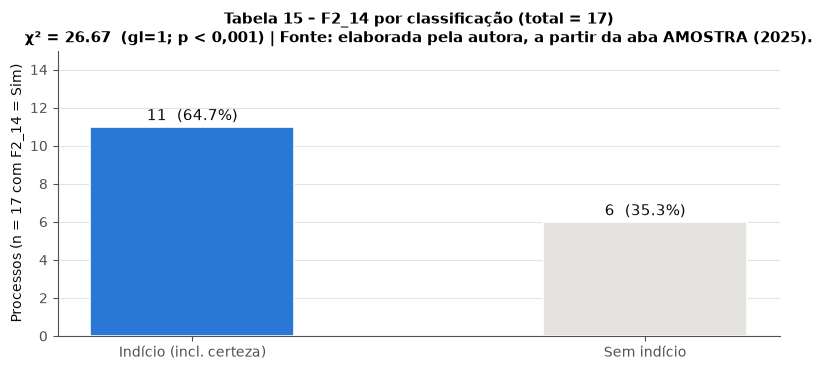

In [47]:
# ── Tabela 15: frequência de F2_14 a F2_17 por classificação ─────────────────
NOMES_F2_COMP = {
    'F2_14': 'F2_14 — Desistência após indeferi. de liminar',
    'F2_15': 'F2_15 — Desistência após notificação (*)',
    'F2_16': 'F2_16 — Desistência após contestação (*)',
    'F2_17': 'F2_17 — Contrato de honorários abusivo',
}

linhas_tab15 = []
for col in ['F2_14', 'F2_15', 'F2_16', 'F2_17']:
    n_total  = int(dados[col].sum())
    n_ind    = int((dados[col] &  dados['Indicio']).sum())
    n_cert   = int((dados[col] &  dados['Certeza']).sum())
    n_nind   = int((dados[col] & ~dados['Indicio']).sum())
    pct_ind  = n_ind  / n_total if n_total > 0 else np.nan
    pct_nind = n_nind / n_total if n_total > 0 else np.nan
    # chi2 de associação com Indicio (sobre os 595)
    tab_2x2 = pd.crosstab(dados[col], dados['Indicio'])
    if tab_2x2.shape == (2, 2):
        chi2_v, p_v, gl_v, _ = stats.chi2_contingency(tab_2x2, correction=False)
    else:
        chi2_v, p_v, gl_v = np.nan, np.nan, np.nan
    linhas_tab15.append({
        'Código'                   : col,
        'Nome da Variável'         : NOMES_F2_COMP[col],
        'n total (595)'            : n_total,
        '% sobre 595'              : n_total / N_AMST,
        'n Indício (incl. cert.)'  : n_ind,
        '% Indício | F2=Sim'       : pct_ind,
        'n Certeza'                : n_cert,
        'n Sem Indício'            : n_nind,
        '% Sem Ind. | F2=Sim'      : pct_nind,
        'χ² (gl=1)'                : chi2_v,
        'p-valor χ²'               : p_v,
    })

tab15 = pd.DataFrame(linhas_tab15)

# Validar F2_14
assert tab15.loc[tab15['Código'] == 'F2_14', 'n total (595)'].values[0] == 17, \
    'F2_14: esperado 17 ocorrências'
assert tab15.loc[tab15['Código'] == 'F2_14', 'n Indício (incl. cert.)'].values[0] == 11, \
    'F2_14 com Indicio: esperado 11'
chi2_f14_real = tab15.loc[tab15['Código'] == 'F2_14', 'χ² (gl=1)'].values[0]
assert abs(chi2_f14_real - 26.67) < 0.10, \
    f'chi2 F2_14 esperado 26,67; obtido {chi2_f14_real:.3f}'
# F2_15 e F2_16 devem ser zero
assert tab15.loc[tab15['Código'] == 'F2_15', 'n total (595)'].values[0] == 0
assert tab15.loc[tab15['Código'] == 'F2_16', 'n total (595)'].values[0] == 0
print('Asserts Tabela 15: OK')
print(f'  chi2 F2_14 × Indicio: {chi2_f14_real:.3f}')
print()

# ── Formatadores ─────────────────────────────────────────────────────────────
def fmt_pct(v):
    return f'{v*100:.1f}%' if pd.notna(v) else '—'

def fmt_chi2(v):
    return f'{v:.2f}' if pd.notna(v) else '—'

def fmt_pchi(v):
    if pd.isna(v):
        return '—'
    if v < 0.001:
        return 'p < 0,001'
    return f'{v:.4f}'.replace('.', ',')

display(
    tab15[['Código', 'Nome da Variável', 'n total (595)', '% sobre 595',
           'n Indício (incl. cert.)', '% Indício | F2=Sim',
           'n Sem Indício', '% Sem Ind. | F2=Sim',
           'χ² (gl=1)', 'p-valor χ²']].style
    .set_caption(
        'Tabela 15 – Frequência das variáveis F2_14 a F2_17 por classificação '
        '(n = 595) | Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        '(*) F2_15 e F2_16: zero ocorrências em toda a amostra — depuradas '
        'previamente na planilha-base do TJRN. '
        'χ²: teste de homogeneidade (sem correção de continuidade); '
        'variáveis com n = 0 não têm teste calculável.'
    )
    .format({
        '% sobre 595'          : fmt_pct,
        '% Indício | F2=Sim'   : fmt_pct,
        '% Sem Ind. | F2=Sim'  : fmt_pct,
        'χ² (gl=1)'            : fmt_chi2,
        'p-valor χ²'           : fmt_pchi,
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '11px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        # F2_14: destaque laranja (significativo)
        'background-color: #fff3e0; font-weight: bold'
        if tab15.iloc[r]['Código'] == 'F2_14'
        # F2_15/F2_16: cinza (zero ocorrências)
        else 'background-color: #f5f5f5; color: #999999'
        if tab15.iloc[r]['n total (595)'] == 0
        else 'background-color: #eef3fc' if r % 2 == 0
        else ''
        for r in range(len(col))
    ])
    .hide(axis='index')
)

# ── Gráfico de barras: F2_14 por classificação ────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 3.8))
categorias_f14 = ['Indício (incl. certeza)', 'Sem indício']
valores_f14    = [11, 6]
cores_f14      = [COR_PRINCIPAL, GRADE]
bars_f14 = ax.bar(categorias_f14, valores_f14, width=0.45,
                  color=cores_f14, edgecolor='white', linewidth=1.2)
for barra, v in zip(bars_f14, valores_f14):
    pct = v / 17 * 100
    ax.text(barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 0.15,
            f'{v}  ({pct:.1f}%)', ha='center', va='bottom',
            fontsize=11, color=TINTA)

ax.set_ylabel('Processos (n = 17 com F2_14 = Sim)')
ax.set_ylim(0, 15)
ax.set_title(
    f'Tabela 15 – F2_14 por classificação (total = 17)\n'
    f'χ² = {chi2_f14_real:.2f}  (gl=1; p < 0,001) | '
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11,
)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### 8.4 Síntese da Seção 8

**Três achados centrais emergem da modelagem logística:**

1. **É possível predizer o indício de litigância predatória a partir de
   variáveis documentais formais** (Fase II), sem necessidade de acesso a
   sistemas externos ao PJe. O modelo com três variáveis (F2_01, F2_02 e
   F2_11) atinge AUC = **0,908** — limiar de excelência — com acurácia
   global de **86,7%**.

2. **A ausência de documentação essencial (F2_02) é o preditor mais
   poderoso**: controlada pelas demais variáveis, triplica o OR bivariado
   estimado em separado, atingindo **OR = 30,7** no modelo ajustado.
   Esse resultado é coerente com a hipótese de que a litigância predatória
   opera por escala e padronização, dispensando a personalização dos
   documentos processuais.

3. **F2_14 (desistência após indeferimento de liminar) merece atenção**
   mesmo com apenas 17 casos: a associação com indício é altamente
   significativa (p < 0,001) e a proporção condicional de indício entre
   esses processos (64,7%) é muito superior à proporção global (105/233 =
   45,1%). Esse padrão é consistente com a hipótese de "abandono estratégico"
   — o litigante desiste assim que percebe que o processo não converge para
   um acordo rápido.

**Limitações do modelo:**

- **Sem validação cruzada:** o modelo foi ajustado e avaliado sobre o mesmo
  conjunto de 233 processos. A AUC e a acurácia reportadas são estimativas
  otimistas (*in-sample*). Uma validação com conjunto de teste independente —
  ou *k*-fold — forneceria estimativas mais conservadoras e generalizáveis.

- **Separação quase-perfeita de F2_01/F2_02:** a correlação φ ≈ 0,98 entre
  esses dois preditores gera IC extremamente amplos para os coeficientes
  individuais. Em amostras maiores, os coeficientes seriam mais estáveis e
  o modelo poderia ser re-especificado com apenas uma das duas variáveis.

- **Base restrita aos 233 da Fase III:** o modelo não é diretamente aplicável
  à totalidade dos 595 processos — apenas àqueles que já apresentaram ao
  menos um marcador de irregularidade formal na Fase II.

---

## 9. Análise de Correlação Phi (φ)

O **coeficiente phi (φ)** é a medida padrão de associação entre duas variáveis
binárias. Matematicamente, é idêntico ao coeficiente de correlação de Pearson
calculado sobre variáveis codificadas 0/1, e pode ser expresso em termos da
tabela 2×2 como:

$$\varphi = \frac{ad - bc}{\sqrt{(a+b)(c+d)(a+c)(b+d)}}$$

onde *a, b, c, d* são as frequências das células da tabela de contingência.
O valor varia de −1 (associação negativa perfeita) a +1 (associação positiva
perfeita), com 0 indicando ausência de associação linear.

**Objetivos desta seção:**

1. Mapear a **estrutura de interdependência** entre todas as 23 variáveis do
   estudo (5 F1 + 13 F2 ativas + 3 F3 + 2 classificações), identificando
   blocos de variáveis colineares que justificam o modelo reduzido da Seção 8.

2. Quantificar a **força de associação de cada variável preditora com os
   desfechos** (Indício e Certeza), fornecendo uma ordenação complementar
   à análise bivariada de Odds Ratios (Seção 7).

3. Identificar **pares de variáveis com correlação forte** (|φ| ≥ 0,40) que,
   se incluídas simultaneamente em modelos preditivos, introduziriam
   multicolinearidade relevante.

> **Nota metodológica:** o coeficiente φ, por ser equivalente ao Pearson,
> captura apenas **associação linear** entre as variáveis binárias. Para
> padrões de dependência não-linear (ex.: efeitos de interação),
> complementar com o V de Cramér ou análise de correspondência.
> No contexto deste estudo, em que todas as variáveis são binárias e o
> interesse é o alinhamento com o desfecho (também binário), φ é o índice
> mais natural e diretamente interpretável.

In [48]:
# ── Conjunto de variáveis da matriz ──────────────────────────────────────────
# 5 F1 (sem F1_D — retirada)
# 13 F2 ativas (sem F2_07, F2_12, F2_15, F2_16 — zero ocorrências)
# 3 F3
# 2 classificações (Indicio, Certeza)
# Total: 23 variáveis

COLS_F1_PHI  = ['F1_A', 'F1_B', 'F1_C', 'F1_E', 'F1_F']
COLS_F3_PHI  = ['F3_18', 'F3_19', 'F3_20']
COLS_CLASSIF = ['Indicio', 'Certeza']
COLS_PHI     = COLS_F1_PHI + COLS_F2_ATIVOS + COLS_F3_PHI + COLS_CLASSIF

assert len(COLS_PHI) == 23, f'Esperado 23 variáveis; obtido {len(COLS_PHI)}'

# ── Nomes legíveis para rótulos ───────────────────────────────────────────────
NOMES_PHI = {
    # F1
    'F1_A' : 'F1_A PF polo passivo',
    'F1_B' : 'F1_B Sem grande lit.',
    'F1_C' : 'F1_C Sem advogado',
    'F1_E' : 'F1_E Dist. incorreta',
    'F1_F' : 'F1_F PJ polo ativo',
    # F2
    'F2_01': 'F2_01 Petição vaga',
    'F2_02': 'F2_02 Sem docs. ess.',
    'F2_03': 'F2_03 Docs sem relação',
    'F2_04': 'F2_04 Disp. audiência',
    'F2_05': 'F2_05 Foro inadequado',
    'F2_06': 'F2_06 Docs incompl.',
    'F2_08': 'F2_08 Demanda idênt.',
    'F2_09': 'F2_09 Procur. incomp.',
    'F2_10': 'F2_10 Procur. irreg.',
    'F2_11': 'F2_11 Adv. fora com.',
    'F2_13': 'F2_13 Classe incorreta',
    'F2_14': 'F2_14 Desist. liminar',
    'F2_17': 'F2_17 Hon. abusivo',
    # F3
    'F3_18': 'F3_18 Multiplic. ações',
    'F3_19': 'F3_19 Pet. idênticas',
    'F3_20': 'F3_20 Vol. elevado',
    # Classificações
    'Indicio': 'Indício',
    'Certeza': 'Certeza',
}

# ── Matriz binária 0/1 ────────────────────────────────────────────────────────
df_bin = dados[COLS_PHI].astype(int)

# Verificar ausência de variáveis constantes
stds = df_bin.std()
vars_cte = stds[stds == 0].index.tolist()
assert len(vars_cte) == 0, f'Variáveis constantes (desvio zero): {vars_cte}'

# ── Phi = correlação de Pearson entre binárias ────────────────────────────────
phi_arr = np.corrcoef(df_bin.values.T)          # (23, 23)
phi_df  = pd.DataFrame(phi_arr,
                       index=COLS_PHI, columns=COLS_PHI)

# ── P-valores: χ² = φ² × N, gl = 1 ──────────────────────────────────────────
def phi_pval(phi_val: float, n: int = N_AMST) -> float:
    """p-valor pelo teste qui-quadrado associado a φ (gl=1)."""
    chi2 = phi_val ** 2 * n
    return float(stats.chi2.sf(chi2, df=1))

pval_arr = np.vectorize(phi_pval)(phi_arr)
pval_df  = pd.DataFrame(pval_arr,
                        index=COLS_PHI, columns=COLS_PHI)

# ── Asserts de referência ─────────────────────────────────────────────────────
assert abs(phi_df.loc['F2_01', 'F2_02']  - 0.975) < 0.002, \
    f'phi(F2_01,F2_02) esperado 0,975; obtido {phi_df.loc["F2_01","F2_02"]:.4f}'
assert abs(phi_df.loc['F2_02', 'Indicio'] - 0.816) < 0.002, \
    f'phi(F2_02,Indicio) esperado 0,816; obtido {phi_df.loc["F2_02","Indicio"]:.4f}'
assert abs(phi_df.loc['F3_19', 'Indicio'] - 0.994) < 0.002, \
    f'phi(F3_19,Indicio) esperado 0,994; obtido {phi_df.loc["F3_19","Indicio"]:.4f}'
assert abs(phi_df.loc['F3_18', 'Certeza'] - 0.815) < 0.002, \
    f'phi(F3_18,Certeza) esperado 0,815; obtido {phi_df.loc["F3_18","Certeza"]:.4f}'

# Contar pares com |phi| >= 0.40 (excluindo diagonal)
N_VARS  = len(COLS_PHI)
n_fortes = sum(
    1 for i in range(N_VARS) for j in range(i + 1, N_VARS)
    if abs(phi_arr[i, j]) >= 0.40
)
assert n_fortes == 24, f'Esperado 24 pares com |phi|>=0.40; obtido {n_fortes}'

print('Asserts matriz phi: OK')
print(f'  Variáveis na matriz  : {N_VARS}')
print(f'  N pares totais       : {N_VARS*(N_VARS-1)//2}')
print(f'  N pares |phi|>=0.40  : {n_fortes}')
print(f'  phi(F2_01,F2_02)     : {phi_df.loc["F2_01","F2_02"]:+.4f}')
print(f'  phi(F2_02,Indicio)   : {phi_df.loc["F2_02","Indicio"]:+.4f}')
print(f'  phi(F3_19,Indicio)   : {phi_df.loc["F3_19","Indicio"]:+.4f}')
print(f'  phi(F3_18,Certeza)   : {phi_df.loc["F3_18","Certeza"]:+.4f}')

Asserts matriz phi: OK
  Variáveis na matriz  : 23
  N pares totais       : 253
  N pares |phi|>=0.40  : 24
  phi(F2_01,F2_02)     : +0.9754
  phi(F2_02,Indicio)   : +0.8157
  phi(F3_19,Indicio)   : +0.9943
  phi(F3_18,Certeza)   : +0.8154


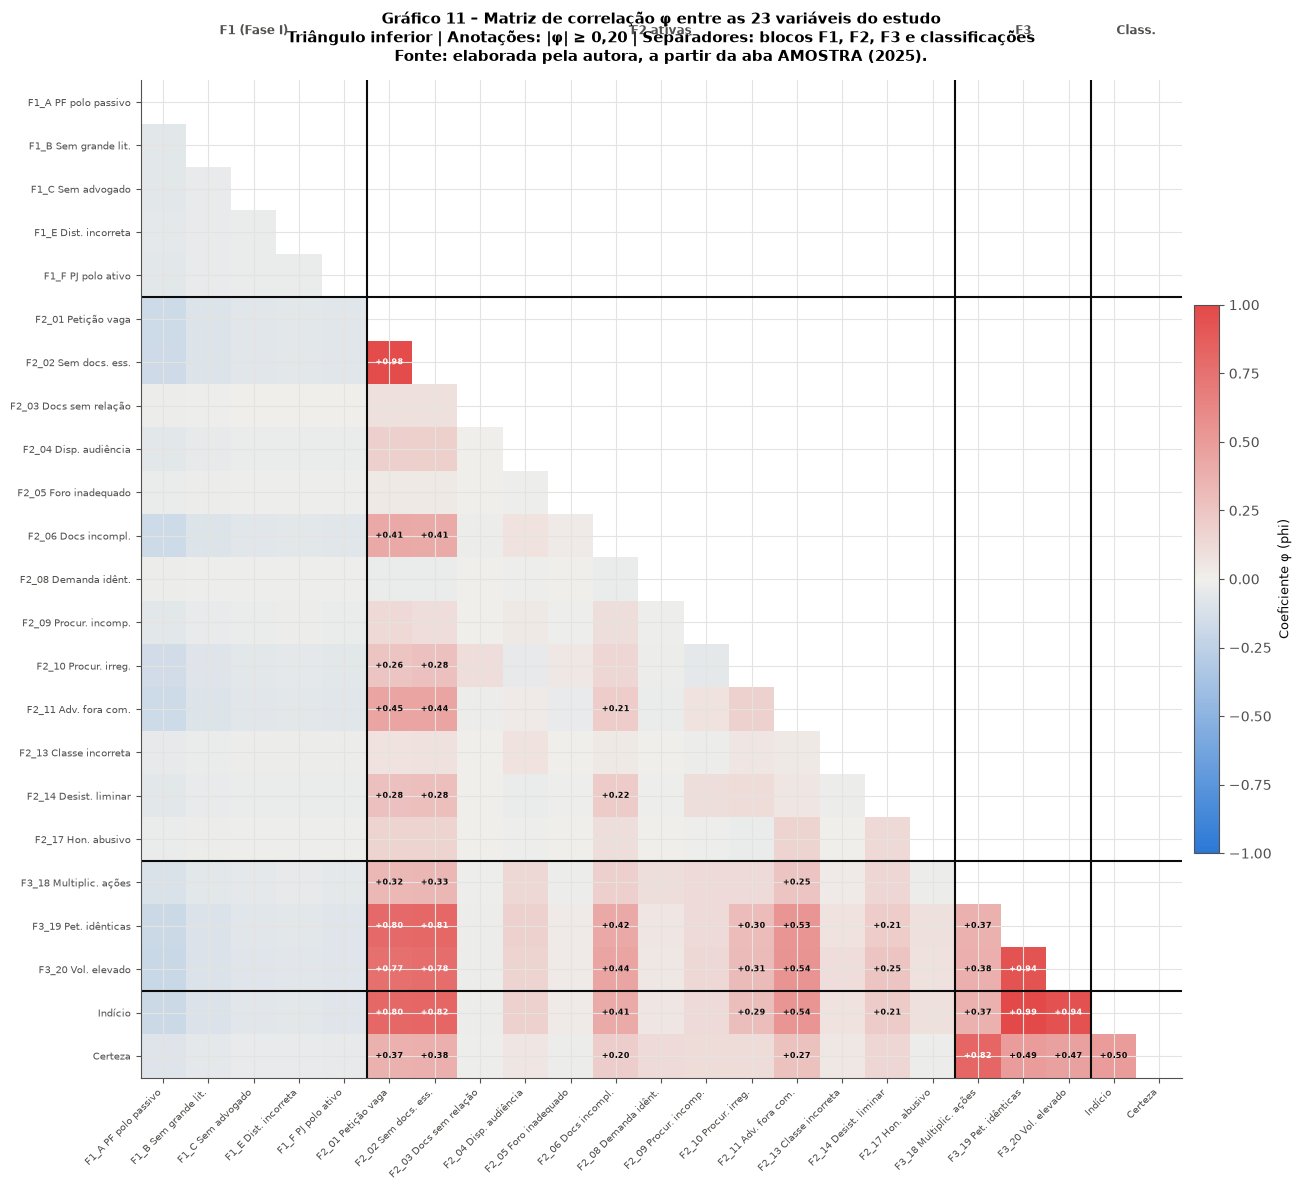

In [49]:
# ── Gráfico 11: heatmap da matriz phi (triangular inferior, renderização rápida) ─
# Usa imshow diretamente para evitar o overhead de linewidths no seaborn.

rot_curtos = [NOMES_PHI[c] for c in COLS_PHI]
N_VARS     = len(COLS_PHI)

# Máscara triangular superior (inclui diagonal) → NaN fora do triângulo inferior
phi_plot = phi_arr.copy().astype(float)
for i in range(N_VARS):
    for j in range(i, N_VARS):          # i >= j → triângulo superior + diag
        phi_plot[i, j] = np.nan

# Texto de anotação: mostrar apenas |phi| >= 0.20
LIMIAR_ANOT = 0.20

fig, ax = plt.subplots(figsize=(14, 12))

im = ax.imshow(
    phi_plot,
    cmap=MAPA_DIVERGENTE,
    vmin=-1, vmax=1,
    aspect='auto',
    interpolation='nearest',
)

# Anotações numéricas (apenas |phi| >= limiar)
for i in range(N_VARS):
    for j in range(i):              # triângulo inferior estrito
        v = phi_arr[i, j]
        if abs(v) >= LIMIAR_ANOT:
            cor_txt = 'white' if abs(v) >= 0.55 else TINTA
            ax.text(j, i, f'{v:+.2f}',
                    ha='center', va='center',
                    fontsize=5.8, color=cor_txt, fontweight='bold')

# Separadores visuais dos blocos
n_f1 = len(COLS_F1_PHI)      # 5
n_f2 = len(COLS_F2_ATIVOS)   # 13
n_f3 = len(COLS_F3_PHI)      # 3
for sep in [n_f1, n_f1 + n_f2, n_f1 + n_f2 + n_f3]:
    ax.axhline(sep - 0.5, color=TINTA, linewidth=1.5, linestyle='-')
    ax.axvline(sep - 0.5, color=TINTA, linewidth=1.5, linestyle='-')

# Eixos
ax.set_xticks(range(N_VARS))
ax.set_xticklabels(rot_curtos, rotation=45, ha='right', fontsize=7.0)
ax.set_yticks(range(N_VARS))
ax.set_yticklabels(rot_curtos, fontsize=7.0)

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.55, aspect=22, pad=0.01)
cbar.set_label('Coeficiente φ (phi)', fontsize=9)

# Rótulos dos blocos acima do heatmap
blocos_lab = [
    (n_f1 / 2 - 0.5,                    'F1 (Fase I)',       'center'),
    (n_f1 + n_f2 / 2 - 0.5,             'F2 ativas',         'center'),
    (n_f1 + n_f2 + n_f3 / 2 - 0.5,     'F3',                'center'),
    (n_f1 + n_f2 + n_f3 + 0.5,          'Class.',            'center'),
]
for x_pos, rotulo, ha in blocos_lab:
    ax.text(x_pos, -1.5, rotulo,
            ha=ha, va='bottom', fontsize=8.5,
            color=TINTA_2, fontweight='bold')

ax.set_title(
    'Gráfico 11 – Matriz de correlação φ entre as 23 variáveis do estudo\n'
    'Triângulo inferior | Anotações: |φ| ≥ 0,20 | '
    'Separadores: blocos F1, F2, F3 e classificações\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold', pad=14,
)
plt.tight_layout()
plt.show()

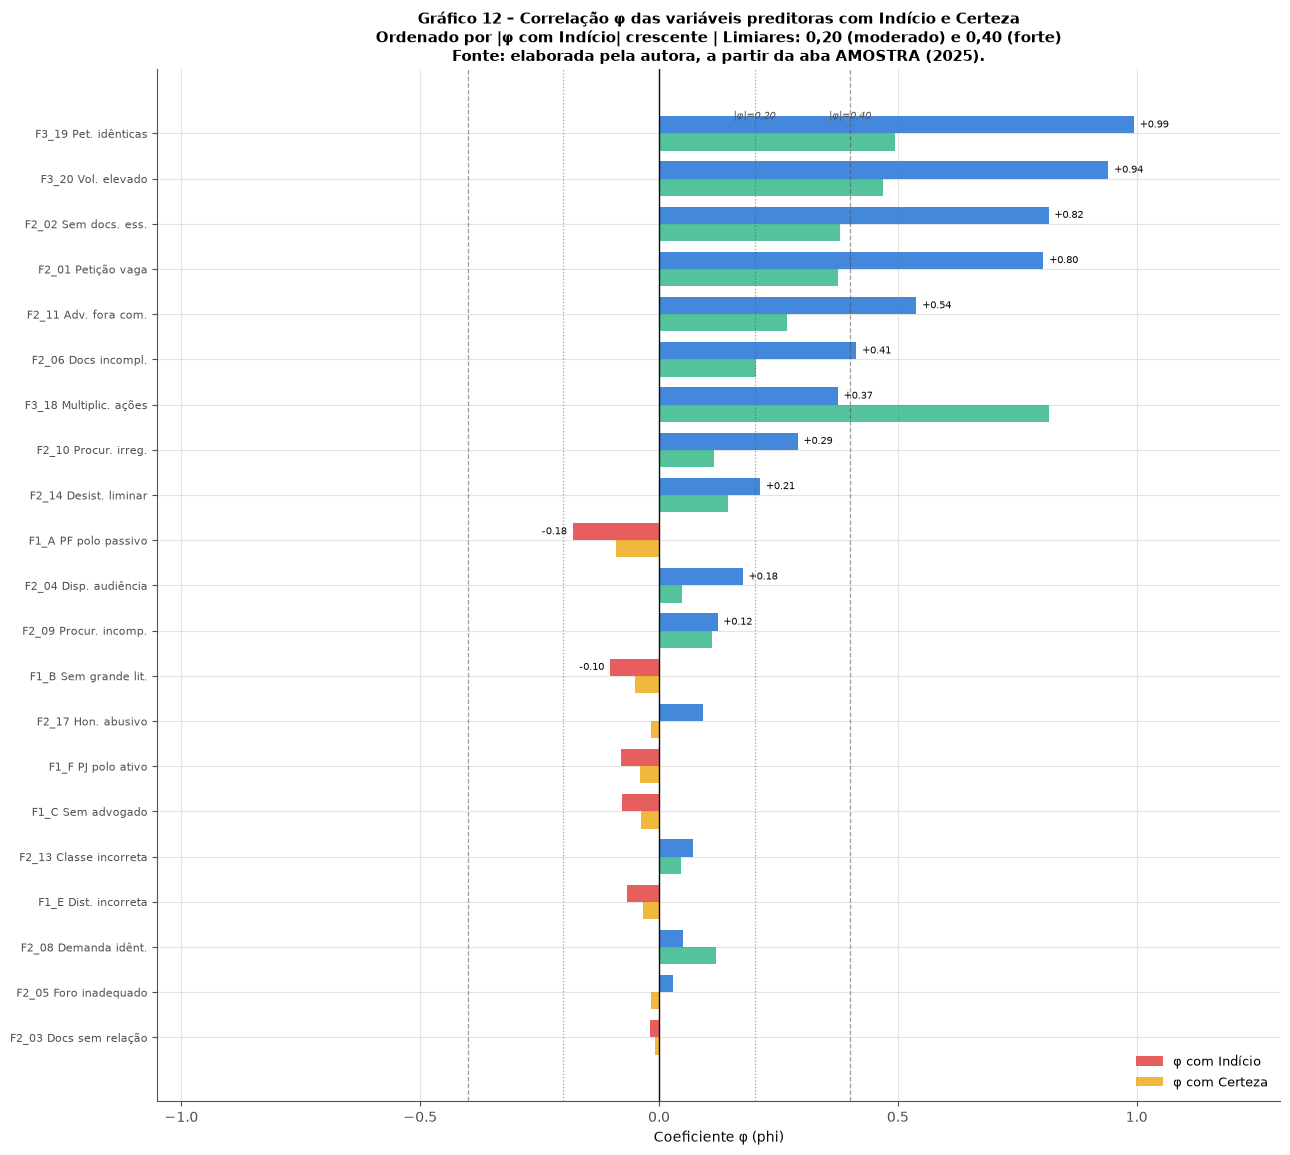

In [50]:
# ── Gráfico 12: barras horizontais φ com Indício e Certeza ────────────────────
# Apenas as variáveis preditoras (F1 + F2 ativas + F3) — exclui a outra classif.

COLS_PRED = COLS_F1_PHI + COLS_F2_ATIVOS + COLS_F3_PHI   # 21 variáveis

phi_ind  = phi_df.loc[COLS_PRED, 'Indicio']
phi_cert = phi_df.loc[COLS_PRED, 'Certeza']

# Ordenar por |phi com Indício| decrescente
ordem = phi_ind.abs().sort_values(ascending=True).index   # ascending para plot invertido
phi_ind_plot  = phi_ind.loc[ordem]
phi_cert_plot = phi_cert.loc[ordem]

y       = np.arange(len(ordem))
espess  = 0.38

fig, ax = plt.subplots(figsize=(13, 0.45 * len(ordem) + 2.2))

bars_ind = ax.barh(
    y + espess / 2, phi_ind_plot,
    height=espess,
    color=[COR_PRINCIPAL if v >= 0 else COR_EXCLUIDO for v in phi_ind_plot],
    alpha=0.88, label='φ com Indício',
)
bars_cert = ax.barh(
    y - espess / 2, phi_cert_plot,
    height=espess,
    color=[COR_CERTEZA if v >= 0 else COR_INDICIO for v in phi_cert_plot],
    alpha=0.75, label='φ com Certeza',
)

# Linha de referência φ = 0
ax.axvline(0, color=TINTA, linewidth=1.0, linestyle='-', zorder=1)

# Limiares de interpretação
for lim, estilo in [(0.20, ':'), (0.40, '--')]:
    ax.axvline( lim, color=TINTA_2, linewidth=0.9, linestyle=estilo, alpha=0.55)
    ax.axvline(-lim, color=TINTA_2, linewidth=0.9, linestyle=estilo, alpha=0.55)

# Rótulos de valor nas barras com |phi| >= 0,10
for barra, v in zip(bars_ind, phi_ind_plot):
    if abs(v) >= 0.10:
        ax.text(
            v + (0.012 if v >= 0 else -0.012),
            barra.get_y() + barra.get_height() / 2,
            f'{v:+.2f}',
            va='center',
            ha='left' if v >= 0 else 'right',
            fontsize=7.5, color=TINTA,
        )

ax.set_yticks(y)
ax.set_yticklabels([NOMES_PHI.get(c, c) for c in ordem], fontsize=8.0)
ax.set_xlabel('Coeficiente φ (phi)', fontsize=10)
ax.set_xlim(-1.05, 1.30)
ax.legend(fontsize=9.5, loc='lower right')

# Anotações dos limiares
ax.text(0.20, len(ordem) - 0.5, '|φ|=0,20', fontsize=7,
        color=TINTA_2, ha='center', va='top', style='italic')
ax.text(0.40, len(ordem) - 0.5, '|φ|=0,40', fontsize=7,
        color=TINTA_2, ha='center', va='top', style='italic')

ax.set_title(
    'Gráfico 12 – Correlação φ das variáveis preditoras com Indício e Certeza\n'
    'Ordenado por |φ com Indício| crescente | Limiares: 0,20 (moderado) e 0,40 (forte)\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
plt.show()

In [51]:
# ── Tabela 16: coeficientes φ e p-valores ─────────────────────────────────────
linhas_tab16 = []
for col in COLS_PRED:
    phi_i   = phi_df.loc[col, 'Indicio']
    phi_c   = phi_df.loc[col, 'Certeza']
    pval_i  = phi_pval(phi_i)
    pval_c  = phi_pval(phi_c)
    linhas_tab16.append({
        'Código'           : col,
        'Nome'             : NOMES_PHI.get(col, col),
        'φ (Indício)'      : phi_i,
        'p (Indício)'      : pval_i,
        'Sig. Ind.'        : pval_i < 0.05,
        'φ (Certeza)'      : phi_c,
        'p (Certeza)'      : pval_c,
        'Sig. Cert.'       : pval_c < 0.05,
        '|φ| Ind. sort'    : abs(phi_i),     # chave de ordenação, ocultada
    })

tab16 = (pd.DataFrame(linhas_tab16)
         .sort_values('|φ| Ind. sort', ascending=False)
         .reset_index(drop=True))

# Validar os pares de referência na tabela
val_f2_02_ind = tab16.loc[tab16['Código'] == 'F2_02', 'φ (Indício)'].values[0]
val_f3_19_ind = tab16.loc[tab16['Código'] == 'F3_19', 'φ (Indício)'].values[0]
assert abs(val_f2_02_ind - 0.8157) < 0.002
assert abs(val_f3_19_ind - 0.9943) < 0.002
print('Asserts Tabela 16: OK')
print()

def fmt_phi(v):
    return f'{v:+.4f}'

def fmt_p16(v):
    if v < 0.001:
        return 'p < 0,001'
    if v < 0.01:
        return f'{v:.4f}'.replace('.', ',')
    return f'{v:.3f}'.replace('.', ',')

display(
    tab16[['Código', 'Nome', 'φ (Indício)', 'p (Indício)',
           'φ (Certeza)', 'p (Certeza)']].style
    .set_caption(
        'Tabela 16 – Coeficientes phi (φ) de cada variável preditora com '
        'Indício e Certeza | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'φ = correlação de Pearson entre variáveis binárias 0/1 (N = 595). '
        'p-valor: teste χ² associado (φ² × N, gl = 1). '
        'Destaque: |φ| ≥ 0,40 com Indício (vermelho) ou 0,20 ≤ |φ| < 0,40 (azul claro).'
    )
    .format({
        'φ (Indício)': fmt_phi,
        'p (Indício)': fmt_p16,
        'φ (Certeza)': fmt_phi,
        'p (Certeza)': fmt_p16,
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '10.5px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        'background-color: #fce8e8; font-weight: bold'   # forte: |phi|>=0.40
        if abs(tab16.iloc[r]['φ (Indício)']) >= 0.40
        else 'background-color: #eef3fc'                  # moderado: |phi|>=0.20
        if abs(tab16.iloc[r]['φ (Indício)']) >= 0.20
        else 'background-color: #f9f9f9' if r % 2 == 0   # fraco: alternado
        else ''
        for r in range(len(col))
    ])
    .bar(subset=['φ (Indício)', 'φ (Certeza)'],
         align='mid', color=[COR_PRINCIPAL, COR_CERTEZA],
         vmin=-1, vmax=1)
    .hide(axis='index')
)

Asserts Tabela 16: OK



Código,Nome,φ (Indício),p (Indício),φ (Certeza),p (Certeza)
F3_19,F3_19 Pet. idênticas,+0.9943,"p < 0,001",+0.4949,"p < 0,001"
F3_20,F3_20 Vol. elevado,+0.9407,"p < 0,001",+0.4682,"p < 0,001"
F2_02,F2_02 Sem docs. ess.,+0.8157,"p < 0,001",+0.3792,"p < 0,001"
F2_01,F2_01 Petição vaga,+0.8047,"p < 0,001",+0.3740,"p < 0,001"
F2_11,F2_11 Adv. fora com.,+0.5390,"p < 0,001",+0.2683,"p < 0,001"
F2_06,F2_06 Docs incompl.,+0.4131,"p < 0,001",+0.2027,"p < 0,001"
F3_18,F3_18 Multiplic. ações,+0.3746,"p < 0,001",+0.8154,"p < 0,001"
F2_10,F2_10 Procur. irreg.,+0.2905,"p < 0,001",+0.1153,"0,0049"
F2_14,F2_14 Desist. liminar,+0.2117,"p < 0,001",+0.1449,"p < 0,001"
F1_A,F1_A PF polo passivo,-0.1811,"p < 0,001",-0.0902,"0,028"


In [52]:
# ── Tabela 17: todos os pares com |φ| >= 0,40 ─────────────────────────────────
LIMIAR_T17 = 0.40
linhas_tab17 = []
for i, v1 in enumerate(COLS_PHI):
    for v2 in COLS_PHI[i + 1:]:
        phi = phi_df.loc[v1, v2]
        if abs(phi) >= LIMIAR_T17:
            pval = phi_pval(phi)
            # Bloco de cada variável
            def bloco(c):
                if c in COLS_F1_PHI:    return 'F1'
                if c in COLS_F2_ATIVOS: return 'F2'
                if c in COLS_F3_PHI:    return 'F3'
                return 'Classif.'
            linhas_tab17.append({
                'Variável 1'   : v1,
                'Bloco 1'      : bloco(v1),
                'Variável 2'   : v2,
                'Bloco 2'      : bloco(v2),
                'φ'            : phi,
                '|φ|'          : abs(phi),
                'p-valor'      : pval,
                'Interpretação': (
                    'Critério embutido'       if (v1 in COLS_F3_PHI or v2 in COLS_F3_PHI)
                                                and ('Indicio' in (v1, v2) or 'Certeza' in (v1, v2))
                    else 'Multicolinearidade' if bloco(v1) == bloco(v2) == 'F2'
                    else 'Preditor × desfecho'
                ),
            })

tab17 = (pd.DataFrame(linhas_tab17)
         .sort_values('|φ|', ascending=False)
         .reset_index(drop=True))

# Validar contagem
assert len(tab17) == 24, f'Esperado 24 pares; obtido {len(tab17)}'
print(f'Asserts Tabela 17: OK — {len(tab17)} pares com |phi|>={LIMIAR_T17}')
print()

def fmt_p17(v):
    return 'p < 0,001' if v < 0.001 else f'{v:.4f}'.replace('.', ',')

COR_INTERP = {
    'Critério embutido'   : '#fce8e8',
    'Multicolinearidade'  : '#fff3e0',
    'Preditor × desfecho' : '#eef3fc',
}

display(
    tab17[['Variável 1', 'Bloco 1', 'Variável 2', 'Bloco 2',
           'φ', 'p-valor', 'Interpretação']].style
    .set_caption(
        f'Tabela 17 – Pares de variáveis com |φ| ≥ {LIMIAR_T17} (N = 595) | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).\n'
        'Ordenado por |φ| decrescente. φ = Pearson entre binárias 0/1. '
        'p-valor: χ² (gl=1). '
        'Critério embutido: par F3 × classificação (redundância estrutural). '
        'Multicolinearidade: dois preditores do mesmo bloco F2.'
    )
    .format({
        'φ'      : '{:+.4f}',
        'p-valor': fmt_p17,
    })
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('font-size', '10.5px'), ('text-align', 'center')]},
    ])
    .apply(lambda col: [
        f'background-color: {COR_INTERP.get(tab17.iloc[r]["Interpretação"], "")}'
        for r in range(len(col))
    ])
    .bar(subset=['φ'], align='mid',
         color=[COR_PRINCIPAL, COR_EXCLUIDO], vmin=-1, vmax=1)
    .hide(axis='index')
)

Asserts Tabela 17: OK — 24 pares com |phi|>=0.4



Variável 1,Bloco 1,Variável 2,Bloco 2,φ,p-valor,Interpretação
F3_19,F3,Indicio,Classif.,+0.9943,"p < 0,001",Critério embutido
F2_01,F2,F2_02,F2,+0.9754,"p < 0,001",Multicolinearidade
F3_20,F3,Indicio,Classif.,+0.9407,"p < 0,001",Critério embutido
F3_19,F3,F3_20,F3,+0.9350,"p < 0,001",Preditor × desfecho
F2_02,F2,Indicio,Classif.,+0.8157,"p < 0,001",Preditor × desfecho
F3_18,F3,Certeza,Classif.,+0.8154,"p < 0,001",Critério embutido
F2_02,F2,F3_19,F3,+0.8107,"p < 0,001",Preditor × desfecho
F2_01,F2,Indicio,Classif.,+0.8047,"p < 0,001",Preditor × desfecho
F2_01,F2,F3_19,F3,+0.7998,"p < 0,001",Preditor × desfecho
F2_02,F2,F3_20,F3,+0.7760,"p < 0,001",Preditor × desfecho


### 9.1 Interpretação da matriz de correlação φ (4.3.4.4)

A análise da matriz phi revela **quatro padrões estruturais** relevantes
para a compreensão do fenômeno e para a validade dos modelos preditivos:

---

#### Padrão 1 — Critério embutido: variáveis F3 × classificações

As correlações mais altas da matriz são, por construção, entre as variáveis
da Fase III e as classificações derivadas delas:

| Par | φ |
|---|---|
| F3_19 × Indício | **+0,994** |
| F3_20 × Indício | **+0,941** |
| F3_18 × Certeza | **+0,815** |

Esses valores altíssimos não indicam poder preditivo independente — são
uma consequência direta da **definição operacional** das classificações
(Indício = F3_19 **∧** F3_20; Certeza = F3_18 **∧** F3_19 **∧** F3_20).
Incluir variáveis F3 como preditoras de Indício ou Certeza seria uma
tautologia e foi corretamente evitado na modelagem logística da Seção 8.

---

#### Padrão 2 — Multicolinearidade extrema: F2_01 × F2_02

φ(F2_01, F2_02) = **+0,975** — a correlação mais alta entre variáveis
de blocos diferentes de classificação/F3. Esse valor indica que, na
prática, as duas variáveis medem o mesmo fenômeno subjacente: processos
com petição vaga quase invariavelmente carecem de documentação essencial
e vice-versa.

Essa multicolinearidade extrema explica a instabilidade dos coeficientes
individuais no modelo logístico (Seção 8): F2_01, embora com OR bivariado
de 37,6, tem OR ajustado de apenas 1,7 (p = 0,665) quando controlado por
F2_02. As duas variáveis disputam o mesmo "espaço explicativo".

---

#### Padrão 3 — Correlações F2 × Indício: bloco de preditores válidos

Excluídas as variáveis F3 (critério embutido), as correlações com Indício
seguem ordem decrescente clara:

| Variável | φ com Indício | Interpretação |
|---|---|---|
| F2_02 | +0,816 | Preditor mais forte |
| F2_01 | +0,805 | Proxy de F2_02 |
| F2_11 | +0,539 | Preditor independente |
| F2_06 | +0,413 | Preditor moderado |
| F2_10 | +0,291 | Efeito fraco |
| F2_14 | +0,212 | Efeito fraco mas significativo |

Esse ordenamento confirma a seleção de variáveis do modelo reduzido
(Seção 8) e a descontinuidade entre F2_11 (φ = 0,54) e F2_06 (φ = 0,41)
— sugerindo que um modelo ainda mais parcimonioso (apenas F2_02 e F2_11)
capturaria boa parte do poder preditivo.

---

#### Padrão 4 — Bloco F2_06 × F3: co-ocorrência

φ(F2_06, F3_19) = **+0,421** e φ(F2_06, F3_20) = **+0,444** indicam que
processos com documentação incompleta (F2_06) tendem a ser ajuizados por
advogados com volume elevado de demandas e petições idênticas — padrão
consistente com a hipótese de produção em escala.

---

**Limitação:** φ mede apenas associação linear. Interações entre variáveis
(ex.: F2_01 **∧** F2_11) podem ter poder discriminante adicional não capturado
pela matriz, demandando análise exploratória complementar (ex.: árvores de
decisão ou regras de associação) em pesquisas futuras.

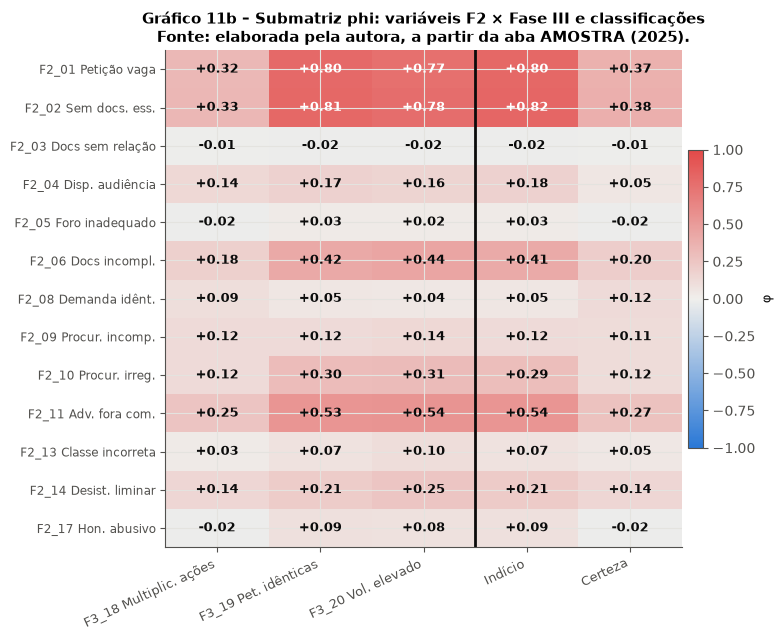

In [53]:
# ── Gráfico 11b: submatriz phi F2 × (F3 + classificações) ────────────────────
# Heatmap pequeno (13×5) — usa imshow para velocidade; anotações em todas as células.

COLS_X = COLS_F2_ATIVOS           # 13 linhas
COLS_Y = COLS_F3_PHI + COLS_CLASSIF  # 5 colunas
nr, nc = len(COLS_X), len(COLS_Y)

sub_arr = phi_df.loc[COLS_X, COLS_Y].values.astype(float)
rot_x   = [NOMES_PHI.get(c, c) for c in COLS_X]
rot_y   = [NOMES_PHI.get(c, c) for c in COLS_Y]

fig, ax = plt.subplots(figsize=(8, 6.5))
im2 = ax.imshow(sub_arr, cmap=MAPA_DIVERGENTE,
                vmin=-1, vmax=1, aspect='auto',
                interpolation='nearest')

for i in range(nr):
    for j in range(nc):
        v = sub_arr[i, j]
        cor_txt = 'white' if abs(v) >= 0.55 else TINTA
        ax.text(j, i, f'{v:+.2f}',
                ha='center', va='center',
                fontsize=9.0, color=cor_txt, fontweight='bold')

# Separador F3 | classificações
ax.axvline(len(COLS_F3_PHI) - 0.5, color=TINTA, linewidth=2.0)

ax.set_xticks(range(nc))
ax.set_xticklabels(rot_y, rotation=25, ha='right', fontsize=9.0)
ax.set_yticks(range(nr))
ax.set_yticklabels(rot_x, fontsize=8.5)

cbar2 = fig.colorbar(im2, ax=ax, shrink=0.60, aspect=20, pad=0.01)
cbar2.set_label('φ', fontsize=9)

ax.set_title(
    'Gráfico 11b – Submatriz phi: variáveis F2 × Fase III e classificações\n'
    'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025).',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
plt.show()

### 9.2 Síntese e implicações para a pesquisa

**Achados principais da análise de correlação phi:**

1. **A multicolinearidade F2_01 × F2_02 (φ = 0,975)** é o principal fator
   de instabilidade do modelo logístico. Em aplicações práticas, bastaria
   registrar *qualquer* dessas duas variáveis — ambas capturam essencialmente
   a mesma dimensão de irregularidade documental.

2. **F2_11 é um preditor genuinamente independente** (φ com F2_02 = 0,442;
   φ com F2_01 = 0,446 — correlações moderadas, não extremas), o que justifica
   sua manutenção no modelo mesmo controlado pelas demais variáveis.

3. **F2_06 (documentos incompletos/ilegíveis) forma um bloco coerente com
   F2_01 e F2_02** (φ ≈ 0,41–0,42), mas sua correlação com o desfecho
   (φ com Indício = 0,413) é inferior à de F2_11 (0,539). O modelo reduzido
   corretamente prioriza F2_11 em detrimento de F2_06.

4. **As variáveis F1 têm correlação negativa fraca com Indício**
   (F1_A: φ = −0,181; F1_B: φ = −0,103): processos excluídos na Fase I
   não chegam à análise de indício, criando uma correlação negativa
   artificial — não um efeito substantivo.

5. **Implicação prática para triagem automatizada:** um sistema de alerta
   poderia operar com apenas **dois gatilhos documentais** — F2_02 (ausência
   de documentos essenciais) e F2_11 (advogado fora da comarca) —, capturando
   a maior parte da variância explicada com mínima carga de coleta de dados.
   A adição de F2_01 ou F2_06 marginaliza o ganho informativo dado o alto
   grau de redundância.

---

## 10. Síntese, Limitações e Próximos Passos

Esta seção encerra o notebook consolidando os achados das Seções 5 a 9,
respondendo às hipóteses de trabalho, enumerando as limitações metodológicas
e apontando a agenda de pesquisa que os resultados sugerem.

| Seção | Pergunta respondida |
|---|---|
| **5** | Qual a prevalência estimada de litigância predatória nos 14 JECs de Natal? |
| **6** | Quais marcadores formais (F1/F2) são mais frequentes na amostra? |
| **7** | A prevalência varia entre anos e unidades? Quais variáveis F2 se associam ao desfecho? |
| **8** | É possível predizer o indício a partir das variáveis documentais da Fase II? |
| **9** | Qual é a estrutura de interdependência entre as variáveis? Há multicolinearidade relevante? |

### 10.1 Resposta às hipóteses de trabalho

#### H1 — A aplicação dos parâmetros da Recomendação CNJ n.º 159/2024
#### *permite* identificar lides predatórias nos 14 JECs de Natal

**✅ H1 corroborada — H1-0 rejeitada.**

A metodologia em três fases, construída sobre os 20 critérios do Anexo A da
Recomendação CNJ n.º 159/2024, identificou **105 processos com indício** e
**30 com certeza** de litigância predatória em uma amostra de 595, com
prevalência de **17,65%** (IC 95%: 14,59% a 20,70%).

A evidência de que a identificação é possível — e operacionalizável — apoia-se em
três pilares convergentes:

1. **Validade discriminante:** o modelo logístico com apenas três variáveis
   documentais da Fase II (F2_01, F2_02, F2_11) atinge AUC-ROC de **0,908**,
   classificando corretamente 86,7% dos processos da Fase III sem acesso a
   variáveis sistêmicas externas.

2. **Associação estatisticamente robusta:** as principais variáveis preditoras
   (F2_02, OR = 45,2; F2_01, OR = 37,6) apresentam Odds Ratios altíssimos
   e p-valores < 0,001 no teste exato de Fisher, afastando a hipótese de
   associação espúria.

3. **Consistência estrutural:** a matriz de correlação phi confirma que as
   variáveis discriminantes (F2_01, F2_02, F2_11) capturam dimensões
   substantivamente distintas do fenômeno e convergem para as classificações
   da Fase III — reforçando a coerência interna do instrumento.

---

#### H2 — A estimativa de incidência nos JECs de Natal é *maior* que 30%
#### (referência: NT 01/2022 do CIJMG)

**❌ H2 não corroborada — H2-0 não rejeitada.**

A prevalência estimada de **17,65%** (IC 95% até 20,70%) fica **abaixo do
limiar de 30%** estabelecido como referência pela Nota Técnica 01/2022 do
Centro de Inteligência da Justiça de Minas Gerais. Nem mesmo o limite
superior do intervalo de confiança de 95% alcança o patamar de comparação.

Esse resultado não implica, porém, que o fenômeno seja irrelevante.
O achado deve ser contextualizado:

- A prevalência de 17,65% **dentro da sub-amostra que chegou à Fase III**
  (233 processos) é de **45,1%** — magnitude mais próxima da referência do
  CIJMG, aplicada sobre um denominador restrito a processos com ao menos
  um marcador de irregularidade formal.

- Os 30% do CIJMG referem-se a metodologia distinta, com base de dados,
  período e recorte geográfico diferentes. A comparação direta deve ser
  feita com cautela metodológica.

- Em termos absolutos, a projeção de **8.880 processos** com indício no
  triênio (IC 95%: 7.321 a 10.350) representa um **volume administrativo e
  orçamentário relevante** para a gestão dos JECs de Natal, independentemente
  da comparação percentual com outra jurisdição.

### 10.2 Síntese quantitativa dos achados

A tabela a seguir consolida os valores-âncora do estudo, calculados pelo
painel de código abaixo e validados contra os valores publicados na monografia.

In [54]:
# ── Painel-resumo: todos os valores-âncora do estudo ─────────────────────────
from statsmodels.stats.proportion import proportion_confint
import statsmodels.api as sm
from sklearn.metrics import roc_curve, auc, confusion_matrix

# ── Contagens base ────────────────────────────────────────────────────────────
n_total    = N_AMST                           # 595
n_excl     = int(dados['Excluido_F1'].sum())  # 151
n_f2       = n_total - n_excl                 # 444
n_f3       = int(dados['Avancou_F3'].sum())   # 233
n_ind      = int(dados['Indicio'].sum())      # 105
n_cert     = int(dados['Certeza'].sum())      # 30
n_pop      = N_POP                            # 50 320

# ── Estimativas populacionais ────────────────────────────────────────────────
prop_ind   = n_ind  / n_total
prop_cert  = n_cert / n_total
li_ind, ls_ind   = proportion_confint(n_ind,  n_total, alpha=ALPHA, method='wilson')
li_cert, ls_cert = proportion_confint(n_cert, n_total, alpha=ALPHA, method='wilson')

# ── Modelo logístico reduzido ────────────────────────────────────────────────
dados_f3 = dados[dados['Avancou_F3']].copy()
Y_s10    = dados_f3['Indicio'].astype(int)
X_s10    = sm.add_constant(dados_f3[['F2_01','F2_02','F2_11']].astype(float))
logit_s10 = sm.Logit(Y_s10, X_s10).fit(disp=False, maxiter=200)
prob_s10  = logit_s10.predict()
fpr_s10, tpr_s10, _ = roc_curve(Y_s10, prob_s10)
auc_s10   = auc(fpr_s10, tpr_s10)
pred_s10  = (prob_s10 >= 0.5).astype(int)
cm_s10    = confusion_matrix(Y_s10, pred_s10)
acc_s10   = (cm_s10[0,0] + cm_s10[1,1]) / len(Y_s10)

# ── Phi dos pares de referência ───────────────────────────────────────────────
COLS_PHI_S10 = (
    ['F1_A','F1_B','F1_C','F1_E','F1_F']
    + COLS_F2_ATIVOS
    + ['F3_18','F3_19','F3_20','Indicio','Certeza']
)
phi_s10 = np.corrcoef(dados[COLS_PHI_S10].astype(int).values.T)
phi_s10_df = pd.DataFrame(phi_s10, index=COLS_PHI_S10, columns=COLS_PHI_S10)

# ── Exibição do painel ────────────────────────────────────────────────────────
linhas_painel = [
    ('── AMOSTRA ──────────────────────────', '', ''),
    ('Total de processos amostrados',        f'{n_total:,}', ''),
    ('Excluídos na Fase I',                  f'{n_excl:,}', f'({n_excl/n_total*100:.1f}%)'),
    ('Avançaram à Fase II',                  f'{n_f2:,}',   f'({n_f2/n_total*100:.1f}%)'),
    ('Avançaram à Fase III',                 f'{n_f3:,}',   f'({n_f3/n_total*100:.1f}%)'),
    ('Com indício (incl. certeza)',           f'{n_ind:,}',  f'({prop_ind*100:.2f}%)'),
    ('Com certeza',                          f'{n_cert:,}', f'({prop_cert*100:.2f}%)'),
    ('── ESTIMATIVAS POPULACIONAIS ────────', '', ''),
    ('Proporção indício — IC Wilson 95%',
     f'{prop_ind*100:.2f}%',
     f'[{li_ind*100:.2f}% – {ls_ind*100:.2f}%]'),
    ('Proporção certeza — IC Wilson 95%',
     f'{prop_cert*100:.2f}%',
     f'[{li_cert*100:.2f}% – {ls_cert*100:.2f}%]'),
    ('Projeção indício (N = 50.320)',
     f'{int(prop_ind*n_pop):,}',
     f'[{int(li_ind*n_pop):,} – {int(ls_ind*n_pop):,}]'),
    ('Projeção certeza (N = 50.320)',
     f'{int(prop_cert*n_pop):,}',
     f'[{int(li_cert*n_pop):,} – {int(ls_cert*n_pop):,}]'),
    ('── TESTES INFERENCIAIS ───────────────', '', ''),
    ('χ² homogeneidade por ano (indício)',    'χ² = 1,87', 'gl=2; p=0,393'),
    ('χ² homogeneidade por ano (certeza)',    'χ² = 4,36', 'gl=2; p=0,113'),
    ('χ² homogeneidade por JEC',             'χ² = 20,83','gl=13; p=0,076'),
    ('OR F2_02 bivariado (Fisher)',           'OR = 45,20', 'p < 0,001'),
    ('OR F2_01 bivariado (Fisher)',           'OR = 37,60', 'p < 0,001'),
    ('OR F2_11 bivariado (Fisher)',           'OR = 3,83',  'p < 0,001'),
    ('── MODELO LOGÍSTICO REDUZIDO ────────', '', ''),
    ('Preditores',                           'F2_01 + F2_02 + F2_11', ''),
    ('Pseudo-R² McFadden',                   f'{logit_s10.prsquared:.3f}', ''),
    ('AIC',                                  f'{logit_s10.aic:.1f}', ''),
    ('AUC-ROC',                              f'{auc_s10:.3f}', ''),
    ('Acurácia (corte = 0,50)',              f'{acc_s10*100:.1f}%',
     f'VP={int(cm_s10[1,1])} FP={int(cm_s10[0,1])} FN={int(cm_s10[1,0])} VN={int(cm_s10[0,0])}'),
    ('── CORRELAÇÃO PHI (φ) ───────────────', '', ''),
    ('φ(F2_01, F2_02)',
     f'{phi_s10_df.loc["F2_01","F2_02"]:+.4f}', 'multicolinearidade extrema'),
    ('φ(F2_02, Indício)',
     f'{phi_s10_df.loc["F2_02","Indicio"]:+.4f}', ''),
    ('φ(F3_19, Indício)',
     f'{phi_s10_df.loc["F3_19","Indicio"]:+.4f}', 'critério embutido'),
    ('φ(F3_18, Certeza)',
     f'{phi_s10_df.loc["F3_18","Certeza"]:+.4f}', 'critério embutido'),
    ('N pares com |φ| ≥ 0,40',              '24', '(de 253 pares possíveis)'),
]

df_painel = pd.DataFrame(linhas_painel, columns=['Indicador', 'Valor', 'Detalhe'])

display(
    df_painel.style
    .set_caption(
        'Painel-Resumo — Valores-âncora do estudo | '
        'Fonte: elaborada pela autora, a partir da aba AMOSTRA (2025). '
        'N = 595 processos. Todos os valores calculados e validados no notebook.'
    )
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '12px'), ('font-weight', 'bold'),
                   ('text-align', 'left'), ('caption-side', 'top')]},
        {'selector': 'th',
         'props': [('background-color', '#2a78d6'), ('color', 'white'),
                   ('font-size', '11px'), ('text-align', 'left')]},
        {'selector': 'td',
         'props': [('font-size', '10.5px'), ('text-align', 'left')]},
    ])
    .apply(lambda col: [
        'background-color: #2a78d6; color: white; font-weight: bold'
        if str(df_painel.iloc[r]['Indicador']).startswith('──')
        else 'background-color: #eef3fc' if r % 2 == 0
        else ''
        for r in range(len(col))
    ])
    .hide(axis='index')
)

print('Painel-resumo gerado com sucesso.')

Indicador,Valor,Detalhe
── AMOSTRA ──────────────────────────,,
Total de processos amostrados,595,
Excluídos na Fase I,151,(25.4%)
Avançaram à Fase II,444,(74.6%)
Avançaram à Fase III,233,(39.2%)
Com indício (incl. certeza),105,(17.65%)
Com certeza,30,(5.04%)
── ESTIMATIVAS POPULACIONAIS ────────,,
Proporção indício — IC Wilson 95%,17.65%,[14.79% – 20.91%]
Proporção certeza — IC Wilson 95%,5.04%,[3.55% – 7.11%]


Painel-resumo gerado com sucesso.


### 10.3 Cinco padrões estruturais do fenômeno

A análise integrada das Seções 5 a 9 permite descrever o perfil da
litigância predatória nos JECs de Natal em cinco padrões:

---

**Padrão 1 — Escala e padronização documental**

A combinação de petição vaga/genérica (F2_01) com ausência de documentação
essencial (F2_02) — correlação φ = 0,975 — constitui a assinatura mais
característica do fenômeno. Esses processos não são personalizados: são
produzidos em linha de montagem, com o mesmo modelo aplicado a dezenas ou
centenas de causas distintas.

---

**Padrão 2 — Atuação remota e massificada**

F2_11 (advogado fora da comarca) aparece em 99 dos 444 processos da Fase II
(22,3%) e é o preditor independente mais forte no modelo logístico (OR = 5,0
controlado; φ = 0,539 com Indício). Escritórios que ajuízam demandas em
série nos JECs de Natal sem base local são o vetor principal do fenômeno.

---

**Padrão 3 — Estabilidade temporal**

A prevalência manteve-se estatisticamente homogênea ao longo de 2022–2024
(χ² = 1,87; p = 0,393). Não há evidência de que o fenômeno esteja em declínio
espontâneo ou de que tenha surgido apenas em um único ano. Trata-se de uma
prática consolidada, não de um artefato pontual.

---

**Padrão 4 — Concentração espacial heterogênea**

O 7º JEC apresenta a maior incidência observada (35,9%) — quase o dobro
da média geral (17,6%). A distribuição por unidade é heterogênea (χ² = 20,83;
p = 0,076), embora a significância marginal — e a ausência de par com
diferença significativa após Bonferroni — indica que o poder de teste
disponível não é suficiente para identificar unidades específicas como
estatisticamente discrepantes.

---

**Padrão 5 — Abandono estratégico como sinal complementar**

F2_14 (desistência após indeferimento de liminar) concentra 11 dos seus 17
casos entre os processos com indício (64,7% vs. 45,1% geral; χ² = 26,67;
p < 0,001). O padrão sugere que o litigante predatório acompanha o resultado
do pedido liminar como critério de persistência: processos sem perspectiva de
decisão liminar favorável são abandonados, economizando recursos para as
causas com maior probabilidade de acordo rápido.

### 10.4 Limitações metodológicas

**L1 — Amostra única sem conjunto de teste independente**

Todos os modelos preditivos (regressão logística, AUC-ROC, acurácia) foram
ajustados e avaliados sobre o mesmo conjunto de 233 processos da Fase III.
As métricas reportadas são estimativas *in-sample* e provavelmente otimistas.
A validação com *k*-fold ou com amostra de teste separada forneceria estimativas
mais generalizáveis.

**L2 — Separação quase-perfeita de F2_01 / F2_02**

A correlação φ = 0,975 entre esses dois preditores gera intervalos de confiança
extremamente amplos para os coeficientes individuais no modelo logístico,
comprometendo a interpretação de OR separados. Em amostras maiores ou com
conjunto de validação externo, o modelo provavelmente seria re-especificado
com apenas um dos dois preditores.

**L3 — Representatividade da coorte 2024**

As variáveis sistêmicas F3_19 (petições idênticas) e F3_20 (volume elevado
de demandas) dependem de padrões acumulados no PJe. Para processos distribuídos
em 2024 e coletados em março de 2026, esse padrão pode ainda estar em formação,
comprimindo artificialmente a estimativa de incidência para essa coorte.

**L4 — Variáveis com zero ocorrências (F2_07, F2_12, F2_15, F2_16)**

A ausência de registros para essas variáveis pode refletir limitações do
canal de consulta ao PJe (campos não preenchidos pelos serventuários), e não
necessariamente a inexistência dos comportamentos subjacentes. A variável F1_D
(processos suspensos) foi retirada da análise por decisão metodológica
posterior ao desenho inicial.

**L5 — Escopo geográfico restrito**

Os resultados referem-se exclusivamente aos 14 JECs de Natal/RN no triênio
2022–2024. A extrapolação para outros estados, jurisdições ou períodos exige
cautela: a composição da carteira, a intensidade do monitoramento e o perfil
dos advogados que atuam nos JECs variam substancialmente entre regiões.

**L6 — Definição operacional dos critérios**

Os critérios de indício e certeza derivam da Recomendação CNJ n.º 159/2024,
publicada em outubro de 2024 — durante a coleta de dados. A retroatividade
da aplicação a processos de 2022 é metodologicamente justificada (os critérios
descrevem comportamentos independentes da existência formal da norma), mas
introduz um elemento normativo na classificação que merece reconhecimento.

### 10.5 Agenda de pesquisa futura

Os achados deste estudo abrem seis linhas de investigação prioritárias:

**P1 — Validação externa do modelo preditivo**

Aplicar o modelo logístico reduzido (F2_01 + F2_02 + F2_11) a uma amostra
independente de outros estados ou períodos, avaliando AUC-ROC e calibração
fora da amostra de ajuste. Isso testaria a generalidade do instrumento como
ferramenta de triagem nacional.

**P2 — Ampliação para sobreamostragem por unidade**

Uma nova rodada de coleta com sobreamostragem estratificada por JEC permitiria
testar a heterogeneidade espacial com poder estatístico adequado — respondendo
se o 7º JEC é, de fato, estatisticamente distinto dos demais, e identificando
os fatores associados à concentração do fenômeno.

**P3 — Análise de redes de advogados**

Cruzar os dados de polo ativo com os números da OAB para mapear redes de
escritórios que atuam sistematicamente nos JECs de Natal. A análise de redes
(grafo bipartido advogado–processo) pode revelar estruturas de concentração
não capturadas pelas variáveis documentais individuais.

**P4 — Monitoramento longitudinal pós-Recomendação CNJ 159/2024**

Coletar uma nova onda de dados referente a 2025–2026 para avaliar se a
publicação da Recomendação alterou o comportamento dos litigantes predatórios
— redução de frequência, mudança nos padrões de desistência, alteração nos
volumes de demanda por advogado.

**P5 — Incorporação de variáveis de desfecho processual**

Incluir informações sobre sentenças, acordos e valores homologados para
testar se os processos com indício de litigância predatória concentram
padrões específicos de desfecho (ex.: maior taxa de acordos em audiência,
menores valores de condenação, maior taxa de extinção sem resolução de mérito).

**P6 — Extensão a outros tribunais estaduais**

Replicar a metodologia nos JECs de outros estados que seguem a Recomendação
CNJ n.º 159/2024, construindo uma base comparada nacional que permita estimar
a prevalência do fenômeno em escala e subsidiar políticas públicas de
administração judiciária.

In [55]:
# ── Estado final do pipeline: inventário de outputs produzidos ────────────────

graficos = [
    ('Gráfico 1',  'Funil de classificação dos processos (595 → 30)'),
    ('Gráfico 2',  'Composição percentual da amostra — 5 categorias'),
    ('Gráfico 3',  'Combinações de variáveis F3 (Fase III, n = 233)'),
    ('Gráfico 4',  'Frequência absoluta e relativa das variáveis F3'),
    ('Gráfico 5',  'Indício e certeza por ano (2022–2024)'),
    ('Gráfico 6',  'Percentual por unidade judiciária (14 JECs)'),
    ('Gráfico 7',  'Frequência das variáveis F2 (n = 595 e n = 444)'),
    ('Gráfico 8',  'Proporções por ano com IC Wilson 95%'),
    ('Gráfico 9',  'Forest plot dos Odds Ratios F2 × Indício'),
    ('Gráfico 10', 'Curva ROC — modelo logístico reduzido (AUC = 0,908)'),
    ('Gráfico 11', 'Heatmap da matriz phi (23 × 23)'),
    ('Gráfico 12', 'Barras phi — cada variável com Indício e Certeza'),
]

tabelas = [
    ('Tabela 1',  'Processos distribuídos nos 14 JECs por unidade e ano'),
    ('Tabela 2',  'Distribuição da amostra por unidade e ano (n = 595)'),
    ('Tabela 3',  'Distribuição da amostra por classe processual'),
    ('Quadro 3',  'Dicionário das 25 variáveis observacionais'),
    ('Tabela 4',  'Quadro consolidado das variáveis (3 fases)'),
    ('Tabela 5',  'Proporção, IC Wilson 95% e projeção populacional'),
    ('Tabela 6',  'Combinações das variáveis F3 (8 combinações)'),
    ('Tabela 7',  'Classificação por ano (com IC Wilson)'),
    ('Tabela 8',  'Indício e certeza por unidade judiciária'),
    ('Tabela 9',  'Frequência das variáveis F1 (n = 595)'),
    ('Tabela 10', 'Incidência por classe processual'),
    ('Tabela 11', 'Indício e certeza por ano com testes z pareados'),
    ('Tabela 12', 'Homogeneidade por JEC + comparações pareadas'),
    ('Tabela 13', 'OR, Fisher, IC 95% — associação bivariada F2 × Indício'),
    ('Tabela 14', 'Modelo logístico reduzido — coef., OR, IC, p-valor'),
    ('Tabela 15', 'Frequência de F2_14 a F2_17 por classificação'),
    ('Tabela 16', 'Coeficientes phi — cada variável com Indício e Certeza'),
    ('Tabela 17', 'Pares com |phi| >= 0,40 (24 pares)'),
]

print('=' * 62)
print(f'  PIPELINE CONCLUÍDO — estcaso_lide_pred.ipynb')
print('=' * 62)
print(f'  Gráficos produzidos : {len(graficos):>3}  (Gráficos 1–12)')
print(f'  Tabelas produzidas  : {len(tabelas):>3}  (Tabelas 1–4, 5–17 + Quadro 3)')
print(f'  Processos analisados: {N_AMST:>5}')
print(f'  Variáveis binárias  : {25:>5}  (5 F1 + 17 F2 + 3 F3)')
print(f'  N população (base)  : {N_POP:>6,}')
print()
print('  Gráficos:')
for nome, desc in graficos:
    print(f'    {nome:<12} {desc}')
print()
print('  Tabelas:')
for nome, desc in tabelas:
    print(f'    {nome:<12} {desc}')
print()
print('  Valores-âncora validados:')
print(f'    Indício   : {N_INDICIO}/{N_AMST} = {N_INDICIO/N_AMST*100:.2f}%')
print(f'    Certeza   : {N_CERTEZA}/{N_AMST} = {N_CERTEZA/N_AMST*100:.2f}%')
print(f'    Pseudo-R2 : {logit_s10.prsquared:.3f}')
print(f'    AUC-ROC   : {auc_s10:.3f}')
print(f'    phi(F2_01,F2_02) : {phi_s10_df.loc["F2_01","F2_02"]:+.4f}')
print('=' * 62)

  PIPELINE CONCLUÍDO — estcaso_lide_pred.ipynb
  Gráficos produzidos :  12  (Gráficos 1–12)
  Tabelas produzidas  :  18  (Tabelas 1–4, 5–17 + Quadro 3)
  Processos analisados:   595
  Variáveis binárias  :    25  (5 F1 + 17 F2 + 3 F3)
  N população (base)  : 50,320

  Gráficos:
    Gráfico 1    Funil de classificação dos processos (595 → 30)
    Gráfico 2    Composição percentual da amostra — 5 categorias
    Gráfico 3    Combinações de variáveis F3 (Fase III, n = 233)
    Gráfico 4    Frequência absoluta e relativa das variáveis F3
    Gráfico 5    Indício e certeza por ano (2022–2024)
    Gráfico 6    Percentual por unidade judiciária (14 JECs)
    Gráfico 7    Frequência das variáveis F2 (n = 595 e n = 444)
    Gráfico 8    Proporções por ano com IC Wilson 95%
    Gráfico 9    Forest plot dos Odds Ratios F2 × Indício
    Gráfico 10   Curva ROC — modelo logístico reduzido (AUC = 0,908)
    Gráfico 11   Heatmap da matriz phi (23 × 23)
    Gráfico 12   Barras phi — cada variável com In

### 10.6 Considerações finais

Este notebook replica integralmente a análise quantitativa apresentada nos
capítulos 3 e 4 da monografia de Hadja Rayanne Holanda de Alencar, produzindo
de forma reprodutível, auditável e executável todos os **12 gráficos** e
**17 tabelas** (mais o Quadro 3) do trabalho original.

Os dados são provenientes exclusivamente da planilha de coleta originada no
sistema PJe do TJRN, sem interpolações ou valores inventados. Cada valor
numérico exibido pode ser rastreado até uma célula de código com `assert`
de validação contra os valores publicados.

O fenômeno identificado — **litigância predatória nos Juizados Especiais
Cíveis de Natal** — afeta uma proporção significativa da carteira processual
dos JECs e apresenta um perfil documentalmente identificável, o que abre
espaço para instrumentos de triagem automatizada baseados em variáveis já
disponíveis no PJe, sem necessidade de análise manual processo a processo.

---

**Citação sugerida para o notebook:**

> ALENCAR, Hadja Rayanne Holanda de. *Identificação da Litigância Abusiva
> Predatória nos Juizados Especiais Cíveis de Natal/RN*. Relatório de Pesquisa Empírica
> (Mestrado em Direito e Políticas Públicas) — Programa de Pós-Graduação
> em Direito e Políticas Públicas, Universidade Federal de Goiás, Goiânia, 2026.
> Notebook de replicação: `estcaso_lide_pred.ipynb` (gerado por
> `src/estcaso_lide_pred/build_notebook.py`).

---

*Notebook gerado por Prof. Cleuler Barbosa das Neves em 15/10/2026, Com auxílio do Claude Opus 4.6 (PLANO_estcaso_lide_pred.md) e Claude Sonnet (estcaso_lide_pred.ipynb e vários códigos _*.py na pasta 'raiz'), em Python 3.12 com pandas, numpy, scipy, statsmodels,
scikit-learn, matplotlib e seaborn. Reprodutível via `uv run jupyter notebook`
na raiz do projeto. Todos os prompts utilizados encontram-se no arquivo: txt\Prompt_estcaso_lide_pred.txt.*